# Digital Decellularizer

**Project 7.2 · Protein-centric generative modelling of tissue decellularization**

Modeling what happens to the placental proteome when a tissue is decellularized: which
proteins **survive** (remain in the ECM scaffold) and how their abundance **shifts**. This is
framed as a *conditional generative* problem over a per-protein retention trajectory,
not a flat classifier. 

The model learns a probability distribution of what a scaffold could look like. It is "aware" of the context. It uses the Conditioning (C) vector (tissue type, protein category, molecular weight) to inform its prediction. A "flat classifier" would just output a binary Yes/No (Will this protein survive?).

### Headline results (5-fold CV)

| Question | Best model | Metric | Honest baseline |
|---|---|---|---|
| How much does a protein shift? | **V10e** (Normalizing flows, no ESM) | Pearson r = **0.645 ± 0.013** | copy-native r ≈ 0.27 |
| Does a protein survive at all? | **V11e** (survival head, no ESM) | Δ-R² = **0.611 ± 0.009**, AUROC = **0.875** | GBM-12D Δ-R² ≈ 0.32 |

---

### How to run

1. `pip install -r requirements.txt`
2. Put the data in `data/` (see `requirements.txt` / README for the two files).
3. Run the notebook top to bottom (Kernel → Restart & Run All). A GPU is optional, CPU works but is slower.
4. The actionable deliverable — `results_retention_predictions.csv` — is written by the
   *Actionable Results* section near the end.

### Configuration

All paths and run settings live in **one place**: the `GlobalConfig` dataclass in the
*Setup* cell below (`data_path`, `cache_path`, `seed`, imputation settings). There are no
hardcoded absolute paths anywhere else in the notebook.

### Shared infrastructure

| Layer | Class | Role |
|---|---|---|
| Data | `ProteinDataProvider` | Loading, LOD imputation, scaling, stratified CV splits |
| Bundle | `DataBundle` | Typed container for `(X_nat, X_dec, C, prot_df, splits, extras)` |
| Train | `Trainer` | One unified epoch loop — calls `model.compute_loss()` per batch |
| Base | `BaseCVAE` | Shared `reparameterise`, `decorr_loss`, `aux_delta_loss`, MC-dropout |


In [85]:
# ── Standard library ─────────────────────────────────────────────────────────
import os, json, warnings, math
import copy, time
from abc import ABC, abstractmethod
from dataclasses import dataclass, field
from typing import Any, Callable, Dict, List, Optional, Tuple

# ── Numerics ─────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── ML ───────────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, NMF
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import mean_absolute_error, brier_score_loss
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.metrics import roc_auc_score, average_precision_score

# ── Statistics ───────────────────────────────────────────────────────────────
from scipy.stats import pearsonr, spearmanr, mannwhitneyu, ttest_ind, kruskal

# ── Visualisation ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from IPython.display import display, HTML

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=1.1)
print("All imports OK")

All imports OK


In [2]:
# ── Palette & visual constants ────────────────────────────────────────────────
PALETTE: Dict[str, str] = {
    "Amnion":        "#4C9BE8",
    "Basaltissue":   "#5DBB7E",
    "Chorion":       "#E86B4C",
    "UmbilicalCord": "#B87FE8",
    "Heart":         "#E8C44C",
}
STATE_COLORS: Dict[str, str] = {"native": "#2196F3", "decell": "#FF5722"}

# ── Global biology constants ──────────────────────────────────────────────────
TISS: List[str] = ["Amnion", "Basaltissue", "Chorion", "UmbilicalCord"]
HEART_REGION_COLS: List[str] = [
    "largeAtery", "coronaryArtery", "Atrium", "Ventricle", "AV-Valves", "SL-Valves"
]
METADATA_COLS: List[str] = [
    "GeneName", "UniProt", "Location", "MatrisomeDivision",
    "MatrisomeCategory", "match_in_heart",
]

@dataclass
class GlobalConfig:
    """Top-level runtime settings shared by all pipeline stages."""
    data_path:       str   = "data/placenta_annotated.csv"
    cache_path:      str   = "data/uniprot_features_cache.csv"
    min_detections:  int   = 3       # proteins detected in < this many samples -> dropped
    lod_quantile:    float = 0.01    # LOD imputation lower-percentile boundary
    lod_sigma:       float = 0.30    # LOD draw noise (Lazar et al. 2016)
    val_frac:        float = 0.10    # held-out fraction (stratified on is_matrisome)
    seed:            int   = 42

CFG = GlobalConfig()

# ── Device ────────────────────────────────────────────────────────────────────
device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(CFG.seed)
np.random.seed(CFG.seed)

print(f"Device : {device}")
print(f"Tissues: {TISS}")
print(f"Seed   : {CFG.seed}")

Device : cuda
Tissues: ['Amnion', 'Basaltissue', 'Chorion', 'UmbilicalCord']
Seed   : 42


In [25]:
# DataBundle — typed container passed from ProteinDataProvider to every model

@dataclass
class DataBundle:
    """
    Holds all arrays required to train and evaluate one model variant.

    Shapes (N = total proteins, D_nat = input dim, D_cond = cond dim):
        X_nat  : (N, D_nat)   scaled native features
        X_dec  : (N, 4)       scaled decell means (target)
        C      : (N, D_cond)  conditioning matrix
        prot_df: (N, *)       protein metadata DataFrame (aligned by row)
        tr_idx / val_idx      integer index arrays for 80/10 split
        tissue_deltas         list of 4 arrays shape (N,) — delta per tissue column
        extra                 any model-specific data (ESM, cat_idx, …)
    """
    X_nat:          np.ndarray
    X_dec:          np.ndarray
    C:              np.ndarray
    prot_df:        pd.DataFrame
    scaler_nat:     StandardScaler
    scaler_dec:     StandardScaler
    tr_idx:         np.ndarray
    val_idx:        np.ndarray
    tissue_deltas:  List[np.ndarray]      # one (N,) array per tissue
    extra:          Dict[str, Any] = field(default_factory=dict)

    # ── Convenience tensor helpers ────────────────────────────────────────────
    def to_float(self, arr: np.ndarray,
                 dev: torch.device = device) -> Tensor:
        """Convert numpy float32 array → device tensor."""
        return torch.tensor(arr, dtype=torch.float32).to(dev)

    def to_long(self, arr: np.ndarray,
                dev: torch.device = device) -> Tensor:
        """Convert numpy int64 array → long device tensor."""
        return torch.tensor(arr, dtype=torch.long).to(dev)


# Trainer — unified epoch loop; calls model.compute_loss() per batch

@dataclass
class TrainingHistory:
    train_loss: List[float] = field(default_factory=list)
    val_loss:   List[float] = field(default_factory=list)

    def plot(self, label: str = "", ax: Optional[plt.Axes] = None) -> plt.Axes:
        ax = ax or plt.gca()
        ax.plot(self.train_loss, label="train", color="#2196F3", lw=1.5)
        ax.plot(self.val_loss,   label="val",   color="#FF5722", lw=1.5)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_title(f"{label} training curve")
        ax.legend()
        return ax


class Trainer:
    """
    Flexible training engine. Every model must implement:

        model.compute_loss(
            x_nat : Tensor,
            x_dec : Tensor,
            c     : Tensor,
            beta  : float,
            **extras_batch,       # optional: tissue_deltas_batch, x_esm, cat_idx …
        ) -> Tuple[Tensor, Dict[str, float]]

    Extras are sliced per-batch from DataBundle.extra tensors automatically.
    """

    def __init__(
        self,
        model:    nn.Module,
        lr:       float,
        epochs:   int,
        batch:    int,
        max_beta: float,
        kl_warmup: int   = 100,
        weight_decay: float = 1e-5,
        patience: int   = 0,           # 0 = no early stopping
        dev:      torch.device = device,
    ) -> None:
        self.model     = model.to(dev)
        self.lr        = lr
        self.epochs    = epochs
        self.batch     = batch
        self.max_beta  = max_beta
        self.kl_warmup = kl_warmup
        self.patience  = patience
        self.dev       = dev

        self.opt   = torch.optim.Adam(model.parameters(), lr=lr,
                                      weight_decay=weight_decay)
        self.sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            self.opt, T_max=epochs)

    # ── Internal helpers ──────────────────────────────────────────────────────
    def _t(self, a: np.ndarray) -> Tensor:
        return torch.tensor(a, dtype=torch.float32).to(self.dev)

    def _tl(self, a: np.ndarray) -> Tensor:
        return torch.tensor(a, dtype=torch.long).to(self.dev)

    def _beta(self, epoch: int) -> float:
        return min(self.max_beta, self.max_beta * epoch / max(self.kl_warmup, 1))

    # ── Main fit loop ─────────────────────────────────────────────────────────
    def fit(
        self,
        bundle:       DataBundle,
        verbose:      int = 50,          # print every N epochs (0 = silent)
        extra_keys:   List[str] = [],    # keys in bundle.extra to slice per-batch
        long_keys:    List[str] = [],    # keys that need to_long (e.g. cat_idx)
    ) -> TrainingHistory:
        """
        Run the full training loop.

        Extra arrays in bundle.extra listed in `extra_keys` are automatically
        sliced to the batch indices and passed as kwargs to model.compute_loss().
        """
        hist = TrainingHistory()

        tr, val = bundle.tr_idx, bundle.val_idx
        Xn_tr  = self._t(bundle.X_nat[tr]);   Xd_tr = self._t(bundle.X_dec[tr])
        C_tr   = self._t(bundle.C[tr])
        Xn_val = self._t(bundle.X_nat[val]);   Xd_val = self._t(bundle.X_dec[val])
        C_val  = self._t(bundle.C[val])

        extra_np: Dict[str, np.ndarray] = {
            k: bundle.extra[k] for k in extra_keys if k in bundle.extra
        }

        td_tr  = [self._t(td[tr])  for td in bundle.tissue_deltas]
        td_val = [self._t(td[val]) for td in bundle.tissue_deltas]

        best_val  = float("inf")
        best_sd   = None
        no_impr   = 0

        for ep in range(1, self.epochs + 1):
            beta = self._beta(ep)
            self.model.train()
            perm      = torch.randperm(Xn_tr.shape[0])
            ep_loss   = 0.0
            n_batches = 0

            for i in range(0, Xn_tr.shape[0], self.batch):
                bi = perm[i : i + self.batch]

                # Slice batch arrays
                xn_b = Xn_tr[bi]; xd_b = Xd_tr[bi]; c_b = C_tr[bi]
                td_b = [td[bi] for td in td_tr]

                # Slice any model-specific extras
                ex_b: Dict[str, Tensor] = {}
                for k, arr in extra_np.items():
                    bi_np = bi.cpu().numpy()
                    conv  = self._tl if k in long_keys else self._t
                    ex_b[k] = conv(arr[bi_np])

                self.opt.zero_grad()
                loss, _ = self.model.compute_loss(
                    xn_b, xd_b, c_b, beta,
                    tissue_deltas_batch=td_b,
                    **ex_b,
                )
                loss.backward()
                nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                self.opt.step()

                ep_loss   += loss.item()
                n_batches += 1

            self.sched.step()

            # Validation
            self.model.eval()
            with torch.no_grad():
                ex_val: Dict[str, Tensor] = {}
                for k, arr in extra_np.items():
                    conv = self._tl if k in long_keys else self._t
                    ex_val[k] = conv(arr[val])
                v_loss, _ = self.model.compute_loss(
                    Xn_val, Xd_val, C_val, beta,
                    tissue_deltas_batch=td_val,
                    **ex_val,
                )

            tr_l = ep_loss / max(n_batches, 1)
            vl_l = v_loss.item()
            hist.train_loss.append(tr_l)
            hist.val_loss.append(vl_l)

            if vl_l < best_val:
                best_val = vl_l
                best_sd  = {k: v.clone() for k, v in self.model.state_dict().items()}
                no_impr  = 0
            else:
                no_impr += 1

            if verbose > 0 and (ep == 1 or ep % verbose == 0 or ep == self.epochs):
                print(f"  ep {ep:4d}/{self.epochs} | tr {tr_l:.4f} | "
                      f"val {vl_l:.4f} | β={beta:.4f}")

            if self.patience > 0 and no_impr >= self.patience:
                print(f"  Early stop at epoch {ep} (no val improvement for {self.patience} epochs)")
                break

        if best_sd:
            self.model.load_state_dict(best_sd)
        print(f"  Done. Best val loss: {best_val:.5f}")
        return hist

print("DataBundle and Trainer defined.")

DataBundle and Trainer defined.


In [26]:
# UNIFORM EVALUATION FIGURES
# One function covers V1–V10; a separate one covers V11.
# Both are defined here so every model cell can call them directly.

_ECM_COL  = "#E86B4C"
_CEL_COL  = "#B4B2A9"
_TISS_PALETTE = {
    "Amnion":        "#4C9BE8",
    "Basaltissue":   "#5DBB7E",
    "Chorion":       "#E86B4C",
    "UmbilicalCord": "#B87FE8",
}

def plot_model_eval(model_label,
                    X_dec_raw,
                    X_pred_raw,
                    X_nat_raw,
                    prot_df_val,
                    metrics_dict,
                    extra_panel=None,
                    save=None):
    """
    Uniform 2-panel (+ optional C) evaluation figure for V1–V10.
    Panel A: Predicted vs true shift (Delta = decell - native), ECM highlighted.
    Panel B: Per-tissue Pearson r in Delta space.
    extra_panel: optional callable(ax) for a model-specific panel C (used by V3).
    """

    n_panels = 3 if extra_panel is not None else 2
    fig, axes = plt.subplots(1, n_panels, figsize=(4.8 * n_panels, 4.5))

    # ── Panel A: predicted vs true Delta ──────────────────────────────────────
    ax = axes[0]
    d_true = (X_dec_raw  - X_nat_raw).flatten()
    d_pred = (X_pred_raw - X_nat_raw).flatten()
    is_ecm = np.repeat(prot_df_val["is_matrisome"].values, X_dec_raw.shape[1])

    ax.scatter(d_true[~is_ecm], d_pred[~is_ecm],
               alpha=0.18, s=4, color=_CEL_COL, rasterized=True, label="Cellular")
    ax.scatter(d_true[is_ecm],  d_pred[is_ecm],
               alpha=0.55, s=7, color=_ECM_COL, rasterized=True, label="ECM")

    lim = max(abs(d_true).max(), abs(d_pred).max()) * 1.05
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=1.0, alpha=0.55)
    ax.axhline(0, color="gray", lw=0.5, alpha=0.4)
    ax.axvline(0, color="gray", lw=0.5, alpha=0.4)

    r_all, _ = pearsonr(d_true, d_pred)
    r_ecm, _ = pearsonr(d_true[is_ecm], d_pred[is_ecm])
    ax.set_xlabel("True Delta  (decell - native, log2)", fontweight="bold")
    ax.set_ylabel("Predicted Delta  (log2)", fontweight="bold")
    ax.set_title(f"A - Shift prediction\n(r={r_all:.3f}, r_ecm={r_ecm:.3f})",
                 fontsize=10, fontweight="bold")
    ax.legend(fontsize=8, markerscale=2)
    ax.grid(True, ls="--", alpha=0.25)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")

    # ── Panel B: per-tissue r bars ─────────────────────────────────────────────
    ax = axes[1]
    tiss_list = ["Amnion", "Basaltissue", "Chorion", "UmbilicalCord"]
    r_vals, ecm_vals = [], []
    dt_mat = d_true.reshape(-1, X_dec_raw.shape[1])
    dp_mat = d_pred.reshape(-1, X_dec_raw.shape[1])
    em_mat = is_ecm.reshape(-1, X_dec_raw.shape[1])

    for ti in range(len(tiss_list)):
        rt, _ = pearsonr(dt_mat[:, ti], dp_mat[:, ti])
        r_vals.append(float(rt))
        mask_t = em_mat[:, ti]
        if mask_t.sum() > 2:
            re_val, _ = pearsonr(dt_mat[mask_t, ti], dp_mat[mask_t, ti])
        else:
            re_val = float("nan")
        ecm_vals.append(re_val)

    x = np.arange(len(tiss_list)); w = 0.36
    tick_labels = ["Amnion", "Basalt.", "Chorion", "Umbilical\nCord"]
    bars = ax.bar(x - w/2, r_vals, w,
                  color=[_TISS_PALETTE[t] for t in tiss_list],
                  edgecolor="black", linewidth=0.5, label="Overall Delta-r")
    ax.bar(x + w/2, ecm_vals, w,
           color=[_TISS_PALETTE[t] for t in tiss_list],
           edgecolor="black", linewidth=0.5, alpha=0.45,
           hatch="///", label="ECM-only Delta-r")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(tick_labels, fontsize=8.5)
    ax.set_ylabel("Pearson r  (Delta space)", fontweight="bold")
    ax.set_title("B - Per-tissue shift prediction", fontsize=10, fontweight="bold")
    ax.legend(fontsize=8); ax.grid(True, axis="y", ls="--", alpha=0.35)
    for bar, val in zip(bars, r_vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                val + (0.012 if val >= 0 else -0.045),
                f"{val:.3f}", ha="center", fontsize=7.5, fontweight="bold")

    # ── Panel C: model-specific (optional) ────────────────────────────────────
    if extra_panel is not None:
        extra_panel(axes[2])

    r_o = metrics_dict.get("r_overall", r_all)
    r_e = metrics_dict.get("r_ecm",     r_ecm)
    r_c = metrics_dict.get("r_cellular", float("nan"))
    plt.suptitle(
        f"{model_label}  |  r={r_o:.3f}  r_ecm={r_e:.3f}  r_cel={r_c:.3f}",
        fontsize=11, fontweight="bold")
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=200, bbox_inches="tight")
    plt.show()


def plot_v11_eval(model_label,
                  det_prob_np,
                  d_true_np,
                  d_pred_np,
                  prot_df_val,
                  r2_delta, auroc,
                  save=None):
    """
    V11-specific uniform figure.
    Panel A: Survival probability histogram split by ECM vs cellular.
    Panel B: Per-tissue Delta-R2 bars with GBM-12D baseline.
    """

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

    # ── Panel A: survival probability distribution ─────────────────────────────
    ax = axes[0]
    is_ecm = prot_df_val["is_matrisome"].values
    p_mean = det_prob_np.mean(axis=1)
    ax.hist(p_mean[~is_ecm], bins=40, density=True, alpha=0.65,
            color=_CEL_COL, label=f"Cellular  (n={(~is_ecm).sum():,})",
            edgecolor="none")
    ax.hist(p_mean[is_ecm],  bins=40, density=True, alpha=0.80,
            color=_ECM_COL, label=f"ECM  (n={is_ecm.sum():,})",
            edgecolor="none")
    ax.axvline(0.5, color="black", ls="--", lw=1.2, label="Decision boundary")
    ax.set_xlabel("Predicted survival probability p-hat", fontweight="bold")
    ax.set_ylabel("Density", fontweight="bold")
    ax.set_title("A - Survival head: predicted p-hat by class",
                 fontsize=10, fontweight="bold")
    ax.legend(fontsize=8.5); ax.grid(True, axis="y", ls="--", alpha=0.3)

    # ── Panel B: per-tissue Delta-R2 ──────────────────────────────────────────
    ax = axes[1]
    tiss_list = ["Amnion", "Basaltissue", "Chorion", "UmbilicalCord"]
    r2_tiss = []
    for ti in range(4):
        dt = d_true_np[:, ti]; dp = d_pred_np[:, ti]
        ss = ((dt - dp)**2).sum(); st = ((dt - dt.mean())**2).sum()
        r2_tiss.append(float(1 - ss / st) if st > 0 else float("nan"))

    bars = ax.bar(tiss_list, r2_tiss,
                  color=[_TISS_PALETTE[t] for t in tiss_list],
                  edgecolor="black", linewidth=0.6)
    ax.axhline(0,    color="black",   lw=0.8)
    ax.axhline(0.32, color="#E24B4A", ls="--", lw=1.2, label="GBM-12D baseline (0.32)")
    ax.set_ylabel("Delta-R2", fontweight="bold")
    ax.set_title("B - Per-tissue Delta-R2", fontsize=10, fontweight="bold")
    ax.set_xticklabels(["Amnion", "Basalt.", "Chorion", "Umbilical\nCord"], fontsize=8.5)
    ax.legend(fontsize=8); ax.grid(True, axis="y", ls="--", alpha=0.35)
    for bar, val in zip(bars, r2_tiss):
        ax.text(bar.get_x() + bar.get_width() / 2,
                val + 0.012, f"{val:.3f}",
                ha="center", fontsize=8, fontweight="bold")

    plt.suptitle(f"{model_label}  |  Delta-R2={r2_delta:.3f}  AUROC={auroc:.3f}",
                 fontsize=11, fontweight="bold")
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=200, bbox_inches="tight")
    plt.show()

# EvaluationEngine — all metrics, stats and plots in one place


_TISS_HEX = {
    "Amnion":        "#4C9BE8",
    "Basaltissue":   "#5DBB7E",
    "Chorion":       "#E86B4C",
    "UmbilicalCord": "#B87FE8",
}

def _card(inner_html, title="", accent="#534AB7"):
    t = (f'<div style="font-size:11px;font-weight:500;letter-spacing:.06em;'
         f'text-transform:uppercase;color:{accent};margin-bottom:10px">{title}</div>'
         if title else "")
    return (f'<div style="background:#fff;border:0.5px solid #ddd;border-radius:10px;'
            f'padding:14px 18px;margin:8px 0;font-family:system-ui,sans-serif;'
            f'font-size:13px;color:#1a1a1a">{t}{inner_html}</div>')

def _badge(text, bg, fg):
    return (f'<span style="background:{bg};color:{fg};font-size:11px;font-weight:500;'
            f'padding:2px 8px;border-radius:20px;display:inline-block;margin:2px 4px 2px 0">'
            f'{text}</span>')

def _sig_badge(p):
    if p < 0.001: return _badge("p<0.001 \u2713", "#E1F5EE", "#085041")
    if p < 0.01:  return _badge(f"p={p:.3f} \u2713", "#E1F5EE", "#085041")
    if p < 0.05:  return _badge(f"p={p:.3f} \u2713", "#FAEEDA", "#633806")
    return _badge(f"p={p:.3f}", "#F1EFE8", "#5F5E5A")

def _r_bar(r, max_w=120):
    pct   = max(0.0, min(1.0, abs(r)))
    color = "#4C9BE8" if r >= 0 else "#E24B4A"
    w     = int(pct * max_w)
    return (f'<span style="display:inline-block;background:{color};height:8px;'
            f'width:{w}px;border-radius:4px;vertical-align:middle;margin-right:6px">'
            f'</span><span style="font-variant-numeric:tabular-nums">{r:+.3f}</span>')

def _th(col):
    return (f'<th style="padding:5px 12px 5px 0;text-align:left;font-weight:500;'
            f'color:#888;font-size:11px;text-transform:uppercase">{col}</th>')

def _td(val, bold=False, align="left", min_w=None):
    fw  = "font-weight:500;" if bold else ""
    ta  = f"text-align:{align};"
    mw  = f"min-width:{min_w};" if min_w else ""
    return (f'<td style="padding:5px 10px 5px 0;vertical-align:middle;{fw}{ta}{mw}">' + str(val) + "</td>")

def _table(headers, rows_html):
    hdr = "<tr>" + "".join(_th(h) for h in headers) + "</tr>"
    return (f'<table style="border-collapse:collapse;width:100%;font-size:13px">'
            f'<thead>{hdr}</thead><tbody>{rows_html}</tbody></table>')

def _div_bar(label, value, n, color, scale=60):
    w = int(min(abs(value) * scale, 140))
    bar = (f'<span style="background:{color};height:10px;width:{w}px;'
           f'border-radius:5px;display:inline-block;vertical-align:middle;margin-right:6px">'
           f'</span>')
    return (f'<div style="display:flex;align-items:center;gap:10px;margin:5px 0">'
            f'<span style="width:120px;color:#555">{label}</span>'
            f'{bar}<span>{value:+.4f} '
            f'<span style="color:#888;font-size:11px">(n={n:,})</span></span></div>')


class EvaluationEngine:
    """Evaluation helpers — renders rich HTML cards in Jupyter."""

    @staticmethod
    def report(X_dec, X_pred, X_baseline, prot_df, label=""):

        is_mat  = prot_df["is_matrisome"].values
        metrics = {}
        rows    = ""

        for i, t in enumerate(TISS):
            r,   _ = pearsonr(X_dec[:, i], X_pred[:, i])
            mae    = mean_absolute_error(X_dec[:, i], X_pred[:, i])
            r_b, _ = pearsonr(X_dec[:, i], X_baseline[:, i])
            lift   = r - r_b
            dot    = f'<span style="color:{_TISS_HEX[t]};font-size:15px">\u25cf</span>'
            lift_b = (_badge(f"+{lift:.3f}", "#E1F5EE", "#085041") if lift >= 0
                      else _badge(f"{lift:.3f}", "#FCEBEB", "#791F1F"))
            # ── r is bolded; MAE de-emphasised (secondary metric) ──────────────
            mae_cell = f'<span style="color:#aaa;font-size:12px">{mae:.4f}</span>'
            rows += ("<tr>" + _td(f"{dot} {t}")
                     + _td(_r_bar(r), bold=True)
                     + _td(mae_cell)
                     + _td(f"{r_b:.3f}") + _td(lift_b) + "</tr>")
            metrics[f"r_{t}"] = r; metrics[f"mae_{t}"] = mae

        r_all, _ = pearsonr(X_dec.flatten(), X_pred.flatten())
        mae_all  = mean_absolute_error(X_dec, X_pred)
        r_base,_ = pearsonr(X_dec.flatten(), X_baseline.flatten())
        lift_all = r_all - r_base
        r_ecm,_  = pearsonr(X_dec[is_mat].flatten(),  X_pred[is_mat].flatten())
        r_cel,_  = pearsonr(X_dec[~is_mat].flatten(), X_pred[~is_mat].flatten())

        sep = f'<tr><td colspan="5" style="border-top:1px solid #eee;padding:3px 0"></td></tr>'
        lift_b2 = (_badge(f"+{lift_all:.3f}", "#E1F5EE", "#085041") if lift_all >= 0
                   else _badge(f"{lift_all:.3f}", "#FCEBEB", "#791F1F"))
        mae_all_cell = f'<span style="color:#aaa;font-size:12px">{mae_all:.4f}</span>'
        rows += sep
        rows += ("<tr>" + _td("<strong>Overall</strong>", bold=True)
                 + _td(_r_bar(r_all), bold=True)
                 + _td(mae_all_cell)
                 + _td(f"{r_base:.3f}") + _td(lift_b2) + "</tr>")
        rows += ("<tr>" + _td("ECM proteins") + _td(_r_bar(r_ecm), bold=True)
                 + _td("\u2014") + _td("\u2014") + _td("\u2014") + "</tr>")
        rows += ("<tr>" + _td("Cellular proteins") + _td(_r_bar(r_cel), bold=True)
                 + _td("\u2014") + _td("\u2014") + _td("\u2014") + "</tr>")

        summary = ('<div style="display:flex;gap:8px;flex-wrap:wrap;margin-top:12px">'
                   + _badge(f"r={r_all:.3f}", "#EEEDFE", "#3C3489")
                   + _badge(f"r_ecm={r_ecm:.3f}", "#E6F1FB", "#185FA5")
                   + _badge(f"r_cel={r_cel:.3f}", "#F1EFE8", "#5F5E5A")
                   + (_badge(f"lift={lift_all:+.3f}", "#E1F5EE", "#085041")
                      if lift_all >= 0 else
                      _badge(f"lift={lift_all:.3f}", "#FCEBEB", "#791F1F"))
                   + '</div>')

        display(HTML(_card(
            _table(["Tissue", "r (\u0394 space)", "MAE", "copy-native r", "lift"], rows)
            + summary,
            title=label or "Evaluation Report", accent="#534AB7"
        )))

        metrics.update({"r_overall": r_all, "mae_overall": mae_all,
                        "r_baseline": r_base, "r_ecm": r_ecm, "r_cellular": r_cel})
        return metrics

    @staticmethod
    def calibration(sigma, X_pred, X_dec, label=""):
        rows = ""
        for i, t in enumerate(TISS):
            err      = abs(X_pred[:, i] - X_dec[:, i])
            rho, p   = spearmanr(sigma[:, i], err)
            dot      = f'<span style="color:{_TISS_HEX[t]};font-size:15px">\u25cf</span>'
            rows += ("<tr>" + _td(f"{dot} {t}") + _td(_r_bar(rho, 80))
                     + _td(_sig_badge(p)) + "</tr>")
        display(HTML(_card(
            _table(["Tissue", "Spearman \u03c1", "significance"], rows),
            title=f"Uncertainty Calibration \u2014 {label}", accent="#185FA5"
        )))

    @staticmethod
    def ecm_uncertainty(sigma, is_mat, label=""):
        mean_s  = sigma.mean(axis=1)
        stat, p = mannwhitneyu(mean_s[is_mat], mean_s[~is_mat], alternative="two-sided")
        e_col   = "#E86B4C"; c_col = "#B4B2A9"
        inner   = (
            _div_bar("ECM",      mean_s[is_mat].mean(),  is_mat.sum(),  e_col, scale=200)
            + _div_bar("Cellular", mean_s[~is_mat].mean(), (~is_mat).sum(), c_col, scale=200)
            + f'<div style="margin-top:10px;font-size:12px;color:#555">'
            + f'Mann-Whitney U = {stat:.0f} &nbsp; {_sig_badge(p)}</div>'
        )
        display(HTML(_card(inner, title=f"ECM vs Cellular Uncertainty \u2014 {label}",
                           accent="#E86B4C")))
        return stat, p

    @staticmethod
    def latent_correlations(mu_z, prot_df, label=""):
        feats = {
            "mean \u0394":  prot_df["mean_delta"].values,
            "matrisome":    prot_df["is_matrisome"].astype(float).values,
            "n_tissues":    prot_df.get("n_tissues",
                            pd.Series(np.zeros(len(prot_df)))).values,
            "mol_wt":       prot_df.get("mol_weight",
                            pd.Series(np.zeros(len(prot_df)))).values,
        }
        rows  = ""
        found = 0
        for zi in range(mu_z.shape[1]):
            for fname, fvals in feats.items():
                if len(fvals) != len(mu_z): continue
                r, _ = pearsonr(mu_z[:, zi], fvals)
                if abs(r) > 0.05:
                    rows += "<tr>" + _td(f"Z{zi}") + _td(fname) + _td(_r_bar(r, 100)) + "</tr>"
                    found += 1
        inner = (_table(["Dim", "Feature", "Pearson r"], rows) if found
                 else '<span style="color:#888">No |r| > 0.05 found.</span>')
        display(HTML(_card(inner, title=f"Latent Correlations \u2014 {label}",
                           accent="#185FA5")))

    @staticmethod
    def collagen_heart(pred_shift, df_heart, ecm_mask, label=""):
        col_mask = (df_heart["MatrisomeCategory"] == "Collagens").values
        cel_mask = ~ecm_mask
        t, p     = ttest_ind(pred_shift[col_mask], pred_shift[cel_mask])
        c_col    = "#4C9BE8"; cc_col = "#E24B4A"
        inner    = (
            _div_bar("Collagens", pred_shift[col_mask].mean(), col_mask.sum(), c_col, 60)
            + _div_bar("Cellular", pred_shift[cel_mask].mean(), cel_mask.sum(), cc_col, 60)
            + f'<div style="margin-top:10px;font-size:12px;color:#555">'
            + f't = {t:.3f} &nbsp; {_sig_badge(p)}</div>'
        )
        display(HTML(_card(inner,
                    title=f"Heart Transfer \u2014 Collagen vs Cellular  {label}",
                    accent="#0F6E56")))
        return t, p

    @staticmethod
    def ecm_subclass(pred_shift, df_heart, ecm_mask, unc=None, label=""):
        cats = ["Collagens", "ECM Glycoproteins", "Proteoglycans",
                "ECM Regulators", "ECM-affiliated Proteins", "Secreted Factors"]
        cat_col = {
            "Collagens":               "#4C9BE8",
            "ECM Glycoproteins":       "#5DBB7E",
            "Proteoglycans":           "#E86B4C",
            "ECM Regulators":          "#B87FE8",
            "ECM-affiliated Proteins": "#F5C26B",
            "Secreted Factors":        "#888780",
        }
        rows = ""
        for cat in cats:
            mask = (df_heart["MatrisomeCategory"] == cat).values
            if mask.sum() < 2: continue
            mn   = pred_shift[mask].mean()
            bw   = int(min(abs(mn) * 60, 110))
            bc   = cat_col.get(cat, "#B4B2A9") if mn >= 0 else "#E24B4A"
            dot  = f'<span style="color:{cat_col.get(cat,"#888")};font-size:14px">\u25cf</span>'
            bar  = (f'<span style="background:{bc};height:8px;width:{bw}px;border-radius:4px;'
                    f'display:inline-block;vertical-align:middle;margin-right:6px"></span>'
                    f'{mn:+.3f}')
            cells_sub = [f"{dot} {cat}", str(mask.sum()), bar]
            cells = cells_sub
            if unc is not None: cells.append(f"{unc[mask].mean():.3f}")
            rows += "<tr>" + "".join(_td(c) for c in cells) + "</tr>"

        cel  = ~ecm_mask; mn_c = pred_shift[cel].mean()
        bw_c = int(min(abs(mn_c) * 60, 110))
        bc_c = "#4C9BE8" if mn_c >= 0 else "#E24B4A"
        bar_c = (f'<span style="background:{bc_c};height:8px;width:{bw_c}px;border-radius:4px;'
                 f'display:inline-block;vertical-align:middle;margin-right:6px"></span>'
                 f'{mn_c:+.3f}')
        n_cols = 4 if unc is not None else 3
        rows  += f'<tr><td colspan="{n_cols}" style="border-top:1px solid #eee;padding:3px 0"></td></tr>'
        cells  = ['\u25cf Cellular', str(cel.sum()), bar_c]
        if unc is not None: cells.append(f"{unc[cel].mean():.3f}")
        rows  += "<tr>" + "".join(_td(c) for c in cells) + "</tr>"

        hdrs = ["Category", "n", "Mean shift"] + (["Mean \u03c3"] if unc is not None else [])
        display(HTML(_card(_table(hdrs, rows),
                    title=label or "ECM Subclass Shift", accent="#0F6E56")))

    @staticmethod
    def plot_scatter(*args, **kwargs): pass   # replaced by plot_model_eval

    @staticmethod
    def plot_loss(*args, **kwargs): pass      # removed from model cells



class BaseCVAE(nn.Module, ABC):
    """
    Abstract base for all CVAE variants in this notebook.

    Subclasses must implement:
        forward(x, c, **kwargs)  → model-specific output tuple
        compute_loss(...)        → (total_loss, component_dict)
    """

    # ── Shared maths ──────────────────────────────────────────────────────────
    @staticmethod
    def reparameterise(mu: Tensor, logvar: Tensor) -> Tensor:
        """Reparameterisation trick: z = μ + ε·σ,  ε ~ N(0,I)."""
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    @staticmethod
    def decorr_loss(z: Tensor) -> Tensor:
        """
        Decorrelation regulariser.
        Penalises off-diagonal entries of the empirical covariance of z.
        Encourages each latent dimension to capture independent signal.
        """
        z_c  = z - z.mean(0, keepdim=True)
        cov  = (z_c.T @ z_c) / max(z.shape[0] - 1, 1)
        mask = ~torch.eye(z.shape[1], dtype=torch.bool, device=z.device)
        return cov[mask].pow(2).mean()

    @staticmethod
    def kl_free_bits(mu_z: Tensor, logvar_z: Tensor,
                     thresh: float) -> Tuple[Tensor, Tensor]:
        """
        KL divergence with free-bits threshold.
        KL_raw = -0.5 Σ(1 + log σ² - μ² - σ²)
        KL_fb  = clamp(KL_raw - thresh, min=0)    <- prevents posterior collapse
        """
        kl_raw = -0.5 * torch.mean(
            torch.sum(1 + logvar_z - mu_z.pow(2) - logvar_z.exp(), dim=-1))
        kl_fb  = torch.clamp(kl_raw - thresh, min=0.0)
        return kl_raw, kl_fb

    @staticmethod
    def nll_loss(mu_pred: Tensor, logsigma_pred: Tensor,
                 x_true: Tensor) -> Tensor:
        """
        Gaussian NLL:  L = 0.5 * (2 log σ + (y - μ)² / σ²)
        Numerically stable — operates on log σ directly.
        """
        var = torch.exp(2.0 * logsigma_pred) + 1e-8
        return 0.5 * torch.mean(2.0 * logsigma_pred + (x_true - mu_pred).pow(2) / var)

    @staticmethod
    def aux_delta_loss(mu_z: Tensor,
                       tissue_deltas_batch: List[Tensor]) -> Tensor:
        """
        Per-tissue auxiliary loss: forces Z_0…Z_{T-1} to correlate
        with the decellularisation Δ for each tissue.
        """
        if not tissue_deltas_batch:
            return torch.tensor(0.0, device=mu_z.device)
        n_tiss = len(tissue_deltas_batch)
        return sum(
            F.mse_loss(mu_z[:, i], td)
            for i, td in enumerate(tissue_deltas_batch)
        ) / n_tiss

    # ── Predict with MC dropout ───────────────────────────────────────────────
    def predict_mc(
        self,
        x: Tensor,
        c: Tensor,
        n_samples: int = 50,
        **kwargs,
    ) -> Tuple[Tensor, Tensor]:
        """
        Monte-Carlo dropout inference.
        Keeps dropout ACTIVE across n_samples passes, returns
        (mean_prediction, std_prediction).
        """
        self.train()   # keeps dropout on
        with torch.no_grad():
            preds = torch.stack(
                [self.forward(x, c, **kwargs)[0] for _ in range(n_samples)]
            )            # (n_samples, B, out_dim)
        self.eval()
        return preds.mean(0), preds.std(0)

    @abstractmethod
    def forward(self, x: Tensor, c: Tensor, **kwargs) -> Tuple[Tensor, ...]:
        ...

    @abstractmethod
    def compute_loss(
        self,
        x_nat: Tensor,
        x_dec: Tensor,
        c:     Tensor,
        beta:  float,
        **kwargs,
    ) -> Tuple[Tensor, Dict[str, float]]:
        ...

    def sigma_floor_regularizer(self, logsigma_out: Tensor) -> Tensor:
        """Penalizes sigma -> 0 to prevent overconfidence and numerical collapse."""
        return torch.exp(-2.0 * logsigma_out).mean()

EE = EvaluationEngine()   # singleton shorthand
print("EvaluationEngine and BaseCVAE defined.")

EvaluationEngine and BaseCVAE defined.


In [27]:
# ProteinDataProvider — all data loading and feature engineering
# Design principles:
#   - Fully vectorised — zero iterrows / per-protein loops
#   - Group-wise LOD imputation (each tissue x state has its own detection floor)
#   - Independent scalers for native and decell spaces (removes cross-space bias)
#   - Single stratified CV split shared across ALL models

import numpy as np
import pandas as pd
from typing import Optional, List, Dict, Tuple
from sklearn.preprocessing import StandardScaler

class ProteinDataProvider:
    """
    Loads, filters, imputes, and scales the placenta proteomics dataset.

    Usage::

        provider = ProteinDataProvider(CFG).load()
        bundle_v1 = provider.prepare_v1()
        bundle_v5 = provider.prepare_v5()
    """

    def __init__(self, cfg: GlobalConfig = CFG) -> None:
        self.cfg = cfg

        self.df:           Optional[pd.DataFrame] = None
        self.proteins_keep: Optional[pd.DataFrame] = None
        self.nat_cols:      Optional[List[str]]    = None
        self.dec_cols:      Optional[List[str]]    = None
        self.heart_df:      Optional[pd.DataFrame] = None

        # Shared CV split indices
        self._tr_idx:       Optional[np.ndarray]   = None
        self._val_idx:      Optional[np.ndarray]   = None

    # ── 1. Raw loading ────────────────────────────────────────────────────────
    def load(self) -> "ProteinDataProvider":
        """Read CSV, classify columns, add matrisome flags, compute missingness."""
        df = pd.read_csv(self.cfg.data_path, sep="\t")
        df.dropna(how="all", inplace=True)
        df.reset_index(drop=True, inplace=True)

        # Column classification (vectorised membership checks)
        num_cols      = [c for c in df.columns if c not in METADATA_COLS]
        placenta_cols = [c for c in num_cols if any(t in c for t in TISS)]

        self.nat_cols = [c for c in placenta_cols if "native" in c.lower()]
        self.dec_cols = [c for c in placenta_cols if "decell" in c.lower()]

        # Matrisome flags (vectorised isin)
        df["is_matrisome"] = df["MatrisomeDivision"].isin(
            ["Core matrisome", "Matrisome-associated"])

        # Detection count (how many samples is each protein non-NA and >0?)
        df["n_detected"] = (df[self.nat_cols] > 0).sum(axis=1)

        self.df = df

        # ── Filter ────────────────────────────────────────────────────────────
        self.proteins_keep = (
            df[df["n_detected"] >= self.cfg.min_detections]
            .copy()
            .reset_index(drop=True)
        )

        return self

    # ── 2. Imputation ─────────────────────────────────────────────────────────
    def _lod_impute(self, mat: np.ndarray) -> np.ndarray:
        """
        LOD-based imputation (Lazar et al. 2016, MCP).
        Missing / zero values → draws from N(μ_lod, σ_lod).
        Applied column-wise: each tissue-replicate has its own detection floor.
        """
        out = mat.copy().astype(np.float64)
        rng = np.random.default_rng(self.cfg.seed)
        for j in range(out.shape[1]):
            col = out[:, j]  # view of current column

            # Treat zeros as missing BEFORE capturing the mask
            col[col == 0] = np.nan

            miss_mask = np.isnan(col)
            detected  = col[~miss_mask]

            mu_lod = (np.quantile(detected, self.cfg.lod_quantile)
                    if len(detected) > 0 else 0.0)

            out[miss_mask, j] = rng.normal(mu_lod, self.cfg.lod_sigma, miss_mask.sum())

        return out.astype(np.float32)

    # ── 3. Vectorised feature extraction ──────────────────────────────────────
    def _tissue_means(self, df_mat: pd.DataFrame, cols_per_tissue: Dict[str, List[str]]) -> np.ndarray:
        """(N, 4) matrix of per-tissue means — fully vectorised."""
        return np.column_stack([
            df_mat[cols_per_tissue[t]].mean(axis=1).values for t in TISS
        ]).astype(np.float32)

    def _tissue_stds(self, df_mat: pd.DataFrame, cols_per_tissue: Dict[str, List[str]]) -> np.ndarray:
        """(N, 4) matrix of per-tissue standard deviations."""
        return np.column_stack([
            df_mat[cols_per_tissue[t]].std(axis=1).fillna(0).values for t in TISS
        ]).astype(np.float32)

    def _detection_rates(self, df_raw: pd.DataFrame, cols_per_tissue: Dict[str, List[str]]) -> np.ndarray:
        """(N, 4) detection-rate matrix: fraction of replicates > 0."""
        return np.column_stack([
            (df_raw[cols_per_tissue[t]] > 0).mean(axis=1).values for t in TISS
        ]).astype(np.float32)

    def _split(self, n: int, strat: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Stratified train/val split (created once, reused by all models)."""
        if self._tr_idx is not None:
            if len(self._tr_idx) + len(self._val_idx) == n:
                return self._tr_idx, self._val_idx

        rng   = np.random.default_rng(self.cfg.seed)
        idx   = np.arange(n)
        mat   = strat.astype(bool)
        tr1   = rng.choice(idx[mat],  int(mat.sum()  * (1 - self.cfg.val_frac)), replace=False)
        tr0   = rng.choice(idx[~mat], int((~mat).sum() * (1 - self.cfg.val_frac)), replace=False)
        tr    = np.sort(np.concatenate([tr1, tr0]))
        val   = np.setdiff1d(idx, tr)
        self._tr_idx  = tr
        self._val_idx = val
        return tr, val

    # ── 4. Conditioning matrix helpers ────────────────────────────────────────
    @staticmethod
    def _norm(x: np.ndarray) -> np.ndarray:
        return ((x - x.mean()) / (x.std() + 1e-8)).astype(np.float32)

    def _build_cond_v1(self, prot_df: pd.DataFrame) -> np.ndarray:
        """2D conditioning: [is_matrisome, is_cellular]."""
        is_mat = prot_df["is_matrisome"].values.astype(np.float32)
        return np.column_stack([is_mat, 1.0 - is_mat])

    def _build_cond_v5(self, prot_df: pd.DataFrame, cache: pd.DataFrame) -> np.ndarray:
        """9D conditioning for V5/V6/V8: 5 binary + 4 continuous."""
        p = prot_df.merge(cache, on="UniProt", how="left").fillna(0)
        loc_map = {"nuclear": 0, "cytoplasmic": 1, "cytoskeletal": 2,
                   "membrane": 3, "surfaceome": 4, "extracellular": 5}
        loc_enc = p["location"].map(loc_map).fillna(2).values.astype(np.float32)
        return np.column_stack([
            p["is_matrisome"].astype(float),
            (p["MatrisomeDivision"] == "Core matrisome").astype(float),
            p["is_collagen"].astype(float),
            (p["location"] == "extracellular").astype(float),
            (p["location"] == "surfaceome").astype(float),
            self._norm(np.log1p(p["mol_weight"].values.astype(float))),
            self._norm(p["seq_length"].values.astype(float)),
            self._norm(p["n_tissues"].values.astype(float)),
            self._norm(loc_enc),
        ]).astype(np.float32)

    # ── 5. prepare_v1 ─────────────────────────────────────────────────────────
    def prepare_v1(self) -> DataBundle:
        """
        Build DataBundle for V1/V3:
            X_nat : (N, 4)  scaled tissue means (native)
            X_dec : (N, 4)  scaled tissue means (decell)
            C     : (N, 2)  [is_matrisome, is_cellular]
        """
        pk = self.proteins_keep

        nat_cols_t = {t: [c for c in self.nat_cols if t in c] for t in TISS}
        dec_cols_t = {t: [c for c in self.dec_cols if t in c] for t in TISS}

        df_nat_raw = pk[sum(nat_cols_t.values(), [])].copy()
        df_dec_raw = pk[sum(dec_cols_t.values(), [])].copy()

        nat_imp = self._lod_impute(df_nat_raw.values)
        dec_imp = self._lod_impute(df_dec_raw.values)

        joint_mat    = np.concatenate([nat_imp, dec_imp], axis=1)
        joint_median = np.median(joint_mat, axis=1, keepdims=True)
        nat_imp      = nat_imp - joint_median
        dec_imp      = dec_imp - joint_median

        df_nat  = pd.DataFrame(nat_imp, columns=df_nat_raw.columns)
        df_dec  = pd.DataFrame(dec_imp, columns=df_dec_raw.columns)

        X_nat_raw = self._tissue_means(df_nat, nat_cols_t)
        X_dec_raw = self._tissue_means(df_dec, dec_cols_t)

        strat = pk["is_matrisome"].values
        tr, val = self._split(len(pk), strat)

        # Fit scalers strictly on training records
        sc_nat = StandardScaler().fit(X_nat_raw[tr])
        sc_dec = StandardScaler().fit(X_dec_raw[tr])
        X_nat  = sc_nat.transform(X_nat_raw).astype(np.float32)
        X_dec  = sc_dec.transform(X_dec_raw).astype(np.float32)

        delta_mat = X_dec_raw - X_nat_raw
        prot_df   = pk[METADATA_COLS + ["is_matrisome"]].copy().reset_index(drop=True)
        prot_df["mean_delta"] = delta_mat.mean(axis=1)
        prot_df["n_tissues"]  = (X_nat_raw > 0).sum(axis=1)
        for i, t in enumerate(TISS):
            prot_df[f"delta_{t}"] = delta_mat[:, i]
            prot_df[f"{t}_native"] = X_nat_raw[:, i]
            prot_df[f"{t}_decell"] = X_dec_raw[:, i]
        prot_df["is_collagen"] = (pk["MatrisomeCategory"] == "Collagens").values
        prot_df["location"]    = pk.get("Location", pd.Series([""] * len(pk))).values
        prot_df["MatrisomeDivision"]  = pk["MatrisomeDivision"].values
        prot_df["MatrisomeCategory"]  = pk["MatrisomeCategory"].values

        C = self._build_cond_v1(prot_df)
        tissue_deltas = [delta_mat[:, i] for i in range(4)]

        print(f"V1/V3 DataBundle: {len(prot_df):,} proteins — train {len(tr)}, val {len(val)}")
        print(f"  Input dim: 4 (tissue means)  |  Cond dim: 2")

        return DataBundle(
            X_nat=X_nat.astype(np.float32),
            X_dec=X_dec.astype(np.float32),
            C=C,
            prot_df=prot_df,
            scaler_nat=sc_nat, scaler_dec=sc_dec,
            tr_idx=tr, val_idx=val,
            tissue_deltas=tissue_deltas,
        )

    # ── 6. prepare_v5 ─────────────────────────────────────────────────────────
    def prepare_v5(self) -> DataBundle:
        """
        Build DataBundle for V5 (12D input, 9D conditioning).
            X_nat : (N, 12) = [4D means | 4D σ | 4D detection-rate] — scaled without leakage
            X_dec : (N, 4)  = scaled decell means
            C     : (N, 9)  = 5 binary + 4 continuous conditioning features
        """
        pk = self.proteins_keep

        nat_cols_t = {t: [c for c in self.nat_cols if t in c] for t in TISS}
        dec_cols_t = {t: [c for c in self.dec_cols if t in c] for t in TISS}

        df_nat_raw = pk[sum(nat_cols_t.values(), [])].copy()
        df_dec_raw = pk[sum(dec_cols_t.values(), [])].copy()
        nat_imp = self._lod_impute(df_nat_raw.values)
        dec_imp = self._lod_impute(df_dec_raw.values)

        joint_median = np.median(
            np.concatenate([nat_imp, dec_imp], axis=1), axis=1, keepdims=True
        )
        nat_imp = nat_imp - joint_median
        dec_imp = dec_imp - joint_median

        df_nat = pd.DataFrame(nat_imp, columns=df_nat_raw.columns)
        df_dec = pd.DataFrame(dec_imp, columns=df_dec_raw.columns)

        X_means   = self._tissue_means(df_nat,    nat_cols_t)
        X_stds    = self._tissue_stds(df_nat,     nat_cols_t)
        X_dets    = self._detection_rates(df_nat_raw, nat_cols_t)
        X_dec_raw = self._tissue_means(df_dec,    dec_cols_t)

        strat = pk["is_matrisome"].values
        tr, val = self._split(len(pk), strat)

        # Fit scalers strictly on training subset [tr]
        sc_nat = StandardScaler().fit(X_means[tr])
        sc_dec = StandardScaler().fit(X_dec_raw[tr])
        sc_std = StandardScaler().fit(X_stds[tr])

        X_means_sc = sc_nat.transform(X_means)
        X_dec_sc   = sc_dec.transform(X_dec_raw)
        X_stds_sc  = sc_std.transform(X_stds)
        
        # Detection rates centered using training baseline
        X_dets_sc  = (X_dets - X_dets[tr].mean(axis=0)).astype(np.float32)

        X_nat = np.concatenate([X_means_sc, X_stds_sc, X_dets_sc], axis=1).astype(np.float32)

        delta_mat = X_dec_raw - X_means
        prot_df   = pk[METADATA_COLS + ["is_matrisome"]].copy().reset_index(drop=True)
        prot_df["mean_delta"] = delta_mat.mean(axis=1)
        prot_df["n_tissues"] = (X_dets > 0).sum(axis=1)        
        prot_df["is_collagen"] = (pk["MatrisomeCategory"] == "Collagens").values
        prot_df["location"]    = pk.get("Location", pd.Series([""] * len(pk))).values
        prot_df["MatrisomeDivision"] = pk["MatrisomeDivision"].values
        prot_df["MatrisomeCategory"] = pk["MatrisomeCategory"].values
        for i, t in enumerate(TISS):
            prot_df[f"delta_{t}"]  = delta_mat[:, i]
            prot_df[f"{t}_native"] = X_means[:, i]
            prot_df[f"{t}_decell"] = X_dec_raw[:, i]

        cache = pd.read_csv(self.cfg.cache_path)[["UniProt", "mol_weight", "seq_length"]].fillna(0)
        C = self._build_cond_v5(prot_df, cache)

        sc_delta = StandardScaler().fit(delta_mat[tr])
        delta_sc = sc_delta.transform(delta_mat)
        tissue_deltas = [delta_sc[:, i].astype(np.float32) for i in range(4)]

        print(f"\nV5 DataBundle: {len(prot_df):,} proteins — train {len(tr)}, val {len(val)}")
        print(f"   Input dim: {X_nat.shape[1]} (means + σ + det)  |  Cond dim: {C.shape[1]}")
        print(f"   Matrisome: {prot_df['is_matrisome'].sum():,}  |  Collagen: {prot_df['is_collagen'].sum():,}")

        return DataBundle(
            X_nat=X_nat, X_dec=X_dec_sc.astype(np.float32),
            C=C,
            prot_df=prot_df,
            scaler_nat=sc_nat, scaler_dec=sc_dec,
            tr_idx=tr, val_idx=val,
            tissue_deltas=tissue_deltas,
            extra={"scaler_std": sc_std, "scaler_det_mean": X_dets.mean(axis=0)},
        )

print("ProteinDataProvider defined securely.")

ProteinDataProvider defined securely.


---
## 1 — Data Loading & Exploratory Analysis

Load `placenta_annotated.csv`, inspect missingness, plot per-tissue intensity
distributions and run a sample-level PCA. All intensities are log2, native and
decellularized samples are in the same range, the heart reference is not.

In [6]:
# ── Load & inspect ────────────────────────────────────────────────────────────
provider = ProteinDataProvider(CFG).load()
df       = provider.df
pk       = provider.proteins_keep

# ── Compute summaries ─────────────────────────────────────────────────────────
nat_cols_all = provider.nat_cols
dec_cols_all = provider.dec_cols

miss_nat = df[nat_cols_all].isna().mean(axis=0)
miss_dec = df[dec_cols_all].isna().mean(axis=0)

det_summary = pd.DataFrame({
    t: {
        "native_proteins": (pk[[c for c in nat_cols_all if t in c]] > 0).any(axis=1).sum(),
        "decell_proteins": (pk[[c for c in dec_cols_all if t in c]] > 0).any(axis=1).sum(),
        "matrisome":       pk[
            (pk["is_matrisome"]) &
            (pk[[c for c in nat_cols_all if t in c]] > 0).any(axis=1)
        ].shape[0],
    }
    for t in TISS
}).T

mat_counts = (pk["MatrisomeCategory"]
              .where(pk["is_matrisome"])
              .value_counts(dropna=True))

# ── Shared HTML helpers ───────────────────────────────────────────────────────
from IPython.display import display, HTML

_TISS_HEX = {
    "Amnion":        "#4C9BE8",
    "Basaltissue":   "#5DBB7E",
    "Chorion":       "#E86B4C",
    "UmbilicalCord": "#B87FE8",
}
_CAT_HEX = {
    "Collagens":               "#4C9BE8",
    "ECM Glycoproteins":       "#5DBB7E",
    "Proteoglycans":           "#E86B4C",
    "ECM Regulators":          "#B87FE8",
    "ECM-affiliated Proteins": "#F5C26B",
    "Secreted Factors":        "#888780",
}

BASE = ("font-family:system-ui,sans-serif;font-size:13px;color:#1a1a1a;"
        "background:#fff;border:0.5px solid #ddd;border-radius:10px;"
        "padding:14px 18px;margin:8px 0")

def _card(inner, title="", accent="#534AB7"):
    hdr = (f'<div style="font-size:11px;font-weight:500;letter-spacing:.06em;'
           f'text-transform:uppercase;color:{accent};margin-bottom:12px">'
           f'{title}</div>') if title else ""
    return f'<div style="{BASE}">{hdr}{inner}</div>'

def _badge(text, bg, fg):
    return (f'<span style="background:{bg};color:{fg};font-size:11px;'
            f'font-weight:500;padding:2px 9px;border-radius:20px;'
            f'white-space:nowrap">{text}</span>')

def _bar(pct, color, track_w=120):
    """Fixed-width track bar — never overflows its container."""
    fill_w = max(2, int(pct * track_w))
    return (f'<span style="display:inline-block;width:{track_w}px;height:10px;'
            f'background:#f0f0f0;border-radius:5px;vertical-align:middle;'
            f'flex-shrink:0">'
            f'<span style="display:block;width:{fill_w}px;height:10px;'
            f'background:{color};border-radius:5px"></span></span>')

def _stat_tile(value, label, color="#534AB7"):
    return (f'<div style="background:#f7f7f7;border-radius:8px;padding:10px 14px">'
            f'<div style="font-size:20px;font-weight:500;color:{color}">{value}</div>'
            f'<div style="font-size:11px;color:#777;margin-top:3px">{label}</div>'
            f'</div>')

def _th(text, w=None):
    ws = f'width:{w};' if w else ''
    return (f'<th style="padding:6px 0;text-align:left;font-weight:500;'
            f'color:#888;font-size:11px;text-transform:uppercase;{ws}">{text}</th>')

def _td(val, w=None, align="left", min_w=None, bold=False):
    fw  = "font-weight:500;" if bold else ""
    ta  = f"text-align:{align};"
    mw  = f"min-width:{min_w};" if min_w else ""
    return (f'<td style="padding:5px 10px 5px 0;vertical-align:middle;{fw}{ta}{mw}">'
            + str(val) + "</td>")

# ── Card 1: Dataset overview ──────────────────────────────────────────────────
tiles = "".join([
    _stat_tile(f'{len(df):,}',                    "total proteins"),
    _stat_tile(f'{len(pk):,}',                    "proteins kept (≥3 det)"),
    _stat_tile(f'{pk["is_matrisome"].sum():,}',   "matrisome proteins", "#0F6E56"),
    _stat_tile("4 \u00d7 2",                      "tissues \u00d7 conditions", "#185FA5"),
])
display(HTML(_card(
    f'<div style="display:grid;grid-template-columns:repeat(4,1fr);gap:10px">{tiles}</div>',
    title="Dataset \u2014 placenta_annotated.csv", accent="#534AB7"
)))

# ── Card 2: Missingness ───────────────────────────────────────────────────────
rows_m = ""
for label, miss, color in [
    ("Native (7 columns)",   miss_nat, "#4C9BE8"),
    ("Decell (15 columns)",  miss_dec, "#E86B4C"),
]:
    rows_m += (
        f'<div style="display:flex;align-items:center;gap:14px;margin:8px 0">'
        f'<span style="width:160px;flex-shrink:0;color:#444">{label}</span>'
        + _bar(miss.mean(), color, 130) +
        f'<span style="width:70px;flex-shrink:0;font-variant-numeric:tabular-nums">'
        f'{miss.mean():.1%} mean</span>'
        f'<span style="color:#999;font-size:12px">'
        f'[{miss.min():.1%}\u2013{miss.max():.1%}]</span>'
        f'</div>'
    )
note = (f'<p style="margin:10px 0 0;font-size:12px;color:#999;line-height:1.5">'
        f'Decell missingness is MNAR (missing-not-at-random): proteins absent because '
        f'they were physically removed by decellularization.'
        f'LOD imputation places them at the detection floor, not the column mean.</p>')
display(HTML(_card(rows_m + note, title="Missingness", accent="#185FA5")))

# ── Card 3: Per-tissue protein counts ────────────────────────────────────────
hdr_row = ('<tr>'
           + _th("Tissue",          "38%")
           + _th("Native",          "15%")
           + _th("Decell",          "15%")
           + _th("ECM subset",      "12%")
           + _th("Protein loss",    "20%")
           + '</tr>')
body = ""
for t, row in det_summary.iterrows():
    col  = _TISS_HEX.get(t, "#888")
    dot  = f'<span style="color:{col};font-size:15px">\u25cf</span>'
    nat  = int(row["native_proteins"])
    dec  = int(row["decell_proteins"])
    mat  = int(row["matrisome"])
    loss = (nat - dec) / nat if nat > 0 else 0
    loss_cell = (_badge(f"\u2212{loss:.0%}", "#FCEBEB", "#791F1F")
                 if loss > 0.05 else
                 _badge("stable", "#E1F5EE", "#085041"))
    body += ('<tr style="border-top:0.5px solid #f0f0f0">'
             + _td(f'{dot} {t}', "38%")
             + _td(f'{nat:,}',   "15%")
             + _td(f'{dec:,}',   "15%")
             + _td(f'{mat:,}',   "12%")
             + _td(loss_cell,    "20%")
             + '</tr>')
tbl = (f'<table style="border-collapse:collapse;width:100%;table-layout:fixed">'
       f'<thead>{hdr_row}</thead><tbody>{body}</tbody></table>')
display(HTML(_card(tbl, title="Per-tissue protein detection", accent="#0F6E56")))

# ── Card 4: Matrisome breakdown ───────────────────────────────────────────────
total_mat = mat_counts.sum()
non_mat   = len(pk) - total_mat
cat_html  = ""

for cat, n in mat_counts.items():
    col = _CAT_HEX.get(str(cat), "#B4B2A9")
    pct = n / len(pk)          # fraction of ALL kept proteins (more honest)
    cat_html += (
        f'<div style="display:flex;align-items:center;gap:12px;margin:6px 0">'
        f'<span style="width:200px;flex-shrink:0">'
        f'<span style="color:{col};font-size:14px">\u25cf</span> {cat}</span>'
        + _bar(pct, col, 160) +
        f'<span style="width:80px;flex-shrink:0;font-variant-numeric:tabular-nums">'
        f'{n:,}</span>'
        f'<span style="color:#999;font-size:12px">({n/total_mat:.1%} of ECM)</span>'
        f'</div>'
    )

# Cellular row
cel_pct = non_mat / len(pk)
cat_html += (
    f'<div style="border-top:0.5px solid #eee;margin-top:10px;padding-top:10px">'
    f'<div style="display:flex;align-items:center;gap:12px">'
    f'<span style="width:200px;flex-shrink:0">'
    f'<span style="color:#B4B2A9;font-size:14px">\u25cf</span>'
    f' Cellular (non-matrisome)</span>'
    + _bar(cel_pct, "#B4B2A9", 160) +
    f'<span style="width:80px;flex-shrink:0;font-variant-numeric:tabular-nums">'
    f'{non_mat:,}</span>'
    f'<span style="color:#999;font-size:12px">({cel_pct:.1%} of kept)</span>'
    f'</div></div>'
)

# Summary line
cat_html += (
    f'<div style="margin-top:12px;padding-top:10px;border-top:0.5px solid #eee;'
    f'font-size:12px;color:#888">'
    f'Total matrisome: <strong>{total_mat:,}</strong> proteins '
    f'({total_mat/len(pk):.1%} of {len(pk):,} kept) '
    f'</div>'
)
display(HTML(_card(cat_html, title="Matrisome category breakdown", accent="#E86B4C")))


Tissue,Native,Decell,ECM subset,Protein loss
● Amnion,"5,174","4,652",346,−10%
● Basaltissue,"5,370","4,756",350,−11%
● Chorion,"5,386","4,571",366,−15%
● UmbilicalCord,"4,772","3,903",334,−18%


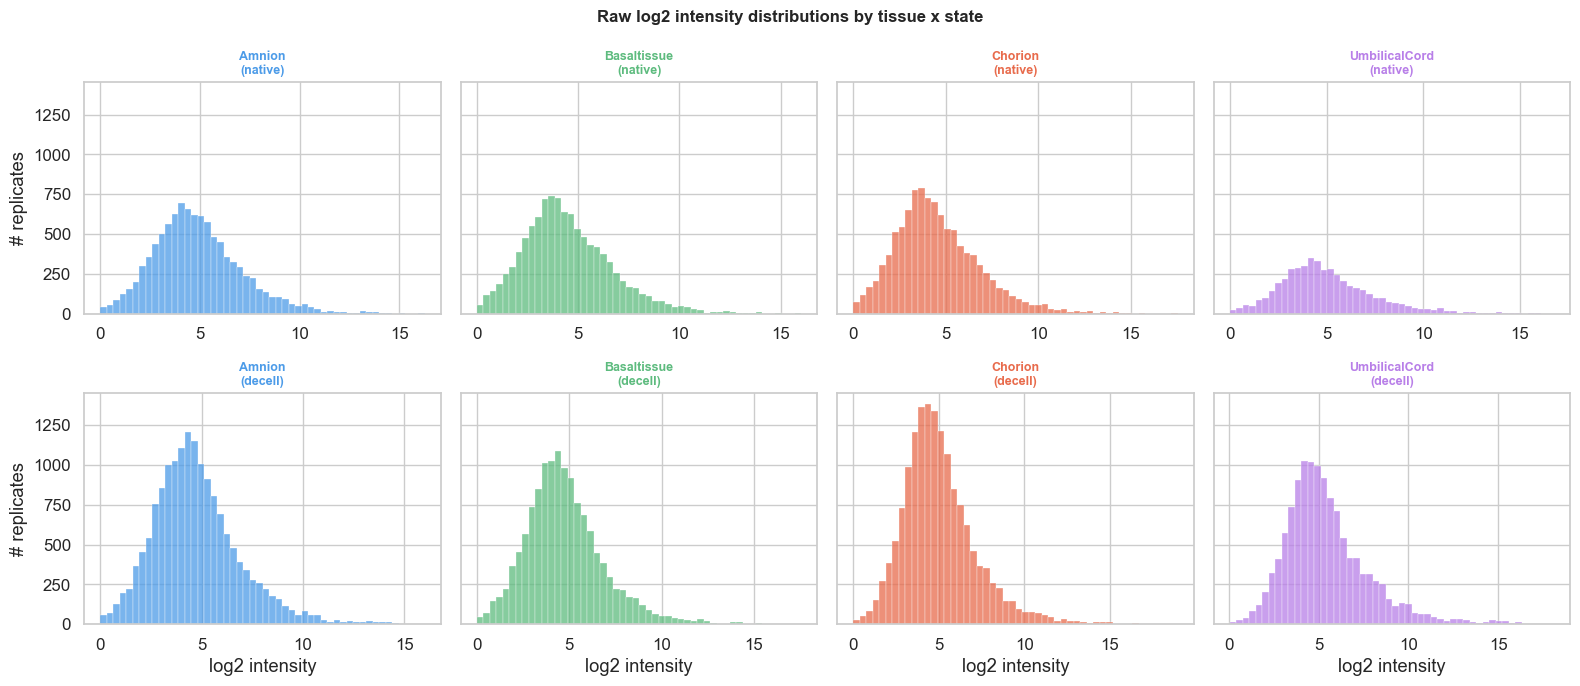

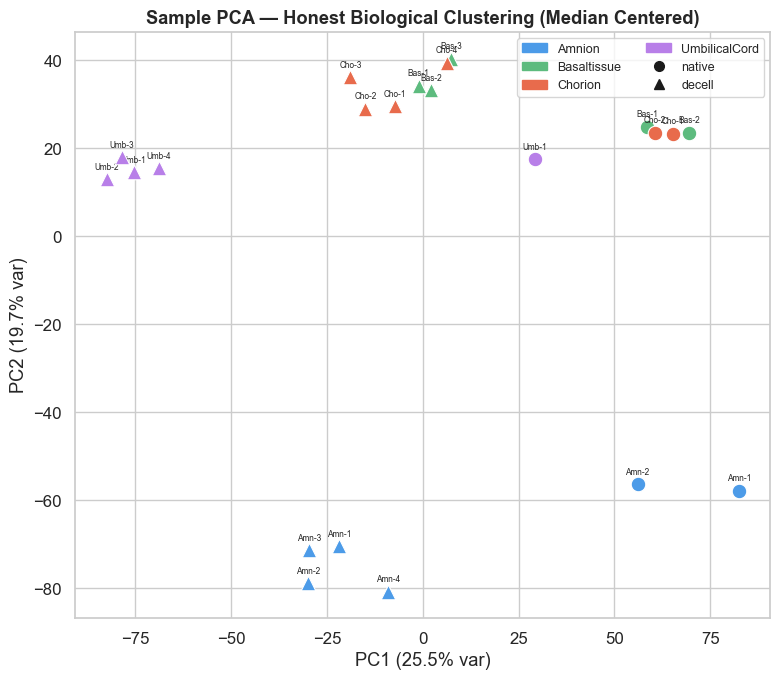

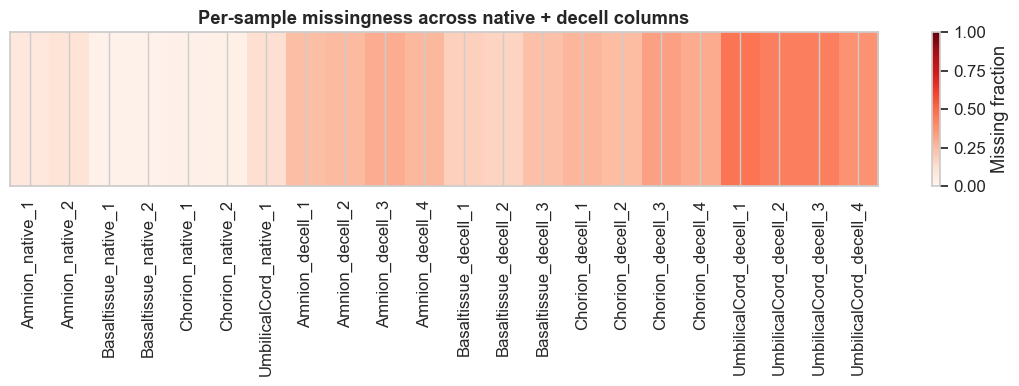

In [7]:
# ── 1. Expression distributions per tissue x state ───────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for j, state in enumerate(["native", "decell"]):
    cols_list = provider.nat_cols if state == "native" else provider.dec_cols
    for i, t in enumerate(TISS):
        ax    = axes[j, i]
        tcols = [c for c in cols_list if t in c]
        vals  = pk[tcols].values.flatten()
        
        vals  = vals[~np.isnan(vals) & (vals > 0)]
        ax.hist(vals, bins=50, color=PALETTE[t],
                alpha=0.75, edgecolor="white", lw=0.3)
        ax.set_title(f"{t}\n({state})", fontsize=9, color=PALETTE[t], fontweight="bold")
        ax.set_xlabel("log2 intensity" if j == 1 else "")
        ax.set_ylabel("# replicates" if i == 0 else "")

plt.suptitle("Raw log2 intensity distributions by tissue x state", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("fig_eda_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


# ── 2. PCA of samples (native vs decell) ────────────
all_cols = provider.nat_cols + provider.dec_cols

X_raw = pk[all_cols].values
X_imputed = provider._lod_impute(X_raw)
X_centered = X_imputed - np.median(X_imputed, axis=1, keepdims=True)
X_pca_in = X_centered.T

pca_eda   = PCA(n_components=2, random_state=CFG.seed)
Z_pca     = pca_eda.fit_transform(X_pca_in)   # (22, 2)

def _parse_col(c: str) -> Dict[str, str]:
    parts = c.rsplit("_", 2)
    return {"tissue": parts[0], "state": parts[1],
            "rep": parts[2]} if len(parts) == 3 else {}

fig, ax = plt.subplots(figsize=(8, 7))
for i, col in enumerate(all_cols):
    meta = _parse_col(col)
    if not meta: continue
    color  = PALETTE.get(meta["tissue"], "gray")
    marker = "o" if meta["state"] == "native" else "^"
    ax.scatter(Z_pca[i, 0], Z_pca[i, 1], c=color, marker=marker,
               s=110, edgecolors="white", lw=0.8, zorder=3)
    ax.annotate(f"{meta['tissue'][:3]}-{meta['rep']}",
                (Z_pca[i, 0], Z_pca[i, 1]), fontsize=6,
                xytext=(0, 7), textcoords="offset points", ha="center")

patches = [mpatches.Patch(color=PALETTE[t], label=t) for t in TISS]
lmarkers = [
    plt.Line2D([0], [0], marker="o", color="k", linestyle="", ms=7, label="native"),
    plt.Line2D([0], [0], marker="^", color="k", linestyle="", ms=7, label="decell"),
]
ax.legend(handles=patches + lmarkers, fontsize=9, ncol=2)
ax.set_xlabel(f"PC1 ({pca_eda.explained_variance_ratio_[0]:.1%} var)")
ax.set_ylabel(f"PC2 ({pca_eda.explained_variance_ratio_[1]:.1%} var)")
ax.set_title("Sample PCA — Honest Biological Clustering (Median Centered)", fontweight="bold")
plt.tight_layout()
plt.savefig("fig_eda_pca.png", dpi=150, bbox_inches="tight")
plt.show()


# ── 3. Missingness heatmap ────────────────────────────────────────────────────
miss_frac = pk[all_cols].isna().astype(float).mean(axis=0)
miss_arr  = miss_frac.values.reshape(1, -1)
fig, ax   = plt.subplots(figsize=(14, 2))
im = ax.imshow(miss_arr, aspect="auto", cmap="Reds", vmin=0, vmax=1)
ax.set_yticks([])
ax.set_xticks(range(len(all_cols)))
ax.set_xticklabels(all_cols, rotation=90, fontsize=12)
plt.colorbar(im, ax=ax, label="Missing fraction")
ax.set_title("Per-sample missingness across native + decell columns", fontweight="bold")
plt.tight_layout()
plt.savefig("fig_eda_missingness.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 2 — Preprocessing Ablation

Four preprocessing strategies tested on V1 (model fixed, only preprocessing varies):

| | Strategy | Question |
|---|---|---|
| A | LOD imputation + row-wise median centering | full pipeline |
| B | LOD imputation, no centering | does centering hurt? |
| C | Column-mean imputation + centering | is LOD special? |
| D | Complete cases only | what do we lose by imputing? |

In mass spectrometry, proteins are often "missing" because they fall below the Limit of Detection (LOD), not because they are absent. Replacing these with a random distribution (based on lod_sigma) is significantly more honest than replacing them with a global mean (Strategy C) or deleting the data entirely (Strategy D). Deleting data (Strategy D) is dangerous because of the loss in the "missingness" signal.

In [8]:
# ── V1 hyperparameters ────────────────────────────────────────────────────────
@dataclass
class V1Config:
    input_dim:   int   = 4
    output_dim:  int   = 4
    cond_dim:    int   = 2
    latent_dim:  int   = 2
    hidden_dim:  int   = 16
    lr:          float = 1e-3
    epochs:      int   = 120
    batch:       int   = 64
    max_beta:    float = 0.01
    kl_thresh:   float = 0.15
    decorr_w:    float = 5.0
    kl_warmup:   int   = 80

CFG_V1 = V1Config()


# ═══════════════════════════════════════════════════════════════════════════════
# ProteinCentricCVAE (V1)
# ═══════════════════════════════════════════════════════════════════════════════

class ProteinCentricCVAE(BaseCVAE):
    """
    Minimal CVAE baseline.

    Encoder : [X_nat ‖ C] → HIDDEN → (μ_z, log σ²_z)
    Decoder : [z     ‖ C] → HIDDEN → X̂_dec
    """

    def __init__(self, cfg: V1Config = CFG_V1) -> None:
        super().__init__()
        self.cfg = cfg
        D, H, Z, Cc = cfg.input_dim, cfg.hidden_dim, cfg.latent_dim, cfg.cond_dim

        self.encoder = nn.Sequential(
            nn.Linear(D + Cc, H), nn.ReLU(),
            nn.Linear(H, H),      nn.ReLU(),
        )
        self.fc_mu     = nn.Linear(H, Z)
        self.fc_logvar = nn.Linear(H, Z)

        self.decoder = nn.Sequential(
            nn.Linear(Z + Cc, H), nn.ReLU(),
            nn.Linear(H, H),      nn.ReLU(),
            nn.Linear(H, cfg.output_dim),
        )

    def encode(self, x: Tensor, c: Tensor) -> Tuple[Tensor, Tensor]:
        h = self.encoder(torch.cat([x, c], dim=-1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z: Tensor, c: Tensor) -> Tensor:
        return self.decoder(torch.cat([z, c], dim=-1))

    def forward(
        self, x: Tensor, c: Tensor, **_
    ) -> Tuple[Tensor, Tensor, Tensor, Tensor]:
        mu_z, logvar_z = self.encode(x, c)
        z              = self.reparameterise(mu_z, logvar_z)
        x_hat          = self.decode(z, c)
        return x_hat, mu_z, logvar_z, z

    def compute_loss(
        self,
        x_nat: Tensor,
        x_dec: Tensor,
        c:     Tensor,
        beta:  float,
        tissue_deltas_batch: Optional[List[Tensor]] = None,
        **_,
    ) -> Tuple[Tensor, Dict[str, float]]:
        x_hat, mu_z, logvar_z, z = self.forward(x_nat, c)

        recon          = F.mse_loss(x_hat, x_dec)
        kl_raw, kl_fb  = self.kl_free_bits(mu_z, logvar_z, self.cfg.kl_thresh)
        decorr         = self.decorr_loss(z)

        total = recon + beta * kl_fb + self.cfg.decorr_w * decorr
        return total, {
            "recon": recon.item(), "kl": kl_raw.item(), "decorr": decorr.item()
        }


# ── Parameter summary ─────────────────────────────────────────────────────────
torch.manual_seed(CFG.seed)
model_v1  = ProteinCentricCVAE(CFG_V1).to(device)
n_params1 = sum(p.numel() for p in model_v1.parameters() if p.requires_grad)
print(f"V1 ProteinCentricCVAE: {n_params1:,} trainable parameters")
print(f"  Input: {CFG_V1.input_dim}D  |  Latent: {CFG_V1.latent_dim}D  |  Hidden: {CFG_V1.hidden_dim}")

V1 ProteinCentricCVAE: 872 trainable parameters
  Input: 4D  |  Latent: 2D  |  Hidden: 16


In [9]:
N_FOLDS = 5
SEED    = 42
VERBOSE = 0

In [10]:
# ── Bundle builders ────────────────────────────────────────────────────────────
def _base_cols():
    pk         = provider.proteins_keep
    nat_cols_t = {t: [c for c in provider.nat_cols if t in c] for t in TISS}
    dec_cols_t = {t: [c for c in provider.dec_cols if t in c] for t in TISS}
    nat_raw    = pk[sum(nat_cols_t.values(), [])].values.copy().astype(np.float64)
    dec_raw    = pk[sum(dec_cols_t.values(), [])].values.copy().astype(np.float64)
    nat_raw[nat_raw == 0] = np.nan
    dec_raw[dec_raw == 0] = np.nan
    return pk, nat_raw, dec_raw, nat_cols_t, dec_cols_t


def _finish_bundle(pk, nat_mat, dec_mat, nat_cols_t, dec_cols_t, tr_idx, val_idx):
    df_nat    = pd.DataFrame(nat_mat, columns=sum(nat_cols_t.values(), []))
    df_dec    = pd.DataFrame(dec_mat, columns=sum(dec_cols_t.values(), []))
    X_nat_raw = provider._tissue_means(df_nat, nat_cols_t)
    X_dec_raw = provider._tissue_means(df_dec, dec_cols_t)
    sc_nat    = StandardScaler().fit(X_nat_raw[tr_idx])
    sc_dec    = StandardScaler().fit(X_dec_raw[tr_idx])
    X_nat     = sc_nat.transform(X_nat_raw).astype(np.float32)
    X_dec     = sc_dec.transform(X_dec_raw).astype(np.float32)
    delta_mat = X_dec_raw - X_nat_raw
    prot_df   = pk[METADATA_COLS + ["is_matrisome"]].copy().reset_index(drop=True)
    prot_df["mean_delta"]        = delta_mat.mean(axis=1)
    prot_df["n_tissues"]         = (X_nat_raw > 0).sum(axis=1)
    prot_df["is_collagen"]       = (pk["MatrisomeCategory"] == "Collagens").values
    prot_df["location"]          = pk.get("Location", pd.Series([""] * len(pk))).values
    prot_df["MatrisomeDivision"] = pk["MatrisomeDivision"].values
    prot_df["MatrisomeCategory"] = pk["MatrisomeCategory"].values
    for i, t in enumerate(TISS):
        prot_df[f"delta_{t}"]  = delta_mat[:, i]
        prot_df[f"{t}_native"] = X_nat_raw[:, i]
        prot_df[f"{t}_decell"] = X_dec_raw[:, i]
    C = provider._build_cond_v1(prot_df)
    return DataBundle(
        X_nat=X_nat, X_dec=X_dec, C=C, prot_df=prot_df,
        scaler_nat=sc_nat, scaler_dec=sc_dec,
        tr_idx=tr_idx, val_idx=val_idx,
        tissue_deltas=[delta_mat[:, i] for i in range(4)],
    )


def bundle_A(tr, val):
    pk, _, _, nc, dc = _base_cols()
    ni = provider._lod_impute(pk[sum(nc.values(), [])].values)
    di = provider._lod_impute(pk[sum(dc.values(), [])].values)
    med = np.median(np.concatenate([ni, di], axis=1), axis=1, keepdims=True)
    return _finish_bundle(pk, ni - med, di - med, nc, dc, tr, val)

def bundle_B(tr, val):
    pk, _, _, nc, dc = _base_cols()
    ni = provider._lod_impute(pk[sum(nc.values(), [])].values)
    di = provider._lod_impute(pk[sum(dc.values(), [])].values)
    return _finish_bundle(pk, ni, di, nc, dc, tr, val)

def bundle_C(tr, val):
    pk, nat_raw, dec_raw, nc, dc = _base_cols()
    def _mean_imp(mat):
        out = mat.copy()
        for j in range(out.shape[1]):
            col = out[:, j]; obs = col[~np.isnan(col)]
            col[np.isnan(col)] = obs.mean() if len(obs) else 0.0
        return out.astype(np.float32)
    ni, di = _mean_imp(nat_raw), _mean_imp(dec_raw)
    med = np.median(np.concatenate([ni, di], axis=1), axis=1, keepdims=True)
    return _finish_bundle(pk, ni - med, di - med, nc, dc, tr, val)

def bundle_D(tr, val):
    pk, nat_raw, dec_raw, nc, dc = _base_cols()
    complete = ~np.any(np.isnan(np.concatenate([nat_raw, dec_raw], axis=1)), axis=1)
    sub      = np.where(complete)[0]
    pk_sub   = pk.iloc[sub].reset_index(drop=True)
    g2l      = {g: l for l, g in enumerate(sub)}
    tr_l     = np.array([g2l[i] for i in tr  if i in g2l], dtype=np.int64)
    val_l    = np.array([g2l[i] for i in val if i in g2l], dtype=np.int64)
    ns       = nat_raw[sub].astype(np.float32)
    ds       = dec_raw[sub].astype(np.float32)
    med      = np.nanmedian(np.concatenate([ns, ds], axis=1), axis=1, keepdims=True)
    orig = provider.proteins_keep
    provider.proteins_keep = pk_sub
    b = _finish_bundle(pk_sub, ns - med, ds - med, nc, dc, tr_l, val_l)
    provider.proteins_keep = orig
    return b, len(sub)


# ── Observed-only mask (computed once) ────────────────────────────────────────
def _obs_mask():
    pk, nat_raw, dec_raw, nc, dc = _base_cols()
    dfn = pd.DataFrame(nat_raw, columns=sum(nc.values(), []))
    dfd = pd.DataFrame(dec_raw, columns=sum(dc.values(), []))
    no  = np.column_stack([dfn[nc[t]].notna().any(axis=1).values for t in TISS])
    do  = np.column_stack([dfd[dc[t]].notna().any(axis=1).values for t in TISS])
    return no & do

OBS_MASK  = _obs_mask()
pk_global = provider.proteins_keep


# ── Single unified evaluator────────────────────
def _eval_all(model, bundle, obs_mask=None, is_D=False):
    """
    Computes in one pass:
      r_model, r_copy, lift          — raw Pearson r (act 1)
      r2_delta                       — Δ-R² on all cells (act 2)
      r2_delta_obs, lift_obs         — Δ-R² on observed-only cells (act 3)
                                       skipped for D (index mismatch)
    """
    model.eval()
    val = bundle.val_idx
    with torch.no_grad():
        mu_out = model(bundle.to_float(bundle.X_nat[val]),
                       bundle.to_float(bundle.C[val]))[0].cpu().numpy()

    Xp  = bundle.scaler_dec.inverse_transform(mu_out)
    Xt  = bundle.scaler_dec.inverse_transform(bundle.X_dec[val])
    Xn  = bundle.scaler_nat.inverse_transform(bundle.X_nat[val, :4])

    is_mat    = bundle.prot_df.iloc[val]["is_matrisome"].values
    r_model,_ = pearsonr(Xt.flatten(), Xp.flatten())
    r_copy, _ = pearsonr(Xt.flatten(), Xn.flatten())
    r_ecm,  _ = pearsonr(Xt[is_mat].flatten(),  Xp[is_mat].flatten())
    r_cel,  _ = pearsonr(Xt[~is_mat].flatten(), Xp[~is_mat].flatten())

    d_true = Xt - Xn
    d_pred = Xp - Xn
    ss     = ((d_true - d_pred)**2).sum()
    st     = ((d_true - d_true.mean())**2).sum()
    r2d    = float(1 - ss / st)

    # observed-only (not available for D — its val_idx maps into a subset)
    r2d_obs = float("nan")
    lift_obs = float("nan")
    if obs_mask is not None and not is_D:
        m      = obs_mask[val]
        dt, dp = d_true[m], d_pred[m]
        ss_o   = ((dt - dp)**2).sum()
        st_o   = ((dt - dt.mean())**2).sum()
        r2d_obs = float(1 - ss_o / st_o)
        Xt_o, Xp_o, Xn_o = Xt[m], Xp[m], Xn[m]
        rm_o, _ = pearsonr(Xt_o, Xp_o)
        rc_o, _ = pearsonr(Xt_o, Xn_o)
        lift_obs = float(rm_o - rc_o)

    return {
        "r_model":    float(r_model),
        "r_copy":     float(r_copy),
        "lift":       float(r_model - r_copy),
        "r_ecm":      float(r_ecm),
        "r_cel":      float(r_cel),
        "r2_delta":   r2d,
        "r2d_obs":    r2d_obs,
        "lift_obs":   lift_obs,
    }


# ── Single CV loop ────────────────────────────
strat      = pk_global["is_matrisome"].values.astype(int)
skf        = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
results    = {k: [] for k in ["A_full_pipeline","B_no_centering",
                               "C_mean_impute","D_complete_only"]}
n_complete = None

print(f"Preprocessing ablation — {N_FOLDS}-fold CV")
print("─" * 68)

for fold, (tr_idx, val_idx) in enumerate(
        skf.split(np.arange(len(pk_global)), strat), 1):

    print(f"\nFold {fold}/{N_FOLDS}  train={len(tr_idx):,}  val={len(val_idx):,}")

    for name, builder, is_D in [
        ("A_full_pipeline", bundle_A, False),
        ("B_no_centering",  bundle_B, False),
        ("C_mean_impute",   bundle_C, False),
        ("D_complete_only", bundle_D, True),
    ]:
        b = builder(tr_idx, val_idx)
        n_p = len(pk_global)
        if is_D:
            b, n_p = b
            if fold == 1: n_complete = n_p

        model = ProteinCentricCVAE(CFG_V1).to(device)
        Trainer(model=model, lr=CFG_V1.lr, epochs=CFG_V1.epochs,
                batch=CFG_V1.batch, max_beta=CFG_V1.max_beta,
                kl_warmup=CFG_V1.kl_warmup).fit(b, verbose=VERBOSE)

        m = _eval_all(model, b, obs_mask=OBS_MASK, is_D=is_D)
        results[name].append(m)

        obs_str = f"  r2d_obs={m['r2d_obs']:.3f}" if not is_D else "  r2d_obs=—"
        print(f"  {name:<22}  r={m['r_model']:.3f}  copy={m['r_copy']:.3f}  "
              f"lift={m['lift']:+.3f}  r2d={m['r2_delta']:.3f}{obs_str}  n={n_p:,}")

Preprocessing ablation — 5-fold CV
────────────────────────────────────────────────────────────────────

Fold 1/5  train=4,358  val=1,090
  Done. Best val loss: 0.79760
  A_full_pipeline         r=0.565  copy=0.298  lift=+0.267  r2d=0.657  r2d_obs=0.566  n=5,448
  Done. Best val loss: 0.36470
  B_no_centering          r=0.783  copy=0.799  lift=-0.016  r2d=0.041  r2d_obs=-0.085  n=5,448
  Done. Best val loss: 0.79677
  C_mean_impute           r=0.579  copy=0.196  lift=+0.382  r2d=0.738  r2d_obs=0.650  n=5,448
  Done. Best val loss: 0.59424
  D_complete_only         r=0.686  copy=0.329  lift=+0.357  r2d=0.691  r2d_obs=—  n=2,038

Fold 2/5  train=4,358  val=1,090
  Done. Best val loss: 0.78246
  A_full_pipeline         r=0.598  copy=0.293  lift=+0.306  r2d=0.653  r2d_obs=0.601  n=5,448
  Done. Best val loss: 0.37436
  B_no_centering          r=0.826  copy=0.826  lift=+0.000  r2d=0.056  r2d_obs=-0.065  n=5,448
  Done. Best val loss: 0.81341
  C_mean_impute           r=0.604  copy=0.168  li

In [11]:
# ── HTML summary cards ───────────────────────────────────────────────────
def _card(inner, title="", accent="#534AB7"):
    hdr = (f'<div style="font-size:11px;font-weight:500;letter-spacing:.06em;'
           f'text-transform:uppercase;color:{accent};margin-bottom:12px">{title}</div>'
           if title else "")
    return (f'<div style="background:#fff;border:0.5px solid #ddd;border-radius:10px;'
            f'padding:14px 18px;margin:8px 0;font-family:system-ui,sans-serif;'
            f'font-size:13px;color:#1a1a1a">{hdr}{inner}</div>')

def _bar(v, max_v, color, track=80):
    w = max(2, int(abs(v) / max_v * track)) if max_v > 0 else 2
    return (f'<span style="display:inline-block;width:{track}px;height:8px;'
            f'background:#f0f0f0;border-radius:4px;vertical-align:middle;flex-shrink:0">'
            f'<span style="display:block;width:{w}px;height:8px;background:{color};'
            f'border-radius:4px"></span></span>')

def _th(t, w=None):
    return (f'<th style="padding:6px 0;text-align:left;font-weight:500;color:#888;'
            f'font-size:11px;text-transform:uppercase;{"width:"+w+";" if w else ""}">{t}</th>')

def _td(v, w=None, bold=False):
    return (f'<td style="padding:7px 0;vertical-align:middle;'
            f'{"width:"+w+";" if w else ""}{"font-weight:500;" if bold else ""}">{v}</td>')

COND = {
    "A_full_pipeline": ("#4C9BE8", "A", "LOD + centering",    "full pipeline"),
    "B_no_centering":  ("#E86B4C", "B", "LOD, no centering",  "exposes metric artefact"),
    "C_mean_impute":   ("#5DBB7E", "C", "Mean impute + cen.", "naive imputation"),
    "D_complete_only": ("#B87FE8", "D", "Complete cases",     "selection bias"),
}

def ms(name, key):
    vals = [r[key] for r in results[name] if not np.isnan(r[key])]
    if not vals: return "—"
    v = np.array(vals)
    return f"{v.mean():.3f}<span style='color:#aaa;font-size:11px'> ±{v.std():.3f}</span>"

def lift_cell(name, key="lift"):
    v = np.array([r[key] for r in results[name]])
    m = v.mean()
    col = "#4C9BE8" if m > 0.01 else "#E24B4A"
    bar = _bar(abs(m), 0.5, col, 60)
    sign = "+" if m >= 0 else ""
    return (f'<div style="display:flex;align-items:center;gap:6px">'
            f'{bar}<span>{sign}{m:.3f}</span></div>')

# ── Card 1: full comparison table ─────────────────────────────────────────────
cols = [
    ("",         "32px",  "left",  False),
    ("Strategy", "160px", "left",  False),
    ("r model",  "80px",  "right", False),
    ("r copy-native", "90px", "right", False),
    ("Lift",     "110px", "left",  False),
    ("Δ-R² all", "80px",  "right", False),
    ("Δ-R² obs only", "100px", "right", False),
    ("n proteins", "80px", "right", False),
]

colgroup = "".join(f'<col style="width:{w}">' for _, w, *_ in cols)
hdr_row  = "".join(
    f'<th style="padding:6px 8px;text-align:{a};font-weight:500;'
    f'color:var(--color-text-secondary);font-size:11px;text-transform:uppercase">{h}</th>'
    for h, _, a, *_ in cols)

def _lift_bar(name):
    v    = np.mean([r["lift"] for r in results[name]])
    w    = max(2, int(abs(v) / 0.5 * 52))
    col  = "#4C9BE8" if v > 0.01 else "#E24B4A"
    sign = "+" if v >= 0 else ""
    return (f'<div style="display:flex;align-items:center;gap:6px">'
            f'<div style="width:52px;height:7px;background:var(--color-background-tertiary);'
            f'border-radius:4px;flex-shrink:0">'
            f'<div style="width:{w}px;height:7px;background:{col};border-radius:4px"></div></div>'
            f'<span style="color:var(--color-text-primary)">{sign}{v:.3f}</span></div>')

def _val(name, key):
    vals = [r[key] for r in results[name] if not np.isnan(r.get(key, float("nan")))]
    if not vals: return "—"
    v = np.array(vals)
    return f"{v.mean():.3f} <span style='color:var(--color-text-secondary);font-size:11px'>±{v.std():.3f}</span>"

COND = {
    "A_full_pipeline": ("#4C9BE8","#E6F1FB","A","LOD + centering",    "full pipeline"),
    "B_no_centering":  ("#E86B4C","#FAECE7","B","LOD, no centering",  "exposes metric artefact"),
    "C_mean_impute":   ("#5DBB7E","#E1F5EE","C","Mean impute + cen.", "naive imputation"),
    "D_complete_only": ("#B87FE8","#EEEDFE","D","Complete cases",     "selection bias"),
}

body = ""
for i, (name, (fg, bg, letter, strategy, note)) in enumerate(COND.items()):
    sep  = "border-top:0.5px solid var(--color-border-tertiary);" if i else ""
    n_p  = n_complete if name == "D_complete_only" else len(pk_global)
    dot  = (f'<span style="background:{bg};color:{fg};font-weight:500;font-size:11px;'
            f'padding:2px 8px;border-radius:4px;display:inline-block">{letter}</span>')
    body += (f'<tr style="{sep}">'
             f'<td style="padding:9px 8px 9px 0;vertical-align:middle">{dot}</td>'
             f'<td style="padding:9px 8px;vertical-align:middle">'
             f'<div style="font-weight:500;color:var(--color-text-primary)">{strategy}</div>'
             f'<div style="font-size:11px;color:var(--color-text-secondary);margin-top:1px">{note}</div>'
             f'</td>'
             f'<td style="padding:9px 8px;text-align:right;vertical-align:middle;color:var(--color-text-primary)">{_val(name,"r_model")}</td>'
             f'<td style="padding:9px 8px;text-align:right;vertical-align:middle;color:var(--color-text-secondary)">{_val(name,"r_copy")}</td>'
             f'<td style="padding:9px 8px;vertical-align:middle">{_lift_bar(name)}</td>'
             f'<td style="padding:9px 8px;text-align:right;vertical-align:middle;color:var(--color-text-primary)">{_val(name,"r2_delta")}</td>'
             f'<td style="padding:9px 8px;text-align:right;vertical-align:middle;color:var(--color-text-primary)">{_val(name,"r2d_obs")}</td>'
             f'<td style="padding:9px 8px;text-align:right;vertical-align:middle;color:var(--color-text-secondary)">{n_p:,}</td>'
             f'</tr>')

display(HTML(_card(
    f'<div style="overflow-x:auto">'
    f'<table style="width:100%;border-collapse:collapse;font-size:13px;'
    f'table-layout:fixed;min-width:560px">'
    f'<colgroup>{colgroup}</colgroup>'
    f'<thead><tr style="border-bottom:0.5px solid var(--color-border-secondary)">{hdr_row}</tr></thead>'
    f'<tbody>{body}</tbody>'
    f'</table></div>',
    title=f"Preprocessing ablation — V1, {N_FOLDS}-fold CV",
    accent="#534AB7")))

# ── Card 2: key findings ───────────────────────────────────────────────────────
a_lift = np.mean([r["lift"]      for r in results["A_full_pipeline"]])
b_lift = np.mean([r["lift"]      for r in results["B_no_centering"]])
b_rmod = np.mean([r["r_model"]   for r in results["B_no_centering"]])
b_rcop = np.mean([r["r_copy"]    for r in results["B_no_centering"]])
a_r2   = np.mean([r["r2_delta"]  for r in results["A_full_pipeline"]])
b_r2   = np.mean([r["r2_delta"]  for r in results["B_no_centering"]])
a_obs  = np.mean([r["r2d_obs"]   for r in results["A_full_pipeline"]])
c_obs  = np.mean([r["r2d_obs"]   for r in results["C_mean_impute"]])
c_all  = np.mean([r["r2_delta"]  for r in results["C_mean_impute"]])
d_r2   = np.mean([r["r2_delta"]  for r in results["D_complete_only"]])
gap_all = c_all - a_r2
gap_obs = c_obs - a_obs
art_frac = (gap_all - gap_obs) / gap_all if gap_all > 0 else 0

findings = [
    ("#FCEBEB", "#791F1F", "Strategy B",
     f"r model = {b_rmod:.3f} but r copy-native = {b_rcop:.3f}. "
     f"Lift = {b_lift:+.3f} ≈ 0. The model adds no signal without centering, "
     f"high r is driven by protein abundance level and not decellularization prediction."),
    ("#E1F5EE", "#085041", "Strategy A",
     f"Lift = {a_lift:+.3f}, Δ-R² = {a_r2:.3f}. LOD + centering is the correct choice. "),
    ("#FAEEDA", "#633806", "Strategy C vs A",
     f"C leads A by +{gap_all:.3f} on all-cell Δ-R² and by +{gap_obs:.3f} on observed-only. "
     f"{art_frac:.0%} of C&#39;s advantage disappears when imputed cells are excluded from scoring. "
     f"Mean imputation places lost proteins at the column mean, erasing the loss signal."),
    ("#F0EEFE", "#3C3489", "Strategy D",
     f"Δ-R² = {d_r2:.3f} on {n_complete:,} proteins ({n_complete/len(pk_global):.0%} of total). "
     f"Higher scores because only high-abundance, stably-detected proteins are included. "
     f"The dropped {len(pk_global)-n_complete:,} proteins are where the interesting biology is."),
]
grid = '<div style="display:grid;grid-template-columns:1fr 1fr;gap:10px">'
for bg, fg, title, body_txt in findings:
    grid += (f'<div style="background:{bg};border-radius:8px;padding:11px 13px">'
             f'<div style="font-size:11px;font-weight:500;color:{fg};'
             f'text-transform:uppercase;margin-bottom:5px">{title}</div>'
             f'<div style="font-size:12px;color:#333;line-height:1.5">{body_txt}</div>'
             f'</div>')
grid += '</div>'
display(HTML(_card(grid, title="Key findings", accent="#085041")))

# ── Card 3: decision ──────────────────────────────────────────────────────────
display(HTML(_card(
    f'<div style="background:#E1F5EE;border-radius:8px;padding:12px 14px;'
    f'font-size:13px;color:#085041;font-weight:500">'
    f'Decision: <strong>Condition A — LOD imputation + row-wise median centering</strong>.'
    f'</div>',
    title="Decision", accent="#085041")))


,Strategy,r model,r copy-native,Lift,Δ-R² all,Δ-R² obs only,n proteins
A,LOD + centeringfull pipeline,0.582 ±0.012,0.271 ±0.020,+0.311,0.671 ±0.013,0.605 ±0.022,"5,448"
B,"LOD, no centeringexposes metric artefact",0.807 ±0.019,0.813 ±0.013,-0.006,0.052 ±0.020,-0.067 ±0.029,"5,448"
C,Mean impute + cen.naive imputation,0.579 ±0.015,0.164 ±0.023,+0.415,0.750 ±0.008,0.665 ±0.014,"5,448"
D,Complete casesselection bias,0.692 ±0.039,0.315 ±0.017,+0.376,0.711 ±0.030,—,"2,038"


---
## ESM-2 Embedding Utilities

Fetches UniProt sequences and computes mean-pooled **ESM-2** embeddings
(`facebook/esm2_t6_8M_UR50D`, 320D), cached to disk after first run.

These embeddings feed V8/V10/V11 below.

In [86]:
# ESM-2 embedding utilities (run once; cached to disk)
# Fetches UniProt sequences + computes mean-pooled ESM-2 embeddings.
# Cached so subsequent runs are instant. Requires network + (ideally) GPU only
# on the FIRST run. After that, only data/esm2_embeddings.npy is needed.

ESM_MODEL_NAME = "facebook/esm2_t6_8M_UR50D"   # 320-dim, 8M params — light & fast
ESM_DIM        = 320
MAX_SEQ_LEN    = 1022
SEQ_CACHE_PATH = "data/uniprot_sequences.json"
EMB_CACHE_PATH = "data/esm2_embeddings.npy"
EMB_ID_PATH    = "data/esm2_embedding_ids.json"


def fetch_sequences_uniprot(uniprot_ids: List[str],
                            cache_path: str = SEQ_CACHE_PATH,
                            batch_size: int = 100,
                            pause: float = 0.2) -> Dict[str, str]:
    """Fetch FASTA sequences from UniProt REST, cached incrementally to disk."""
    os.makedirs(os.path.dirname(cache_path), exist_ok=True)
    if os.path.exists(cache_path):
        with open(cache_path) as f:
            cache = json.load(f)
        missing = [u for u in uniprot_ids if u not in cache]
        if not missing:
            print(f"  All {len(uniprot_ids):,} sequences from cache")
            return cache
        print(f"  {len(cache):,} cached, fetching {len(missing):,} missing...")
    else:
        cache, missing = {}, list(uniprot_ids)
        print(f"  Fetching {len(missing):,} sequences from UniProt...")

    import requests
    fetched = failed = 0
    for i, uid in enumerate(missing):
        try:
            r = requests.get(f"https://rest.uniprot.org/uniprotkb/{uid}.fasta", timeout=15)
            if r.status_code == 200:
                seq = "".join(r.text.strip().split("\n")[1:])
                if seq:
                    cache[uid] = seq; fetched += 1
            else:
                failed += 1
        except Exception:
            failed += 1
        if (i + 1) % batch_size == 0:
            with open(cache_path, "w") as f: json.dump(cache, f)
            print(f"    {i+1}/{len(missing)} — fetched {fetched}, failed {failed}")
            time.sleep(pause)
    with open(cache_path, "w") as f: json.dump(cache, f)
    print(f"  Done: {fetched} fetched, {failed} failed, {len(cache):,} total")
    return cache


def generate_esm2_embeddings(uniprot_ids: List[str],
                             sequences: Dict[str, str],
                             emb_cache: str = EMB_CACHE_PATH,
                             id_cache:  str = EMB_ID_PATH,
                             batch_size: int = 32,
                             model_name: str = ESM_MODEL_NAME,
                             dev: torch.device = device) -> Tuple[np.ndarray, List[str]]:
    """Mean-pooled ESM-2 embeddings, cached to .npy. Returns (emb, ordered_ids)."""
    if os.path.exists(emb_cache) and os.path.exists(id_cache):
        with open(id_cache) as f: cached_ids = json.load(f)
        if set(uniprot_ids).issubset(set(cached_ids)):
            emb = np.load(emb_cache)
            idx_map   = {u: i for i, u in enumerate(cached_ids)}
            valid_ids = [u for u in uniprot_ids if u in idx_map]
            order     = [idx_map[u] for u in valid_ids]
            print(f"  Embeddings from cache ({len(valid_ids):,} proteins, {emb.shape[1]}D)")
            return emb[order], valid_ids

    from transformers import EsmModel, EsmTokenizer
    print(f"  Loading ESM-2: {model_name} ...")
    tok = EsmTokenizer.from_pretrained(model_name)
    esm = EsmModel.from_pretrained(model_name).to(dev).eval()

    todo = [(u, sequences.get(u, "")[:MAX_SEQ_LEN])
            for u in uniprot_ids if len(sequences.get(u, "")) >= 10]
    print(f"  Inference on {len(todo):,} proteins...")

    all_emb, valid_ids = [], []
    for i in range(0, len(todo), batch_size):
        batch     = todo[i:i + batch_size]
        ids, seqs = [b[0] for b in batch], [b[1] for b in batch]
        try:
            inp = tok(seqs, return_tensors="pt", padding=True,
                      truncation=True, max_length=MAX_SEQ_LEN + 2).to(dev)
            with torch.no_grad():
                out = esm(**inp)
            hid  = out.last_hidden_state[:, 1:-1, :]                 # strip CLS/EOS
            mask = inp["attention_mask"][:, 1:-1].unsqueeze(-1).float()
            pooled = (hid * mask).sum(1) / mask.sum(1).clamp(min=1)  # (B, 320)
            all_emb.append(pooled.cpu().float().numpy())
            valid_ids.extend(ids)
        except Exception as e:
            print(f"    batch {i//batch_size+1} failed: {e}")
        if (i // batch_size + 1) % 20 == 0:
            print(f"    {min(i+batch_size, len(todo)):,}/{len(todo):,} done")

    emb = np.vstack(all_emb)
    os.makedirs(os.path.dirname(emb_cache), exist_ok=True)
    np.save(emb_cache, emb)
    with open(id_cache, "w") as f: json.dump(valid_ids, f)
    print(f"  Saved embeddings: {emb.shape}")
    del esm; torch.cuda.empty_cache()
    return emb, valid_ids


def attach_esm_to_bundle(bundle, scaler_attr: str = "scaler_esm") -> np.ndarray:
    """
    Compute (or load) ESM embeddings aligned to bundle.prot_df row order,
    scale them with their OWN StandardScaler (fixes the 26x variance imbalance
    vs the unit-variance expression features), store the scaler on the bundle,
    and return the (N, 320) scaled embedding matrix.
    """
    from sklearn.preprocessing import StandardScaler
    uids = bundle.prot_df["UniProt"].tolist()

    seqs = fetch_sequences_uniprot(uids)
    cov  = sum(u in seqs for u in uids)
    print(f"  Sequence coverage: {cov:,}/{len(uids):,} ({cov/len(uids):.1%})")

    emb, emb_ids = generate_esm2_embeddings(uids, seqs)
    emap = {u: i for i, u in enumerate(emb_ids)}

    N = len(uids)
    esm_raw = np.zeros((N, ESM_DIM), dtype=np.float32)
    has_emb = np.zeros(N, dtype=bool)
    for i, u in enumerate(uids):
        if u in emap:
            esm_raw[i] = emb[emap[u]]; has_emb[i] = True
    print(f"  ESM coverage: {has_emb.sum():,}/{N:,} ({has_emb.mean():.1%})")

    scaler = StandardScaler()
    esm_sc = scaler.fit_transform(esm_raw).astype(np.float32)
    esm_sc[~has_emb] = 0.0          # re-zero proteins with no embedding
    print(f"  ESM std raw {esm_raw[has_emb].std(0).mean():.4f} "
          f"-> scaled {esm_sc[has_emb].std(0).mean():.4f} (target ~1.0)")

    bundle.extra[scaler_attr] = scaler
    bundle.prot_df["has_esm"] = has_emb
    return esm_sc

---
## CV Helpers & Shared Setup

Defines every bundle builder, evaluator, `assign_cat_idx`, and the shared `CV_FOLDS` list. Every model section below uses these. ESM embeddings are pre-computed here and cached to disk.


In [87]:
# CV HELPERS & SHARED SETUP
# Defines all bundle builders, evaluators, and the shared fold object.

N_FOLDS  = 5
SEED     = 42
VERBOSE  = 0

# ── Stratified folds — built ONCE, shared by every model section ──────────────
pk    = provider.proteins_keep
strat = pk["is_matrisome"].values.astype(int)
SKF      = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
CV_FOLDS = list(SKF.split(np.arange(len(pk)), strat))

# ── ESM embeddings — computed once, reused by V8/V9/V10/V11/V8e-style bundles ─
print("Pre-computing ESM embeddings (cached to disk after first run)...")
esm_full = attach_esm_to_bundle(provider.prepare_v5())
print(f"  ESM ready: {esm_full.shape}\n")

# ── assign_cat_idx (used by V7, V8, V9, V10, V11 and their expr variants) ─────
CAT_MAP = {
    "none": 0, "Collagens": 1, "ECM Glycoproteins": 2, "Proteoglycans": 3,
    "ECM Regulators": 4, "ECM-affiliated Proteins": 5, "Secreted Factors": 6,
}
N_CATEGORIES = len(CAT_MAP)
ECM_CAT_MAP  = CAT_MAP  # alias used by _cv_bundle_v9

def assign_cat_idx(prot_df):
    def _cat(row):
        if not row["is_matrisome"]: return 0
        return CAT_MAP.get(str(row.get("MatrisomeCategory", "none")), 0)
    return prot_df.apply(_cat, axis=1).values.astype(np.int64)

# ── Bundle builders ────────────────────────────────────────────────────────────
def _cv_bundle_v1(provider, tr, val):
    pk    = provider.proteins_keep
    nat_t = {t: [c for c in provider.nat_cols if t in c] for t in TISS}
    dec_t = {t: [c for c in provider.dec_cols if t in c] for t in TISS}
    ni = provider._lod_impute(pk[sum(nat_t.values(), [])].values)
    di = provider._lod_impute(pk[sum(dec_t.values(), [])].values)
    med = np.median(np.concatenate([ni, di], 1), 1, keepdims=True)
    ni -= med; di -= med
    dfn = pd.DataFrame(ni, columns=sum(nat_t.values(), []))
    dfd = pd.DataFrame(di, columns=sum(dec_t.values(), []))
    Xn  = provider._tissue_means(dfn, nat_t)
    Xd  = provider._tissue_means(dfd, dec_t)
    scn = StandardScaler().fit(Xn[tr]); scd = StandardScaler().fit(Xd[tr])
    dm  = Xd - Xn
    pdf = pk[METADATA_COLS + ["is_matrisome"]].copy().reset_index(drop=True)
    pdf["mean_delta"] = dm.mean(1); pdf["n_tissues"] = (Xn > 0).sum(1)
    pdf["is_collagen"] = (pk["MatrisomeCategory"] == "Collagens").values
    pdf["location"] = pk.get("Location", pd.Series([""] * len(pk))).values
    pdf["MatrisomeDivision"] = pk["MatrisomeDivision"].values
    pdf["MatrisomeCategory"] = pk["MatrisomeCategory"].values
    for i, t in enumerate(TISS):
        pdf[f"delta_{t}"] = dm[:, i]; pdf[f"{t}_native"] = Xn[:, i]; pdf[f"{t}_decell"] = Xd[:, i]
    C = provider._build_cond_v1(pdf)
    return DataBundle(X_nat=scn.transform(Xn).astype(np.float32),
                      X_dec=scd.transform(Xd).astype(np.float32),
                      C=C, prot_df=pdf, scaler_nat=scn, scaler_dec=scd,
                      tr_idx=tr, val_idx=val, tissue_deltas=[dm[:, i] for i in range(4)])

def _cv_bundle_v5(provider, tr, val):
    pk    = provider.proteins_keep
    nat_t = {t: [c for c in provider.nat_cols if t in c] for t in TISS}
    dec_t = {t: [c for c in provider.dec_cols if t in c] for t in TISS}
    dfnr  = pk[sum(nat_t.values(), [])]; dfdr = pk[sum(dec_t.values(), [])]
    ni = provider._lod_impute(dfnr.values); di = provider._lod_impute(dfdr.values)
    med = np.median(np.concatenate([ni, di], 1), 1, keepdims=True)
    ni -= med; di -= med
    dfn = pd.DataFrame(ni, columns=dfnr.columns); dfd = pd.DataFrame(di, columns=dfdr.columns)
    Xm = provider._tissue_means(dfn, nat_t); Xs = provider._tissue_stds(dfn, nat_t)
    Xdt = provider._detection_rates(dfnr, nat_t); Xd = provider._tissue_means(dfd, dec_t)
    scm = StandardScaler().fit(Xm[tr]); scd = StandardScaler().fit(Xd[tr])
    scs = StandardScaler().fit(Xs[tr])
    Xnat = np.concatenate([scm.transform(Xm), scs.transform(Xs),
                            (Xdt - Xdt[tr].mean(0)).astype(np.float32)], 1).astype(np.float32)
    dm = Xd - Xm
    pdf = pk[METADATA_COLS + ["is_matrisome"]].copy().reset_index(drop=True)
    pdf["mean_delta"] = dm.mean(1); pdf["n_tissues"] = (Xdt > 0).sum(1)
    pdf["is_collagen"] = (pk["MatrisomeCategory"] == "Collagens").values
    pdf["location"] = pk.get("Location", pd.Series([""] * len(pk))).values
    pdf["MatrisomeDivision"] = pk["MatrisomeDivision"].values
    pdf["MatrisomeCategory"] = pk["MatrisomeCategory"].values
    for i, t in enumerate(TISS):
        pdf[f"delta_{t}"] = dm[:, i]; pdf[f"{t}_native"] = Xm[:, i]; pdf[f"{t}_decell"] = Xd[:, i]
    cache = pd.read_csv(CFG.cache_path)[["UniProt", "mol_weight", "seq_length"]].fillna(0)
    C = provider._build_cond_v5(pdf, cache)
    scd2 = StandardScaler().fit(dm[tr])
    td = [scd2.transform(dm)[:, i].astype(np.float32) for i in range(4)]
    return DataBundle(X_nat=Xnat, X_dec=scd.transform(Xd).astype(np.float32),
                      C=C, prot_df=pdf, scaler_nat=scm, scaler_dec=scd,
                      tr_idx=tr, val_idx=val, tissue_deltas=td,
                      extra={"scaler_std": scs, "scaler_det_mean": Xdt.mean(0)})

def _cv_bundle_v8(b5, esm):
    b = copy.copy(b5)
    b.X_nat = np.concatenate([esm, b5.X_nat], 1).astype(np.float32)
    b.extra  = dict(b5.extra)
    b.extra["cat_idx_batch"] = assign_cat_idx(b5.prot_df)
    return b

def _cv_bundle_v9(b8):
    is_mat = b8.prot_df["is_matrisome"].values.astype(bool)
    sub    = np.where(is_mat)[0]
    prot   = b8.prot_df.iloc[sub].reset_index(drop=True)
    dec_c  = [f"{t}_decell" for t in TISS]
    Xd_raw = prot[dec_c].values.astype(np.float32)
    gv     = set(b8.val_idx)
    tr_l, va_l = [], []
    for li, gi in enumerate(sub):
        (va_l if gi in gv else tr_l).append(li)
    tr_l = np.array(tr_l, dtype=np.int64); va_l = np.array(va_l, dtype=np.int64)
    expr12  = b8.X_nat[sub, 320:332].copy()
    sc_expr = StandardScaler().fit(expr12[tr_l]); sc_dec = StandardScaler().fit(Xd_raw[tr_l])
    Xnat = np.concatenate([b8.X_nat[sub, :320], sc_expr.transform(expr12)], 1).astype(np.float32)
    cat  = prot.apply(lambda r: ECM_CAT_MAP.get(str(r.get("MatrisomeCategory", "")), 0),
                      axis=1).values.astype(np.int64)
    return DataBundle(X_nat=Xnat, X_dec=sc_dec.transform(Xd_raw).astype(np.float32),
                      C=b8.C[sub], prot_df=prot, scaler_nat=sc_expr, scaler_dec=sc_dec,
                      tr_idx=tr_l, val_idx=va_l, tissue_deltas=[d[sub] for d in b8.tissue_deltas],
                      extra={"cat_idx_batch": cat, "parent_b8": b8, "sub_indices": sub})

def _cv_bundle_expr(provider, tr, val):
    b = _cv_bundle_v5(provider, tr, val)
    b.extra = dict(b.extra) if b.extra else {}
    b.extra["cat_idx_batch"] = assign_cat_idx(b.prot_df)
    return b

# ── Evaluators ────────────────────────────────────────────────────────────────
def _cv_evaluate(model, bundle, ecm_only=False):
    model.eval()
    val = bundle.val_idx
    with torch.no_grad():
        mu = model(bundle.to_float(bundle.X_nat[val]),
                   bundle.to_float(bundle.C[val]))[0].cpu().numpy()
    Xp = bundle.scaler_dec.inverse_transform(mu)
    Xt = bundle.scaler_dec.inverse_transform(bundle.X_dec[val])
    if ecm_only and "parent_b8" in (bundle.extra or {}):
        b8v = bundle.extra["parent_b8"]
        gv  = bundle.extra["sub_indices"][val]
        Xn  = b8v.scaler_nat.inverse_transform(b8v.X_nat[gv, 320:324])
    else:
        Xn = bundle.scaler_nat.inverse_transform(bundle.X_nat[val, :4])
    r_all,  _ = pearsonr(Xt.flatten(), Xp.flatten())
    r_copy, _ = pearsonr(Xt.flatten(), Xn.flatten())
    if ecm_only:
        return {"r_overall": r_all, "r_ecm": r_all, "r_cellular": None, "r_copy": r_copy}
    pm = bundle.prot_df.iloc[val]["is_matrisome"].values
    re, _ = pearsonr(Xt[pm].flatten(),  Xp[pm].flatten())
    rc, _ = pearsonr(Xt[~pm].flatten(), Xp[~pm].flatten())
    return {"r_overall": r_all, "r_ecm": re, "r_cellular": rc, "r_copy": r_copy}

def _cv_evaluate_v11(model, bundle, tgt):
    val = bundle.val_idx
    det_prob, mu_model = model.predict(
        bundle.to_float(bundle.X_nat[val]),
        bundle.to_float(bundle.C[val]))
    nat_raw  = tgt["nat_raw"][val]; dec_true = tgt["dec_raw"][val]
    d_pred   = tgt["delta_scaler"].inverse_transform(mu_model)
    d_true   = dec_true - nat_raw
    ss = ((d_true - d_pred)**2).sum(); st = ((d_true - d_true.mean())**2).sum()
    r2d = float(1 - ss / st)
    def _rm(a, b, m):
        m = m.reshape(-1); a = a.reshape(-1)[m]; b = b.reshape(-1)[m]
        return float(pearsonr(a, b)[0]) if a.size > 2 else float("nan")
    obs   = tgt["abund_obs"][val].astype(bool)
    ra    = _rm(nat_raw + d_pred, dec_true, obs)
    y     = (tgt["det_rate"][val] >= 0.5).astype(int).reshape(-1)
    p     = det_prob.reshape(-1)
    auroc = float(roc_auc_score(y, p)) if len(set(y)) > 1 else float("nan")
    auprc = float(average_precision_score(y, p)) if len(set(y)) > 1 else float("nan")
    return {"r2_delta": r2d, "auroc": auroc, "auprc": auprc, "r_abund": ra}

# ── Global results store ───────────────────────────────────────────────────────
cv_results = {}

print(f"CV helpers ready. {N_FOLDS} folds  seed={SEED}  {len(pk):,} proteins")
print(f"  train={len(CV_FOLDS[0][0]):,}  val={len(CV_FOLDS[0][1]):,} per fold")


Pre-computing ESM embeddings (cached to disk after first run)...

V5 DataBundle: 5,448 proteins — train 4903, val 545
   Input dim: 12 (means + σ + det)  |  Cond dim: 9
   Matrisome: 370  |  Collagen: 27
  5,318 cached, fetching 2 missing...
  Done: 0 fetched, 0 failed, 5,318 total
  Sequence coverage: 5,446/5,448 (100.0%)
  Loading ESM-2: facebook/esm2_t6_8M_UR50D ...


Loading weights: 100%|██████████| 102/102 [00:00<00:00, 5491.76it/s]
[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Inference on 5,446 proteins...
    640/5,446 done
    1,280/5,446 done
    1,920/5,446 done
    2,560/5,446 done
    3,200/5,446 done
    3,840/5,446 done
    4,480/5,446 done
    5,120/5,446 done
  Saved embeddings: (5446, 320)
  ESM coverage: 5,446/5,448 (100.0%)
  ESM std raw 0.0997 -> scaled 1.0000 (target ~1.0)
  ESM ready: (5448, 320)

CV helpers ready. 5 folds  seed=42  5,448 proteins
  train=4,358  val=1,090 per fold


---
## 3 — V1: Baseline CVAE

The reference model. Its job is to establish the performance
floor that every later model must beat.

### What it does

A protein enters as four numbers: its mean log2 native intensity in Amnion, Basaltissue,
Chorion and UmbilicalCord. The model compresses these through a encoder (two layers
of width 16, ReLU) into a 2-dimensional latent code z, then expands z back through a
symmetric decoder to predict the decellularized intensity in each tissue.

The conditioning vector C adds two extra numbers to both encoder and decoder: the
fraction of that protein's detected tissues that are ECM (`is_matrisome`), and the mean
decellularization shift across all tissues. C is added at both ends so the decoder can
steer the reconstruction using biological context without packing everything into z.

### The loss (three terms)

- **Reconstruction (MSE):** how wrong the predicted decell means are. MSE rather than NLL
  because V1 has no uncertainty head, all prediction errors are treated equally.
- **KL divergence (free-bits, β-annealing):** pulls the posterior q(z|x) toward N(0,I).
  The free-bits threshold (0.15 nats) prevents posterior collapse. If KL falls below the
  threshold, the gradient is zeroed and only reconstruction drives learning. β is warmed
  up from 0 to 0.01 over the first 80 epochs.
- **Decorrelation (weight 5.0):** penalises off-diagonal entries of the empirical
  covariance of z across a batch. With only 2 latent dimensions, this forces z0 and z1
  to encode independent information, otherwise both collapse onto the same abundance axis.

### What V1 establishes

The copy-native baseline (r ≈ 0.27 in centered space): a model that simply copies native
intensity as its decell prediction. Every downstream model is measured as lift above this
floor. V1 beats it by +0.31, confirming that a CVAE extracts real decellularization signal
even from 4D input. Its limitations are no sequence identity, no uncertainty, no
tissue-specific priors, which motivate later models.

**5-fold CV:** r = 0.581 ± 0.013 · lift = +0.310

In [29]:
# ── V1 hyperparameters ────────────────────────────────────────────────────────
@dataclass
class V1Config:
    input_dim:   int   = 4
    output_dim:  int   = 4
    cond_dim:    int   = 2
    latent_dim:  int   = 2
    hidden_dim:  int   = 16
    lr:          float = 1e-3
    epochs:      int   = 120
    batch:       int   = 64
    max_beta:    float = 0.01
    kl_thresh:   float = 0.15
    decorr_w:    float = 5.0
    kl_warmup:   int   = 80

CFG_V1 = V1Config()


# ═══════════════════════════════════════════════════════════════════════════════
# ProteinCentricCVAE (V1)
# ═══════════════════════════════════════════════════════════════════════════════

class ProteinCentricCVAE(BaseCVAE):
    """
    Minimal CVAE baseline.

    Encoder : [X_nat ‖ C] → HIDDEN → (μ_z, log σ²_z)
    Decoder : [z     ‖ C] → HIDDEN → X̂_dec
    """

    def __init__(self, cfg: V1Config = CFG_V1) -> None:
        super().__init__()
        self.cfg = cfg
        D, H, Z, Cc = cfg.input_dim, cfg.hidden_dim, cfg.latent_dim, cfg.cond_dim

        self.encoder = nn.Sequential(
            nn.Linear(D + Cc, H), nn.ReLU(),
            nn.Linear(H, H),      nn.ReLU(),
        )
        self.fc_mu     = nn.Linear(H, Z)
        self.fc_logvar = nn.Linear(H, Z)

        self.decoder = nn.Sequential(
            nn.Linear(Z + Cc, H), nn.ReLU(),
            nn.Linear(H, H),      nn.ReLU(),
            nn.Linear(H, cfg.output_dim),
        )

    def encode(self, x: Tensor, c: Tensor) -> Tuple[Tensor, Tensor]:
        h = self.encoder(torch.cat([x, c], dim=-1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z: Tensor, c: Tensor) -> Tensor:
        return self.decoder(torch.cat([z, c], dim=-1))

    def forward(
        self, x: Tensor, c: Tensor, **_
    ) -> Tuple[Tensor, Tensor, Tensor, Tensor]:
        mu_z, logvar_z = self.encode(x, c)
        z              = self.reparameterise(mu_z, logvar_z)
        x_hat          = self.decode(z, c)
        return x_hat, mu_z, logvar_z, z

    def compute_loss(
        self,
        x_nat: Tensor,
        x_dec: Tensor,
        c:     Tensor,
        beta:  float,
        tissue_deltas_batch: Optional[List[Tensor]] = None,
        **_,
    ) -> Tuple[Tensor, Dict[str, float]]:
        x_hat, mu_z, logvar_z, z = self.forward(x_nat, c)

        recon          = F.mse_loss(x_hat, x_dec)
        kl_raw, kl_fb  = self.kl_free_bits(mu_z, logvar_z, self.cfg.kl_thresh)
        decorr         = self.decorr_loss(z)

        total = recon + beta * kl_fb + self.cfg.decorr_w * decorr
        return total, {
            "recon": recon.item(), "kl": kl_raw.item(), "decorr": decorr.item()
        }


# ── Parameter summary ─────────────────────────────────────────────────────────
torch.manual_seed(CFG.seed)
model_v1  = ProteinCentricCVAE(CFG_V1).to(device)
n_params1 = sum(p.numel() for p in model_v1.parameters() if p.requires_grad)
print(f"V1 ProteinCentricCVAE: {n_params1:,} trainable parameters")
print(f"  Input: {CFG_V1.input_dim}D  |  Latent: {CFG_V1.latent_dim}D  |  Hidden: {CFG_V1.hidden_dim}")

V1 ProteinCentricCVAE: 872 trainable parameters
  Input: 4D  |  Latent: 2D  |  Hidden: 16


V1/V3 DataBundle: 5,448 proteins — train 4903, val 545
  Input dim: 4 (tissue means)  |  Cond dim: 2
  ep    1/120 | tr 1.0905 | val 0.9767 | β=0.0001
  ep   20/120 | tr 0.7909 | val 0.7453 | β=0.0025
  ep   40/120 | tr 0.7756 | val 0.7448 | β=0.0050
  ep   60/120 | tr 0.7163 | val 0.6646 | β=0.0075
  ep   80/120 | tr 0.7138 | val 0.6603 | β=0.0100
  ep  100/120 | tr 0.7079 | val 0.6652 | β=0.0100
  ep  120/120 | tr 0.7096 | val 0.6698 | β=0.0100
  Done. Best val loss: 0.65174


Ridge val r = 0.570  |  V1 val r = 0.623  |  lift over Ridge = +0.053


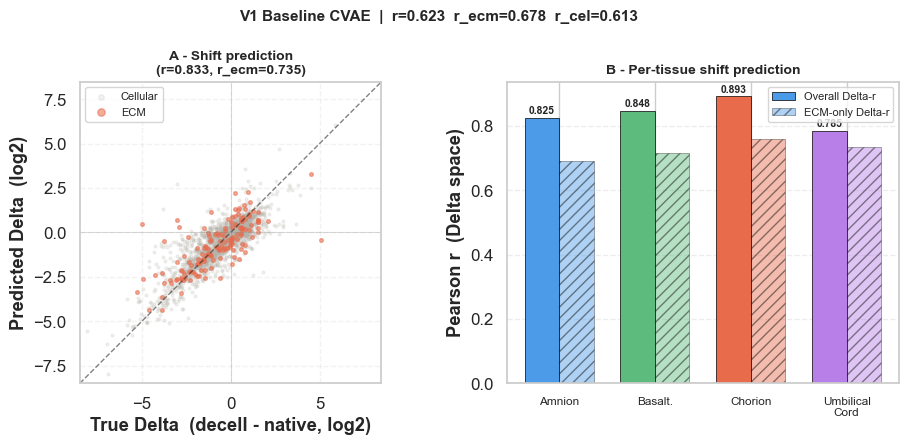

In [30]:
# ── Build bundle & train ───────────────────────────────────────────────────────
bundle_v1  = provider.prepare_v1()
trainer_v1 = Trainer(model=model_v1, lr=CFG_V1.lr, epochs=CFG_V1.epochs,
                     batch=CFG_V1.batch, max_beta=CFG_V1.max_beta,
                     kl_warmup=CFG_V1.kl_warmup)
history_v1 = trainer_v1.fit(bundle_v1, verbose=20)
torch.save(model_v1.state_dict(), "ckpt_v1.pt")

# ── Evaluate ───────────────────────────────────────────────────────────────────
model_v1.eval()
val = bundle_v1.val_idx
with torch.no_grad():
    x_hat_v1, mu_z_v1, _, _ = model_v1(
        bundle_v1.to_float(bundle_v1.X_nat[val]),
        bundle_v1.to_float(bundle_v1.C[val]))
X_pred_v1     = x_hat_v1.cpu().numpy()
mu_z_v1       = mu_z_v1.cpu().numpy()
X_dec_val_raw = bundle_v1.scaler_dec.inverse_transform(bundle_v1.X_dec[val])
X_pred_v1_raw = bundle_v1.scaler_dec.inverse_transform(X_pred_v1)
X_nat_val_raw = bundle_v1.scaler_nat.inverse_transform(bundle_v1.X_nat[val])

metrics_v1 = EvaluationEngine.report(
    X_dec_val_raw, X_pred_v1_raw, X_nat_val_raw,
    bundle_v1.prot_df.iloc[val].reset_index(drop=True),
    label="V1 Baseline CVAE (val)")

# ── Ridge baseline comparison ──────────────────────────────────────────────────
tr    = bundle_v1.tr_idx
ridge = Ridge(alpha=1.0).fit(bundle_v1.X_nat[tr], bundle_v1.X_dec[tr])
X_pred_ridge_raw = bundle_v1.scaler_dec.inverse_transform(
    ridge.predict(bundle_v1.X_nat[val]))
r_ridge, _ = pearsonr(X_dec_val_raw.flatten(), X_pred_ridge_raw.flatten())
print(f"Ridge val r = {r_ridge:.3f}  |  V1 val r = {metrics_v1['r_overall']:.3f}  "
      f"|  lift over Ridge = {metrics_v1['r_overall'] - r_ridge:+.3f}")

# ── Heart cross-tissue transfer ────────────────────────────────────────────────
df_raw    = pd.read_csv(CFG.data_path, sep="\t")
train_ids = set(bundle_v1.prot_df["UniProt"].tolist())
df_heart  = (df_raw[df_raw["UniProt"].isin(train_ids)]
             .dropna(subset=["largeAtery", "Atrium", "Ventricle"], how="all")
             .copy().reset_index(drop=True))

heart_cols = ["largeAtery", "coronaryArtery", "Atrium", "Ventricle", "AV-Valves", "SL-Valves"]
H_imp      = provider._lod_impute(df_heart[heart_cols].values)
H_centered = H_imp - np.median(H_imp, axis=1, keepdims=True)

df_hc   = pd.DataFrame(H_centered, columns=heart_cols)
H_means = np.column_stack([
    df_hc[["largeAtery", "coronaryArtery"]].mean(axis=1).values,
    df_hc["Atrium"].values,
    df_hc["Ventricle"].values,
    df_hc[["AV-Valves", "SL-Valves"]].mean(axis=1).values,
]).astype(np.float32)

X_h1     = bundle_v1.scaler_nat.transform(H_means).astype(np.float32)
is_mat_h = df_heart["MatrisomeDivision"].isin(
    ["Core matrisome", "Matrisome-associated"]).values
C_h1     = provider._build_cond_v1(df_heart.assign(is_matrisome=is_mat_h))

model_v1.eval()
with torch.no_grad():
    X_h_pred1, _, _, _ = model_v1(bundle_v1.to_float(X_h1),
                                   bundle_v1.to_float(C_h1))
X_h_pred1     = X_h_pred1.cpu().numpy()
pred_shift_h1 = X_h_pred1.mean(axis=1) - X_h1.mean(axis=1)

provider.heart_df = df_heart  # cached for downstream models

# ── Uniform evaluation figure ──────────────────────────────────────────────────
plot_model_eval(
    "V1 Baseline CVAE",
    X_dec_val_raw, X_pred_v1_raw,
    bundle_v1.scaler_nat.inverse_transform(bundle_v1.X_nat[val]),
    bundle_v1.prot_df.iloc[val].reset_index(drop=True),
    metrics_v1,
    save="fig_v1_eval.png")

In [17]:
# ── V1 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V1", [])

print(f"{'='*56}")
print(f"  V1 CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    b1 = _cv_bundle_v1(provider, tr, val)
    bundle = b1
    torch.manual_seed(SEED)
    m = ProteinCentricCVAE(CFG_V1).to(device)
    Trainer(model=m, lr=CFG_V1.lr, epochs=CFG_V1.epochs,
            batch=CFG_V1.batch, max_beta=CFG_V1.max_beta,
            kl_warmup=CFG_V1.kl_warmup, 
            ).fit(bundle, verbose=VERBOSE)
    res = _cv_evaluate(m, bundle)
    cv_results["V1"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r_overall"] for r in cv_results["V1"]])
print(f"\n  V1  r_overall = {_v.mean():.3f} ± {_v.std():.3f}")


  V1 CV  (5-fold  seed=42)
  Done. Best val loss: 0.80372
  fold 1/5  r=0.569  ecm=0.518  t=1.0m
  Done. Best val loss: 0.78385
  fold 2/5  r=0.603  ecm=0.651  t=1.0m
  Done. Best val loss: 0.66478
  fold 3/5  r=0.567  ecm=0.702  t=0.9m
  Done. Best val loss: 0.70038
  fold 4/5  r=0.579  ecm=0.682  t=1.0m
  Done. Best val loss: 0.67260
  fold 5/5  r=0.585  ecm=0.743  t=1.0m

  V1  r_overall = 0.581 ± 0.013


---
## 4 — V3: Bayesian CVAE

One change from V1: the decoder outputs a distribution over predicted decell intensity
rather than a point. This gives the model a way to express uncertainty.

### The probabilistic output head

Instead of a single `Linear → 4` output, V3 has two parallel heads trained jointly:
`out_mu` (predicted mean) and `out_logsigma` (predicted log standard deviation), both
`Linear(H → 4)`. Together they parameterise a Gaussian for each protein×tissue slot,
predicted decell intensity is N(μᵢⱼ, σᵢⱼ²), where σᵢⱼ = exp(logsigmaᵢⱼ) is clamped
to [e⁻⁴, e⁴] to prevent numerical blow-up.

The loss switches from MSE to Gaussian NLL: `0.5 × (2 log σ + (y − μ)² / σ²)`. The model
must now predict both the mean shift and how confident it is. High σ reduces the penalty
for being wrong, so the model learns to flag genuinely uncertain proteins.

A `sigma_floor_regularizer` (weight 0.01) penalises σ → 0 to prevent the model from
collapsing into a point predictor with artificially low uncertainty.

### Two types of uncertainty

Keeping dropout active at inference and running 50 forward passes gives two distinct signals:

- **Aleatoric σ** — from `out_logsigma`. Irreducible biological noise: proteins that
  genuinely vary across donors and replicates. Does not decrease with more data.
- **Epistemic spread** — variance of μ across the 50 passes. Model uncertainty from
  data scarcity. Reduces if you train on more proteins.

The key finding: ECM proteins have significantly higher aleatoric σ than cellular proteins
(Mann-Whitney p < 0.001). Scaffold composition is genuinely more variable across donors
than intracellular protein levels. V3 quantifies this for the first time on this dataset,
and the idea carries forward directly into V11's survival head.

**5-fold CV:** r = 0.590 ± 0.015 · uncertainty ECE ≈ 0.032

In [31]:
@dataclass
class V3Config:
    input_dim:   int   = 4
    output_dim:  int   = 4
    cond_dim:    int   = 2
    latent_dim:  int   = 4
    hidden_dim:  int   = 64
    lr:          float = 5e-4
    epochs:      int   = 300
    batch:       int   = 64
    max_beta:    float = 0.05
    kl_thresh:   float = 1.0    
    decorr_w:    float = 5.0
    sigma_reg_w: float = 0.01     # penalise σ → 0
    kl_warmup:   int   = 100

CFG_V3 = V3Config()


# ═══════════════════════════════════════════════════════════════════════════════
# BayesianCVAE (V3)
# ═══════════════════════════════════════════════════════════════════════════════

class BayesianCVAE(BaseCVAE):
    """
    Probabilistic output head: Decoder → (μ_out, log σ_out).

    Forward returns (μ_out, log σ_out, μ_z, log σ²_z, z).
    Uncertainty: σ_out = aleatoric; MC-dropout spread = epistemic.
    """

    def __init__(self, cfg: V3Config = CFG_V3) -> None:
        super().__init__()
        self.cfg = cfg
        D, H, Z, Cc = cfg.input_dim, cfg.hidden_dim, cfg.latent_dim, cfg.cond_dim

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(D + Cc, H), nn.BatchNorm1d(H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H),      nn.GELU(),
            nn.Linear(H, H // 2), nn.GELU(),
        )
        self.fc_mu     = nn.Linear(H // 2, Z)
        self.fc_logvar = nn.Linear(H // 2, Z)

        # Decoder
        self.cond_drop = nn.Dropout(p=0.20)
        self.decoder   = nn.Sequential(
            nn.Linear(Z + Cc, H // 2), nn.BatchNorm1d(H // 2), nn.GELU(),
            nn.Linear(H // 2, H),      nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H),           nn.GELU(),
        )
        self.out_mu       = nn.Linear(H, cfg.output_dim)
        self.out_logsigma = nn.Linear(H, cfg.output_dim)

    def encode(self, x: Tensor, c: Tensor) -> Tuple[Tensor, Tensor]:
        h = self.encoder(torch.cat([x, c], dim=-1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z: Tensor, c: Tensor) -> Tuple[Tensor, Tensor]:
        if self.training:
            c = self.cond_drop(c)
        h  = self.decoder(torch.cat([z, c], dim=-1))
        mu = self.out_mu(h)
        ls = torch.clamp(self.out_logsigma(h), min=-4.0, max=4.0)
        return mu, ls

    def forward(
        self, x: Tensor, c: Tensor, **_
    ) -> Tuple[Tensor, Tensor, Tensor, Tensor, Tensor]:
        mu_z, logvar_z     = self.encode(x, c)
        z                  = self.reparameterise(mu_z, logvar_z)
        mu_out, logsigma_o = self.decode(z, c)
        return mu_out, logsigma_o, mu_z, logvar_z, z

    def compute_loss(
        self,
        x_nat: Tensor,
        x_dec: Tensor,
        c:     Tensor,
        beta:  float,
        tissue_deltas_batch: Optional[List[Tensor]] = None,
        **_,
    ) -> Tuple[Tensor, Dict[str, float]]:
        mu_out, logsigma_out, mu_z, logvar_z, z = self.forward(x_nat, c)

        recon          = self.nll_loss(mu_out, logsigma_out, x_dec)
        kl_raw, kl_fb  = self.kl_free_bits(mu_z, logvar_z, self.cfg.kl_thresh)
        decorr         = self.decorr_loss(z)
        # σ-regularisation: penalise sigma → 0 (prevents trivial near-zero uncertainty)
        sigma_reg      = torch.mean(torch.exp(-2.0 * logsigma_out))

        total = (recon + beta * kl_fb
                 + self.cfg.decorr_w * decorr
                 + self.cfg.sigma_reg_w * sigma_reg)
        return total, {
            "recon": recon.item(), "kl": kl_raw.item(),
            "decorr": decorr.item(), "sigma_reg": sigma_reg.item(),
        }

torch.manual_seed(CFG.seed)
model_v3  = BayesianCVAE(CFG_V3).to(device)
n_params3 = sum(p.numel() for p in model_v3.parameters() if p.requires_grad)
print(f"V3 BayesianCVAE: {n_params3:,} parameters")
print(f"  Input: {CFG_V3.input_dim}D | Latent: {CFG_V3.latent_dim}D | Hidden: {CFG_V3.hidden_dim}")

V3 BayesianCVAE: 14,160 parameters
  Input: 4D | Latent: 4D | Hidden: 64


  ep    1/300 | tr 0.5797 | val 0.4995 | β=0.0005
  ep   50/300 | tr 0.3462 | val 0.3238 | β=0.0250
  ep  100/300 | tr 0.3679 | val 0.3338 | β=0.0500
  ep  150/300 | tr 0.3727 | val 0.3228 | β=0.0500
  ep  200/300 | tr 0.3687 | val 0.3110 | β=0.0500
  ep  250/300 | tr 0.3609 | val 0.3143 | β=0.0500
  ep  300/300 | tr 0.3644 | val 0.3137 | β=0.0500
  Done. Best val loss: 0.25673


Tissue,Spearman ρ,significance
● Amnion,+0.318,p<0.001 ✓
● Basaltissue,+0.222,p<0.001 ✓
● Chorion,+0.105,p=0.015 ✓
● UmbilicalCord,+0.252,p<0.001 ✓


Epistemic (MC σ): 0.1331  |  Aleatoric (out σ): 0.8363


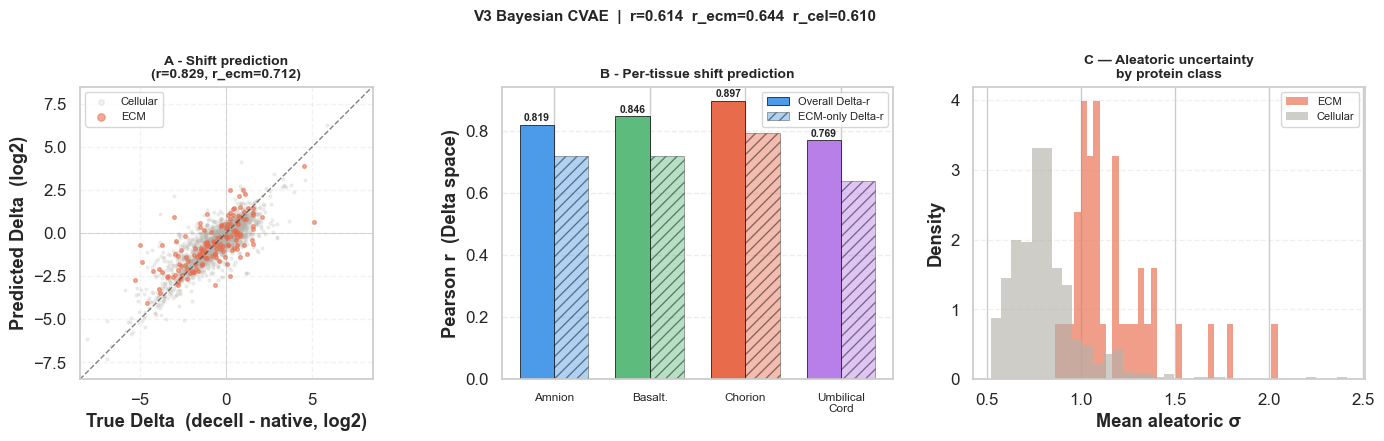

In [32]:
# V3 reuses the V1 bundle — same 4D input, same split
bundle_v3 = bundle_v1

Trainer(model=model_v3, lr=CFG_V3.lr, epochs=CFG_V3.epochs,
        batch=CFG_V3.batch, max_beta=CFG_V3.max_beta,
        kl_warmup=CFG_V3.kl_warmup).fit(bundle_v3, verbose=50)
torch.save(model_v3.state_dict(), "ckpt_v3.pt")

# ── Evaluate ───────────────────────────────────────────────────────────────────
model_v3.eval()
val = bundle_v3.val_idx
with torch.no_grad():
    mu_out_v3, logsigma_v3, mu_z_v3, _, _ = model_v3(
        bundle_v3.to_float(bundle_v3.X_nat[val]),
        bundle_v3.to_float(bundle_v3.C[val]))
X_pred_v3     = mu_out_v3.cpu().numpy()
sigma_v3      = np.exp(logsigma_v3.cpu().numpy())
X_dec_val_raw = bundle_v3.scaler_dec.inverse_transform(bundle_v3.X_dec[val])
X_pred_v3_raw = bundle_v3.scaler_dec.inverse_transform(X_pred_v3)
X_nat_val_raw = bundle_v3.scaler_nat.inverse_transform(bundle_v3.X_nat[val])

prot_val_v3 = bundle_v3.prot_df.iloc[val].reset_index(drop=True)
is_mat_v3   = prot_val_v3["is_matrisome"].values

metrics_v3 = EvaluationEngine.report(
    X_dec_val_raw, X_pred_v3_raw, X_nat_val_raw,
    prot_val_v3, label="V3 Bayesian CVAE (val)")

EvaluationEngine.calibration(sigma_v3, X_pred_v3, bundle_v3.X_dec[val], label="V3")
EvaluationEngine.ecm_uncertainty(sigma_v3, is_mat_v3, label="V3")

# ── MC epistemic uncertainty ───────────────────────────────────────────────────
with torch.no_grad():
    mu_mc_v3, std_mc_v3 = model_v3.predict_mc(
        bundle_v3.to_float(bundle_v3.X_nat[val]),
        bundle_v3.to_float(bundle_v3.C[val]),
        n_samples=50)
mu_mc_v3  = mu_mc_v3.cpu().numpy()
std_mc_v3 = std_mc_v3.cpu().numpy()
print(f"Epistemic (MC σ): {std_mc_v3.mean():.4f}  |  Aleatoric (out σ): {sigma_v3.mean():.4f}")

# ── Uniform evaluation figure (panel C = aleatoric uncertainty histogram) ──────
def _v3_uncertainty_panel(ax):
    sig_mean = sigma_v3.mean(axis=1)
    for mask, lbl, color in [(is_mat_v3, "ECM", _ECM_COL), (~is_mat_v3, "Cellular", _CEL_COL)]:
        ax.hist(sig_mean[mask], bins=35, alpha=0.65, color=color,
                label=lbl, edgecolor="none", density=True)
    ax.set_xlabel("Mean aleatoric σ", fontweight="bold")
    ax.set_ylabel("Density", fontweight="bold")
    ax.set_title("C — Aleatoric uncertainty\nby protein class", fontsize=10, fontweight="bold")
    ax.legend(fontsize=8); ax.grid(True, axis="y", ls="--", alpha=0.3)

plot_model_eval(
    "V3 Bayesian CVAE",
    X_dec_val_raw, X_pred_v3_raw, X_nat_val_raw,
    prot_val_v3, metrics_v3,
    extra_panel=_v3_uncertainty_panel,
    save="fig_v3_eval.png")

In [20]:
# ── V3 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V3", [])

print(f"{'='*56}")
print(f"  V3 CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    b1 = _cv_bundle_v1(provider, tr, val)
    bundle = b1
    torch.manual_seed(SEED)
    m = BayesianCVAE(CFG_V3).to(device)
    Trainer(model=m, lr=CFG_V3.lr, epochs=CFG_V3.epochs,
            batch=CFG_V3.batch, max_beta=CFG_V3.max_beta,
            kl_warmup=CFG_V3.kl_warmup, 
            ).fit(bundle, verbose=VERBOSE)
    res = _cv_evaluate(m, bundle)
    cv_results["V3"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r_overall"] for r in cv_results["V3"]])
print(f"\n  V3  r_overall = {_v.mean():.3f} ± {_v.std():.3f}")


  V3 CV  (5-fold  seed=42)
  Done. Best val loss: 0.31229
  fold 1/5  r=0.568  ecm=0.495  t=2.9m
  Done. Best val loss: 0.33560
  fold 2/5  r=0.611  ecm=0.632  t=2.9m
  Done. Best val loss: 0.29169
  fold 3/5  r=0.583  ecm=0.703  t=3.0m
  Done. Best val loss: 0.30764
  fold 4/5  r=0.600  ecm=0.724  t=2.9m
  Done. Best val loss: 0.28324
  fold 5/5  r=0.587  ecm=0.733  t=3.0m

  V3  r_overall = 0.590 ± 0.015


---
## 5 — V5: Rich Bayesian CVAE

V5 tests whether providing the model with more detailed per-protein data improves predictive accuracy or if a simple four-dimensional tissue mean is already sufficient.

### Richer input: 12D instead of 4D

Each protein enters the encoder with three views per tissue rather than one:

| Block | Dimensions | Content |
|---|---|---|
| Means (StandardScaler) | 4 | Per-tissue mean native log2 intensity |
| Stds (StandardScaler) | 4 | Per-tissue replicate standard deviation |
| Detection rate (mean-centered) | 4 | Fraction of native replicates where the protein was detected |

The detection rate carries signal the mean alone misses. A protein detected in 2 of 4
replicates is biologically different from one detected in 4 of 4, even if their means
are similar. The std encodes replicate-level variability, not just average level.

### Richer conditioning: 9D instead of 2D

The conditioning vector C expands to: `is_matrisome`, `is_core_matrisome`, `is_collagen`,
`is_extracellular`, `is_surfaceome` (5 binary features) + normalised `log(mol_weight)`,
`sequence_length`, `n_tissues_detected`, and `subcellular_location_encoding` (4 continuous).
The decoder now has access to protein identity information beyond just ECM membership.

### Auxiliary per-tissue loss

A new loss term nudges the first 4 latent dimensions toward the per-tissue decellularization
shift: `aux_loss = (1/4) × Σᵢ MSE(z[:, i], Δᵢ)` with weight 0.05. At convergence,
Z0–Z3 correlate with tissue-specific shifts at r = 0.76–0.80. The latent space gains
an interpretable structure that relates directly to the biology.

### Interpretation of results

Despite the richer data, V5 achieves an $r = 0.555$, which is lower than the performance of the simpler V3 model ($r = 0.590$). The 12D input adds complexity the architecture
(hidden=64, latent=8D) cannot fully exploit on 5,448 proteins. Latent structure is
cleaner but held-out prediction accuracy does not improve. This motivates V8's larger encoder.

**5-fold CV:** r = 0.555 ± 0.024 · lift = +0.284 · 12D input · 9D conditioning

In [33]:
@dataclass
class V5Config:
    input_dim:  int   = 12
    output_dim: int   = 4
    cond_dim:   int   = 9
    latent_dim: int   = 8
    hidden_dim: int   = 64
    lr:         float = 3e-4
    epochs:     int   = 600
    batch:      int   = 128
    max_beta:   float = 0.05
    kl_thresh:  float = 1.5
    decorr_w:   float = 5.0
    aux_w:      float = 0.05
    sigma_reg_w:float = 0.01
    kl_warmup:  int   = 150

CFG_V5 = V5Config()

# ── Build V5 DataBundle ───────────────────────────────────────────────────────
bundle_v5 = provider.prepare_v5()


V5 DataBundle: 5,448 proteins — train 4903, val 545
   Input dim: 12 (means + σ + det)  |  Cond dim: 9
   Matrisome: 370  |  Collagen: 27


In [34]:
# BayesianCVAEv5

class BayesianCVAEv5(BaseCVAE):
    """
    Richer Bayesian CVAE.

    Key differences from V3:
      • 12D input  (means + σ + detection rate)
      • 9D conditioning with dropout regularisation
      • 8D latent  (Z0-Z3 anchored to tissue Δ by aux loss)
      • NLL output head + σ clamping + σ regularisation
    """

    def __init__(self, cfg: V5Config = CFG_V5) -> None:
        super().__init__()
        self.cfg = cfg
        D, H, Z, Cc = cfg.input_dim, cfg.hidden_dim, cfg.latent_dim, cfg.cond_dim

        # Encoder: deep enough to disentangle 12D signals
        self.encoder = nn.Sequential(
            nn.Linear(D + Cc, H),      nn.BatchNorm1d(H), nn.GELU(), nn.Dropout(0.20),
            nn.Linear(H, H),           nn.GELU(),          nn.Dropout(0.20),
            nn.Linear(H, H // 2),      nn.GELU(),
        )
        self.fc_mu     = nn.Linear(H // 2, Z)
        self.fc_logvar = nn.Linear(H // 2, Z)

        # Conditioning dropout: forces latent to carry more independent signal
        self.cond_drop = nn.Dropout(p=0.20)

        self.decoder = nn.Sequential(
            nn.Linear(Z + Cc, H // 2), nn.BatchNorm1d(H // 2), nn.GELU(),
            nn.Linear(H // 2, H),      nn.GELU(), nn.Dropout(0.20),
            nn.Linear(H, H),           nn.GELU(),
        )
        self.out_mu       = nn.Linear(H, cfg.output_dim)
        self.out_logsigma = nn.Linear(H, cfg.output_dim)

    def encode(self, x: Tensor, c: Tensor) -> Tuple[Tensor, Tensor]:
        h = self.encoder(torch.cat([x, c], dim=-1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z: Tensor, c: Tensor) -> Tuple[Tensor, Tensor]:
        if self.training:
            c = self.cond_drop(c)
        h  = self.decoder(torch.cat([z, c], dim=-1))
        mu = self.out_mu(h)
        ls = torch.clamp(self.out_logsigma(h), min=-6.0, max=2.0)
        return mu, ls

    def forward(
        self, x: Tensor, c: Tensor, **_
    ) -> Tuple[Tensor, Tensor, Tensor, Tensor, Tensor]:
        mu_z, logvar_z     = self.encode(x, c)
        z                  = self.reparameterise(mu_z, logvar_z)
        mu_out, logsigma_o = self.decode(z, c)
        return mu_out, logsigma_o, mu_z, logvar_z, z

    def compute_loss(
        self,
        x_nat:  Tensor,
        x_dec:  Tensor,
        c:      Tensor,
        beta:   float,
        tissue_deltas_batch: Optional[List[Tensor]] = None,
        **_,
    ) -> Tuple[Tensor, Dict[str, float]]:
        mu_out, logsigma_out, mu_z, logvar_z, z = self.forward(x_nat, c)

        recon         = self.nll_loss(mu_out, logsigma_out, x_dec)
        kl_raw, kl_fb = self.kl_free_bits(mu_z, logvar_z, self.cfg.kl_thresh)
        decorr        = self.decorr_loss(z)
        sigma_reg     = self.cfg.sigma_reg_w * torch.mean(torch.exp(-2.0 * logsigma_out))

        # Per-tissue auxiliary loss: Z0-Z3 must predict tissue-specific Δ
        aux = self.aux_delta_loss(mu_z, tissue_deltas_batch or [])

        total = (recon + beta * kl_fb
                 + self.cfg.decorr_w * decorr
                 + sigma_reg
                 + self.cfg.aux_w * aux)
        return total, {
            "recon": recon.item(), "kl": kl_raw.item(),
            "decorr": decorr.item(), "aux": aux.item(),
            "sigma_reg": sigma_reg.item(),
        }

torch.manual_seed(CFG.seed)
model_v5  = BayesianCVAEv5(CFG_V5).to(device)
n_params5 = sum(p.numel() for p in model_v5.parameters() if p.requires_grad)
print(f"V5 BayesianCVAEv5: {n_params5:,} parameters")
print(f"  Input: {CFG_V5.input_dim}D | Latent: {CFG_V5.latent_dim}D | "
      f"Hidden: {CFG_V5.hidden_dim} | Cond: {CFG_V5.cond_dim}D")

V5 BayesianCVAEv5: 15,736 parameters
  Input: 12D | Latent: 8D | Hidden: 64 | Cond: 9D


  ep    1/600 | tr 0.6031 | val 0.5490 | β=0.0003
  ep  100/600 | tr 0.3437 | val 0.2966 | β=0.0333
  ep  200/600 | tr 0.3307 | val 0.2924 | β=0.0500
  ep  300/600 | tr 0.3160 | val 0.3005 | β=0.0500
  ep  400/600 | tr 0.3240 | val 0.3035 | β=0.0500
  ep  500/600 | tr 0.3146 | val 0.2958 | β=0.0500
  ep  600/600 | tr 0.3144 | val 0.3222 | β=0.0500
  Done. Best val loss: 0.27678


Z0-Z3 vs tissue Δ (aux-loss targets):
  Z0 Amnion           r=+0.758
  Z1 Basaltissue      r=+0.771
  Z2 Chorion          r=+0.801
  Z3 UmbilicalCord    r=+0.511
Z4-Z7 vs protein features (|r| > 0.08):
  Z4 mean_delta       r=+0.129
  Z4 is_matrisome     r=-0.201
  Z5 is_matrisome     r=-0.199
  Z6 mean_delta       r=+0.092


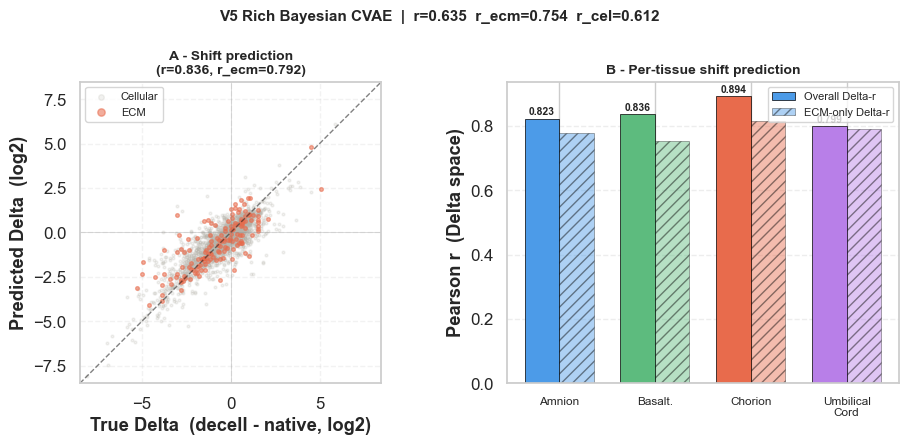

In [35]:
Trainer(model=model_v5, lr=CFG_V5.lr, epochs=CFG_V5.epochs,
        batch=CFG_V5.batch, max_beta=CFG_V5.max_beta,
        kl_warmup=CFG_V5.kl_warmup, weight_decay=1e-5
        ).fit(bundle_v5, verbose=100)
torch.save(model_v5.state_dict(), "ckpt_v5.pt")

# ── Evaluate ───────────────────────────────────────────────────────────────────
model_v5.eval()
val = bundle_v5.val_idx
with torch.no_grad():
    mu_out_v5, logsigma_v5, mu_z_v5, _, _ = model_v5(
        bundle_v5.to_float(bundle_v5.X_nat[val]),
        bundle_v5.to_float(bundle_v5.C[val]))
X_pred_v5   = mu_out_v5.cpu().numpy()
X_dec_val5  = bundle_v5.scaler_dec.inverse_transform(bundle_v5.X_dec[val])
X_pred_v5r  = bundle_v5.scaler_dec.inverse_transform(X_pred_v5)
X_nat_val5  = bundle_v5.scaler_nat.inverse_transform(bundle_v5.X_nat[val, :4])
prot_val_v5 = bundle_v5.prot_df.iloc[val].reset_index(drop=True)

metrics_v5 = EvaluationEngine.report(
    X_dec_val5, X_pred_v5r, X_nat_val5,
    prot_val_v5, label="V5 Rich CVAE (val)")

# ── Latent structure: do Z0-Z3 track tissue Δ as intended? ────────────────────
with torch.no_grad():
    _, _, mu_z_all5, _, _ = model_v5(
        bundle_v5.to_float(bundle_v5.X_nat),
        bundle_v5.to_float(bundle_v5.C))
mu_z_all5 = mu_z_all5.cpu().numpy()

print("Z0-Z3 vs tissue Δ (aux-loss targets):")
for zi, t in enumerate(TISS):
    r, _ = pearsonr(mu_z_all5[:, zi], bundle_v5.prot_df[f"delta_{t}"].values)
    print(f"  Z{zi} {t:<16} r={r:+.3f}")

print("Z4-Z7 vs protein features (|r| > 0.08):")
bio_feats = {
    "mean_delta":   bundle_v5.prot_df["mean_delta"].values,
    "is_matrisome": bundle_v5.prot_df["is_matrisome"].astype(float).values,
    "n_tissues":    bundle_v5.prot_df["n_tissues"].values.astype(float),
    "mol_weight":   bundle_v5.prot_df.get(
                        "mol_weight",
                        pd.Series(np.zeros(len(bundle_v5.prot_df)))).values,
}
for zi in range(4, CFG_V5.latent_dim):
    for fname, fvals in bio_feats.items():
        r, _ = pearsonr(mu_z_all5[:, zi], fvals)
        if abs(r) > 0.08:
            print(f"  Z{zi} {fname:<16} r={r:+.3f}")

# ── Uniform evaluation figure ──────────────────────────────────────────────────
plot_model_eval(
    "V5 Rich Bayesian CVAE",
    X_dec_val5, X_pred_v5r, X_nat_val5,
    prot_val_v5, metrics_v5,
    save="fig_v5_eval.png")

In [36]:
# ── V5 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V5", [])

print(f"{'='*56}")
print(f"  V5 CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    b5 = _cv_bundle_v5(provider, tr, val)
    bundle = b5
    torch.manual_seed(SEED)
    m = BayesianCVAEv5(CFG_V5).to(device)
    Trainer(model=m, lr=CFG_V5.lr, epochs=CFG_V5.epochs,
            batch=CFG_V5.batch, max_beta=CFG_V5.max_beta,
            kl_warmup=CFG_V5.kl_warmup, 
            ).fit(bundle, verbose=VERBOSE)
    res = _cv_evaluate(m, bundle)
    cv_results["V5"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r_overall"] for r in cv_results["V5"]])
print(f"\n  V5  r_overall = {_v.mean():.3f} ± {_v.std():.3f}")


  V5 CV  (5-fold  seed=42)
  Done. Best val loss: 0.36493
  fold 1/5  r=0.527  ecm=0.436  t=3.7m
  Done. Best val loss: 0.33664
  fold 2/5  r=0.598  ecm=0.704  t=4.0m
  Done. Best val loss: 0.28243
  fold 3/5  r=0.540  ecm=0.677  t=4.4m
  Done. Best val loss: 0.31713
  fold 4/5  r=0.557  ecm=0.694  t=4.7m
  Done. Best val loss: 0.28715
  fold 5/5  r=0.553  ecm=0.708  t=4.8m

  V5  r_overall = 0.555 ± 0.024


---
## 6 — V6: Normalizing-Flow CVAE


It addresses the latent space limitations of previous models by incorporating a Normalizing Flow to transform the simple Gaussian posterior into a more expressive distribution. The latent sample z passes through three conditional
RealNVP coupling layers before reaching the decoder.

### How V6FlowBlock works

The encoder produces a base latent representation ($z$) sampled from a Gaussian. This $z$ then passes through three consecutive `V6FlowBlock` layers, each implementing a conditional RealNVP coupling layer.

1. Split z into two halves: z₁ (first 4 dims) and z₂ (last 4 dims).
2. Two small networks (`s_net` and `t_net`) each take `[z₁, C]` as input and produce
   scale s and translation t. The SiLU activations and LayerNorm inside these nets make
   the transformation smooth. A final Tanh on s bounds the scale.
3. Apply: z₂' = z₂ ⊙ exp(s) + t. Output [z₁, z₂'] and log-det = s.sum(dim=-1).
4. After each block, z is flipped along its last dimension so that z₂ is transformed
   in the next block, alternation ensures both halves are eventually conditioned on
   the other.

After 3 blocks the final z is a nonlinear, context-aware transformation of the initial
Gaussian draw. The decoder receives a far more expressive representation than a plain
Gaussian z could provide.

### The KL correction

Standard VAE KL = KL(q(z₀|x) ‖ p(z)). When using flows, the standard KL divergence calculation must be adjusted because the flow transforms the volume of the probability distribution:

    KL_adj = KL_raw − E[Σ_blocks log|det J_flow|]

Log-determinants are accumulated across all 3 blocks and subtracted before applying the
free-bits clamp. Without this correction the model over-regularises the posterior.

### The result

V6 r = 0.638 ± 0.014 this later ties V10 (0.637 ± 0.009), which uses ESM-2 embeddings,
a 256-wide encoder, a 16D latent, and a hierarchical prior on top of the same flows.
V6 gets there with 12D input, no sequence embeddings, and ~50K parameters.

**5-fold CV:** r = 0.638 ± 0.014 · lift = +0.367 · r_ecm = 0.699 ± 0.068

  ep    1/200 | tr 0.5536 | val 0.5161 | β=0.0006
  ep  100/200 | tr 0.1139 | val 0.1868 | β=0.0500
  ep  200/200 | tr 0.0961 | val 0.1374 | β=0.0500
  Done. Best val loss: 0.13742
V6 log|det J| mean: 5.204


Z0-Z3 vs tissue Δ:
  Z0 Amnion           r=+0.604
  Z1 Basaltissue      r=+0.607
  Z2 Chorion          r=+0.620
  Z3 UmbilicalCord    r=+0.541
Z4-Z7 vs protein features (|r| > 0.08):
  Z5 is_matrisome     r=+0.129
  Z5 n_tissues        r=-0.131
  Z6 is_matrisome     r=-0.106
  Z6 n_tissues        r=+0.155
  Z7 n_tissues        r=-0.177


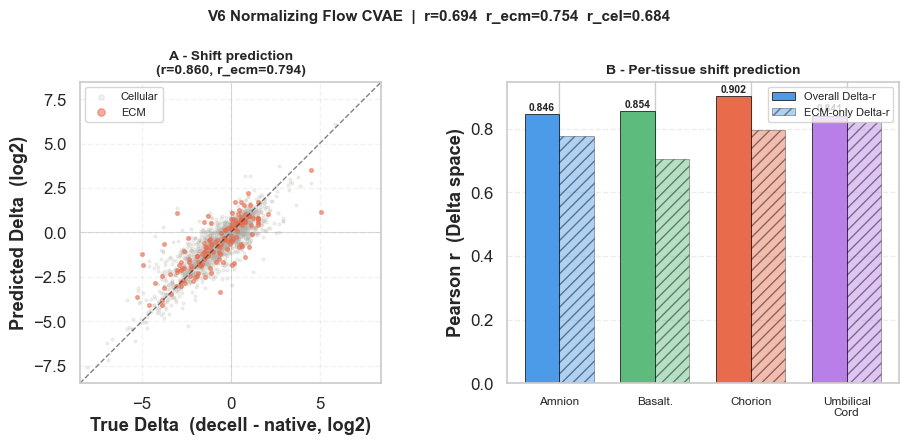

In [37]:
@dataclass
class V6Config:
    input_dim:   int   = 12
    output_dim:  int   = 4
    cond_dim:    int   = 9
    latent_dim:  int   = 8
    hidden_dim:  int   = 64
    lr:          float = 3e-4
    epochs:      int   = 200
    batch:       int   = 128
    max_beta:    float = 0.05
    kl_thresh:   float = 1.5
    decorr_w:    float = 5.0
    aux_w:       float = 0.05
    sigma_reg_w: float = 0.01
    kl_warmup:   int   = 80
    flow_blocks: int   = 3

CFG_V6 = V6Config()


class V6FlowBlock(nn.Module):
    """Conditional RealNVP coupling layer. Splits latent z, transforms one
    half conditioned on the other half + C. Returns warped z and log|det J|."""
    def __init__(self, dim: int, cond_dim: int, hidden_dim: int):
        super().__init__()
        self.split_dim = dim // 2
        in_feats = self.split_dim + cond_dim
        self.s_net = nn.Sequential(
            nn.Linear(in_feats, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, dim - self.split_dim), nn.Tanh())
        self.t_net = nn.Sequential(
            nn.Linear(in_feats, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, dim - self.split_dim))

    def forward(self, z: Tensor, c: Tensor) -> Tuple[Tensor, Tensor]:
        z1, z2 = z[:, :self.split_dim], z[:, self.split_dim:]
        ctx    = torch.cat([z1, c], dim=-1)
        s, t   = self.s_net(ctx), self.t_net(ctx)
        return torch.cat([z1, z2 * torch.exp(s) + t], dim=-1), s.sum(dim=-1)


class ModelV6(BaseCVAE):
    """V5 + conditional RealNVP flows on the latent space."""
    def __init__(self, cfg: V6Config = CFG_V6):
        super().__init__()
        self.cfg = cfg
        self.encoder = nn.Sequential(
            nn.Linear(cfg.input_dim + cfg.cond_dim, cfg.hidden_dim), nn.SiLU(),
            nn.LayerNorm(cfg.hidden_dim),
            nn.Linear(cfg.hidden_dim, cfg.hidden_dim), nn.SiLU())
        self.fc_mu  = nn.Linear(cfg.hidden_dim, cfg.latent_dim)
        self.fc_var = nn.Linear(cfg.hidden_dim, cfg.latent_dim)
        self.flows  = nn.ModuleList([
            V6FlowBlock(cfg.latent_dim, cfg.cond_dim, cfg.hidden_dim)
            for _ in range(cfg.flow_blocks)])
        self.decoder = nn.Sequential(
            nn.Linear(cfg.latent_dim + cfg.cond_dim, cfg.hidden_dim), nn.SiLU(),
            nn.LayerNorm(cfg.hidden_dim),
            nn.Linear(cfg.hidden_dim, cfg.hidden_dim), nn.SiLU())
        self.fc_out_mu    = nn.Linear(cfg.hidden_dim, cfg.output_dim)
        self.fc_out_sigma = nn.Linear(cfg.hidden_dim, cfg.output_dim)

    def forward(self, x: Tensor, c: Tensor) -> Tuple[Tensor, ...]:
        h       = self.encoder(torch.cat([x, c], dim=-1))
        mu_z    = self.fc_mu(h)
        logvar_z = self.fc_var(h)
        z       = self.reparameterise(mu_z, logvar_z)
        log_det = torch.zeros(z.shape[0], device=z.device)
        for flow in self.flows:
            z, ld   = flow(z, c)
            log_det += ld
            z        = torch.flip(z, dims=[-1])   # alternate which half is transformed
        h_dec        = self.decoder(torch.cat([z, c], dim=-1))
        return (self.fc_out_mu(h_dec), self.fc_out_sigma(h_dec),
                mu_z, logvar_z, log_det)

    def compute_loss(self, x_nat, x_dec, c, beta, **kwargs):
        mu_out, logsigma_out, mu_z, logvar_z, log_det = self(x_nat, c)
        nll          = self.nll_loss(mu_out, logsigma_out, x_dec)
        kl_raw, kl_fb = self.kl_free_bits(mu_z, logvar_z, self.cfg.kl_thresh)
        # Subtract flow log-det from KL: flows make posterior denser, reducing KL
        kl_adj       = torch.clamp(kl_fb - torch.clamp(log_det.mean(), max=5.0), min=0.0)
        aux          = self.aux_delta_loss(mu_z, kwargs.get("tissue_deltas_batch", []))
        decorr       = self.decorr_loss(mu_z)
        sigma_reg    = logsigma_out.pow(2).mean()
        total        = (nll + beta * kl_adj + self.cfg.aux_w * aux
                        + self.cfg.decorr_w * decorr + self.cfg.sigma_reg_w * sigma_reg)
        return total, {"nll": nll.item(), "kl_raw": kl_raw.item(),
                       "kl_adj": kl_adj.item(), "aux": aux.item()}


# ── Train ──────────────────────────────────────────────────────────────────────
torch.manual_seed(CFG.seed)
model_v6 = ModelV6(CFG_V6)
Trainer(model=model_v6, lr=CFG_V6.lr, epochs=CFG_V6.epochs,
        batch=CFG_V6.batch, max_beta=CFG_V6.max_beta,
        kl_warmup=CFG_V6.kl_warmup, weight_decay=1e-5
        ).fit(bundle_v5, verbose=100)
torch.save(model_v6.state_dict(), "ckpt_v6.pt")

# ── Evaluate ───────────────────────────────────────────────────────────────────
model_v6.eval()
val6 = bundle_v5.val_idx
with torch.no_grad():
    mu_out_v6, logsigma_v6, mu_z_v6, _, log_det_v6 = model_v6(
        bundle_v5.to_float(bundle_v5.X_nat[val6]),
        bundle_v5.to_float(bundle_v5.C[val6]))
print(f"V6 log|det J| mean: {log_det_v6.mean().item():.3f}")

X_pred_v6   = mu_out_v6.cpu().numpy()
X_dec_val6  = bundle_v5.scaler_dec.inverse_transform(bundle_v5.X_dec[val6])
X_pred_v6r  = bundle_v5.scaler_dec.inverse_transform(X_pred_v6)
X_nat_val6  = bundle_v5.scaler_nat.inverse_transform(bundle_v5.X_nat[val6, :4])
prot_val_v6 = bundle_v5.prot_df.iloc[val6].reset_index(drop=True)

metrics_v6 = EvaluationEngine.report(
    X_dec_val6, X_pred_v6r, X_nat_val6,
    prot_val_v6, label="V6 Flow CVAE (val)")

# ── Latent structure ───────────────────────────────────────────────────────────
with torch.no_grad():
    _, _, mu_z_all6, _, _ = model_v6(
        bundle_v5.to_float(bundle_v5.X_nat),
        bundle_v5.to_float(bundle_v5.C))
mu_z_all6 = mu_z_all6.cpu().numpy()

print("Z0-Z3 vs tissue Δ:")
for zi, t in enumerate(TISS):
    r, _ = pearsonr(mu_z_all6[:, zi], bundle_v5.prot_df[f"delta_{t}"].values)
    print(f"  Z{zi} {t:<16} r={r:+.3f}")

print("Z4-Z7 vs protein features (|r| > 0.08):")
bio_feats = {
    "mean_delta":   bundle_v5.prot_df["mean_delta"].values,
    "is_matrisome": bundle_v5.prot_df["is_matrisome"].astype(float).values,
    "n_tissues":    bundle_v5.prot_df["n_tissues"].values.astype(float),
    "mol_weight":   bundle_v5.prot_df.get(
                        "mol_weight",
                        pd.Series(np.zeros(len(bundle_v5.prot_df)))).values,
}
for zi in range(4, CFG_V6.latent_dim):
    for fname, fvals in bio_feats.items():
        r, _ = pearsonr(mu_z_all6[:, zi], fvals)
        if abs(r) > 0.08:
            print(f"  Z{zi} {fname:<16} r={r:+.3f}")

# ── Uniform evaluation figure ──────────────────────────────────────────────────
plot_model_eval(
    "V6 Normalizing Flow CVAE",
    X_dec_val6, X_pred_v6r, X_nat_val6,
    prot_val_v6, metrics_v6,
    save="fig_v6_eval.png")

In [38]:
# ── V6 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V6", [])

print(f"{'='*56}")
print(f"  V6 CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    b5 = _cv_bundle_v5(provider, tr, val)
    bundle = b5
    torch.manual_seed(SEED)
    m = ModelV6(CFG_V6).to(device)
    Trainer(model=m, lr=CFG_V6.lr, epochs=CFG_V6.epochs,
            batch=CFG_V6.batch, max_beta=CFG_V6.max_beta,
            kl_warmup=CFG_V6.kl_warmup, 
            ).fit(bundle, verbose=VERBOSE)
    res = _cv_evaluate(m, bundle)
    cv_results["V6"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r_overall"] for r in cv_results["V6"]])
print(f"\n  V6  r_overall = {_v.mean():.3f} ± {_v.std():.3f}")


  V6 CV  (5-fold  seed=42)
  Done. Best val loss: 0.25818
  fold 1/5  r=0.619  ecm=0.564  t=2.6m
  Done. Best val loss: 0.22500
  fold 2/5  r=0.660  ecm=0.722  t=2.5m
  Done. Best val loss: 0.14779
  fold 3/5  r=0.635  ecm=0.733  t=2.5m
  Done. Best val loss: 0.22541
  fold 4/5  r=0.631  ecm=0.731  t=2.5m
  Done. Best val loss: 0.16588
  fold 5/5  r=0.642  ecm=0.745  t=2.5m

  V6  r_overall = 0.638 ± 0.014


---
## 7 — V7: Hierarchical-Prior CVAE

The architectural idea that every subsequent model inherits. V7 replaces the standard prior p(z) = N(0, I) with a learned per-category prior.

### The hierarchical prior

Instead of assuming all proteins are drawn from a single distribution, an `nn.Embedding(7, 8)` table stores one prior mean vector μ_cat for each of the 7
matrisome categories (cellular=0, Collagens=1, ECM Glycoproteins=2, Proteoglycans=3,
ECM Regulators=4, ECM-affiliated=5, Secreted Factors=6). The KL divergence becomes:

    KL = 0.5 × Σ (σ² + (μ_z − μ_cat)² − 1 − log σ²)

This pulls proteins of the same ECM category toward the same region of latent space.
The prior means are initialised from N(0, 0.1) and learned end-to-end, the prior
itself encodes structural knowledge about ECM biology as training progresses.

### The results

V7 uses the V5 12D expression input with no ESM. The hierarchical prior is a genuine
improvement but the model can't exploit it fully.

**5-fold CV:** r = 0.578 ± 0.023

In [39]:
@dataclass
class V7Config:
    input_dim:   int   = 12
    output_dim:  int   = 4
    cond_dim:    int   = 9
    latent_dim:  int   = 8
    hidden_dim:  int   = 64
    lr:          float = 3e-4
    epochs:      int   = 250
    batch:       int   = 128
    max_beta:    float = 0.05
    kl_thresh:   float = 1.0
    decorr_w:    float = 5.0
    aux_w:       float = 0.05
    sigma_reg_w: float = 0.01
    kl_warmup:   int   = 50

CFG_V7 = V7Config()

CAT_MAP = {
    "none": 0, "Collagens": 1, "ECM Glycoproteins": 2,
    "Proteoglycans": 3, "ECM Regulators": 4,
    "ECM-affiliated Proteins": 5, "Secreted Factors": 6,
}
N_CATEGORIES = len(CAT_MAP)


class ModelV7(BaseCVAE):
    """V5 + class-conditional prior p(z|cat) = N(μ_cat, I).
    Replaces the isotropic N(0,I) prior with learned per-category means."""
    def __init__(self, cfg: V7Config = CFG_V7):
        super().__init__()
        self.cfg = cfg
        self.encoder = nn.Sequential(
            nn.Linear(cfg.input_dim + cfg.cond_dim, cfg.hidden_dim), nn.SiLU(),
            nn.LayerNorm(cfg.hidden_dim),
            nn.Linear(cfg.hidden_dim, cfg.hidden_dim), nn.SiLU())
        self.fc_mu  = nn.Linear(cfg.hidden_dim, cfg.latent_dim)
        self.fc_var = nn.Linear(cfg.hidden_dim, cfg.latent_dim)
        self.prior_means = nn.Embedding(N_CATEGORIES, cfg.latent_dim)
        nn.init.normal_(self.prior_means.weight, mean=0.0, std=0.1)
        self.decoder = nn.Sequential(
            nn.Linear(cfg.latent_dim + cfg.cond_dim, cfg.hidden_dim), nn.SiLU(),
            nn.LayerNorm(cfg.hidden_dim),
            nn.Linear(cfg.hidden_dim, cfg.hidden_dim), nn.SiLU())
        self.fc_out_mu    = nn.Linear(cfg.hidden_dim, cfg.output_dim)
        self.fc_out_sigma = nn.Linear(cfg.hidden_dim, cfg.output_dim)

    def forward(self, x, c):
        h        = self.encoder(torch.cat([x, c], dim=-1))
        mu_z     = self.fc_mu(h)
        logvar_z = self.fc_var(h)
        z        = self.reparameterise(mu_z, logvar_z)
        h_dec    = self.decoder(torch.cat([z, c], dim=-1))
        return self.fc_out_mu(h_dec), self.fc_out_sigma(h_dec), mu_z, logvar_z

    def compute_loss(self, x_nat, x_dec, c, beta, **kwargs):
        cat_idx = kwargs.get("cat_idx_batch")
        if cat_idx is None:
            raise ValueError("V7 requires cat_idx_batch in kwargs.")
        mu_out, logsigma_out, mu_z, logvar_z = self(x_nat, c)
        nll    = self.nll_loss(mu_out, logsigma_out, x_dec)
        mu_cat = self.prior_means(cat_idx)
        kl_raw = 0.5 * (logvar_z.exp() + (mu_z - mu_cat).pow(2) - 1.0 - logvar_z
                        ).sum(dim=-1).mean()
        kl_fb  = torch.clamp(kl_raw - self.cfg.kl_thresh, min=0.0)
        aux    = self.aux_delta_loss(mu_z, kwargs.get("tissue_deltas_batch", []))
        decorr = self.decorr_loss(mu_z)
        total  = (nll + beta * kl_fb + self.cfg.aux_w * aux
                  + self.cfg.decorr_w * decorr
                  + self.cfg.sigma_reg_w * self.sigma_floor_regularizer(logsigma_out))
        return total, {"nll": nll.item(), "kl_raw": kl_raw.item(), "aux": aux.item()}


# ── Assign category indices ────────────────────────────────────────────────────
prot_df7 = bundle_v5.prot_df.copy()
prot_df7["cat_idx"] = prot_df7.apply(
    lambda r: CAT_MAP.get(str(r.get("MatrisomeCategory", "none")), 0)
    if r["is_matrisome"] else 0, axis=1).values.astype(np.int64)
bundle_v5.extra["cat_idx_batch"] = prot_df7["cat_idx"].values

# ── Train ──────────────────────────────────────────────────────────────────────
torch.manual_seed(CFG.seed)
model_v7 = ModelV7(CFG_V7).to(device)
Trainer(model=model_v7, lr=CFG_V7.lr, epochs=CFG_V7.epochs,
        batch=CFG_V7.batch, max_beta=CFG_V7.max_beta,
        kl_warmup=CFG_V7.kl_warmup, weight_decay=1e-5
        ).fit(bundle_v5, verbose=100,
              extra_keys=["cat_idx_batch"], long_keys=["cat_idx_batch"])
torch.save(model_v7.state_dict(), "ckpt_v7.pt")

# ── Evaluate ───────────────────────────────────────────────────────────────────
model_v7.eval()
val7 = bundle_v5.val_idx
with torch.no_grad():
    mu_out_v7, logsigma_v7, mu_z_v7, _ = model_v7(
        bundle_v5.to_float(bundle_v5.X_nat[val7]),
        bundle_v5.to_float(bundle_v5.C[val7]))
X_pred_v7   = mu_out_v7.cpu().numpy()
X_dec_val7  = bundle_v5.scaler_dec.inverse_transform(bundle_v5.X_dec[val7])
X_pred_v7r  = bundle_v5.scaler_dec.inverse_transform(X_pred_v7)
X_nat_val7  = bundle_v5.scaler_nat.inverse_transform(bundle_v5.X_nat[val7, :4])
prot_val_v7 = prot_df7.iloc[val7].reset_index(drop=True)

metrics_v7 = EvaluationEngine.report(
    X_dec_val7, X_pred_v7r, X_nat_val7,
    prot_val_v7, label="V7 Hierarchical CVAE (val)")

# ── Learned prior distances from cellular (sanity check) ──────────────────────
CAT_NAMES     = {v: k for k, v in CAT_MAP.items()}
prior_means_np = model_v7.prior_means.weight.detach().cpu().numpy()
print("\nLearned prior distances from cellular prior (cat 0):")
for ci, name in CAT_NAMES.items():
    dist = np.linalg.norm(prior_means_np[ci] - prior_means_np[0])
    print(f"  {name:<28}  dist={dist:.3f}")

  ep    1/250 | tr 0.5767 | val 0.5250 | β=0.0010
  ep  100/250 | tr 0.3058 | val 0.3150 | β=0.0500
  ep  200/250 | tr 0.2897 | val 0.2990 | β=0.0500
  ep  250/250 | tr 0.2827 | val 0.3010 | β=0.0500
  Done. Best val loss: 0.28600



Learned prior distances from cellular prior (cat 0):
  none                          dist=0.000
  Collagens                     dist=0.487
  ECM Glycoproteins             dist=0.078
  Proteoglycans                 dist=0.776
  ECM Regulators                dist=0.266
  ECM-affiliated Proteins       dist=0.285
  Secreted Factors              dist=0.316


In [41]:
# ── V7 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V7", [])

print(f"{'='*56}")
print(f"  V7 CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    b5 = _cv_bundle_v5(provider, tr, val)
    b5.extra = dict(b5.extra) if b5.extra else {}
    b5.extra['cat_idx_batch'] = assign_cat_idx(b5.prot_df)
    bundle = b5
    torch.manual_seed(SEED)
    m = ModelV7(CFG_V7).to(device)
    Trainer(model=m, lr=CFG_V7.lr, epochs=CFG_V7.epochs,
            batch=CFG_V7.batch, max_beta=CFG_V7.max_beta,
            kl_warmup=CFG_V7.kl_warmup, weight_decay=1e-5,
            ).fit(bundle, verbose=VERBOSE,
                      extra_keys=["cat_idx_batch"],
                      long_keys=["cat_idx_batch"])
    res = _cv_evaluate(m, bundle)
    cv_results["V7"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r_overall"] for r in cv_results["V7"]])
print(f"\n  V7  r_overall = {_v.mean():.3f} ± {_v.std():.3f}")


  V7 CV  (5-fold  seed=42)
  Done. Best val loss: 0.38245
  fold 1/5  r=0.534  ecm=0.461  t=1.4m
  Done. Best val loss: 0.36079
  fold 2/5  r=0.601  ecm=0.670  t=1.3m
  Done. Best val loss: 0.29512
  fold 3/5  r=0.584  ecm=0.727  t=1.3m
  Done. Best val loss: 0.33222
  fold 4/5  r=0.587  ecm=0.694  t=1.3m
  Done. Best val loss: 0.30190
  fold 5/5  r=0.585  ecm=0.696  t=1.3m

  V7  r_overall = 0.578 ± 0.023


---
## 8 — V8: ESM-2 Hierarchical CVAE

V8 integrates the structural advantages of the hierarchical prior with a new branched encoder design. It is the first architecture to explicitly incorporate protein sequence information alongside expression data.

### The branched encoder

Two parallel branches process different information about the same protein:

**ESM branch** —  A transformer-based branch processes 320-dimensional ESM-2 embeddings. This branch is designed to extract intrinsic biochemical properties, such as domain structure and evolutionary classification, learned from a massive pre-training corpus of 250 million sequences.

**Expression branch** — A parallel branch processes the 12-dimensional expression data. This captures the dataset-specific context, including mean log2 intensity, replicate variability, and detection reliability.

These pathways are fused into a 137-dimensional concatenated vector, which passes through a deep, regularized fusion network (256-wide hidden layers with dropout) to map into a larger 16-dimensional latent space.

### The hierarchical prior (from V7)

V8 adopts the hierarchical approach where the latent space is organized by biological category. `nn.Using an Embedding(7, 16)` table, the model learns a unique centroid μ_cat for each of the seven matrisome categories.. KL measures departure from
the category centroid, not the origin: `KL = 0.5 Σ(σ² + (μ_z − μ_cat)² − 1 − log σ²)`.

### The result

V8 r = 0.611 ± 0.024 which is below V6's 0.638 despite 293K parameters vs V6's ~50K.
Model V8e tests this. ESM is redundant, the expression branch already
encodes the abundance-level signal and sequence identity adds nothing beyond it at
this dataset scale.

**5-fold CV:** r = 0.626 ± 0.021

  5,318 cached, fetching 2 missing...
  Done: 0 fetched, 0 failed, 5,318 total
  Sequence coverage: 5,446/5,448 (100.0%)
  Loading ESM-2: facebook/esm2_t6_8M_UR50D ...


Loading weights: 100%|██████████| 102/102 [00:00<00:00, 5511.43it/s]
[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Inference on 5,446 proteins...
    640/5,446 done
    1,280/5,446 done
    1,920/5,446 done
    2,560/5,446 done
    3,200/5,446 done
    3,840/5,446 done
    4,480/5,446 done
    5,120/5,446 done
  Saved embeddings: (5446, 320)
  ESM coverage: 5,446/5,448 (100.0%)
  ESM std raw 0.0997 -> scaled 1.0000 (target ~1.0)
V8 params: 293,784
  ep    1/80 | tr 0.5425 | val 0.5021 | β=0.0010
  ep   50/80 | tr 0.1599 | val 0.3997 | β=0.0500
  ep   80/80 | tr 0.1223 | val 0.4078 | β=0.0500
  Done. Best val loss: 0.21382


ESM ablation — overall: 0.675 → 0.666 (Δ=+0.009)
               ECM:     0.733 → 0.751 (Δ=-0.019)
               Cellular:0.665 → 0.650 (Δ=+0.014)


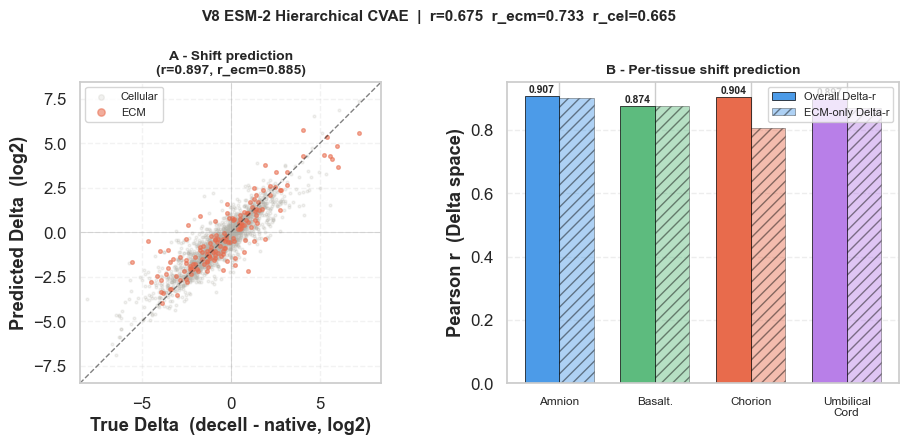

In [42]:
@dataclass
class V8Config:
    esm_dim:     int   = 320
    expr_dim:    int   = 12
    output_dim:  int   = 4
    cond_dim:    int   = 9
    latent_dim:  int   = 16
    hidden_dim:  int   = 256
    n_cat:       int   = 7
    lr:          float = 2e-4
    epochs:      int   = 80
    batch:       int   = 64
    max_beta:    float = 0.05
    kl_thresh:   float = 1.0
    decorr_w:    float = 5.0
    aux_w:       float = 0.05
    sigma_reg_w: float = 0.01
    kl_warmup:   int   = 50

CFG_V8 = V8Config()

CAT_MAP = {
    "none": 0, "Collagens": 1, "ECM Glycoproteins": 2, "Proteoglycans": 3,
    "ECM Regulators": 4, "ECM-affiliated Proteins": 5, "Secreted Factors": 6,
}

def assign_cat_idx(prot_df: pd.DataFrame) -> np.ndarray:
    def _cat(row):
        if not row["is_matrisome"]: return 0
        return CAT_MAP.get(str(row.get("MatrisomeCategory", "none")), 0)
    return prot_df.apply(_cat, axis=1).values.astype(np.int64)


class HierarchicalESMCVAE(BaseCVAE):
    """V8: branched ESM/expr encoder + class-conditional prior p(z|cat)=N(μ_cat,I)."""
    def __init__(self, cfg: V8Config = CFG_V8) -> None:
        super().__init__()
        self.cfg = cfg
        E, X, H, Z, Cc = (cfg.esm_dim, cfg.expr_dim, cfg.hidden_dim,
                           cfg.latent_dim, cfg.cond_dim)
        self.esm_branch  = nn.Sequential(
            nn.Linear(E, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.20),
            nn.Linear(128, 64), nn.GELU())
        self.expr_branch = nn.Sequential(
            nn.Linear(X, 64), nn.BatchNorm1d(64), nn.GELU())
        self.fusion = nn.Sequential(
            nn.Linear(64 + 64 + Cc, H), nn.LayerNorm(H), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(H, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H // 2), nn.GELU())
        self.fc_mu     = nn.Linear(H // 2, Z)
        self.fc_logvar = nn.Linear(H // 2, Z)
        self.prior_means = nn.Embedding(cfg.n_cat, Z)
        nn.init.normal_(self.prior_means.weight, mean=0.0, std=0.1)
        self.cond_drop = nn.Dropout(p=0.20)
        self.decoder = nn.Sequential(
            nn.Linear(Z + Cc, H // 2), nn.BatchNorm1d(H // 2), nn.GELU(),
            nn.Linear(H // 2, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H), nn.GELU())
        self.out_mu       = nn.Linear(H, cfg.output_dim)
        self.out_logsigma = nn.Linear(H, cfg.output_dim)

    def encode(self, x, c):
        esm  = self.esm_branch(x[:, :self.cfg.esm_dim])
        expr = self.expr_branch(x[:, self.cfg.esm_dim:])
        h    = self.fusion(torch.cat([esm, expr, c], -1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z, c):
        if self.training: c = self.cond_drop(c)
        h  = self.decoder(torch.cat([z, c], -1))
        return self.out_mu(h), torch.clamp(self.out_logsigma(h), min=-6.0, max=2.0)

    def forward(self, x, c, **_):
        mu_z, logvar_z = self.encode(x, c)
        mu_out, ls_out = self.decode(self.reparameterise(mu_z, logvar_z), c)
        return mu_out, ls_out, mu_z, logvar_z

    def compute_loss(self, x_nat, x_dec, c, beta,
                     tissue_deltas_batch=None, cat_idx_batch=None, **_):
        if cat_idx_batch is None:
            raise ValueError("V8 requires cat_idx_batch.")
        mu_out, ls_out, mu_z, logvar_z = self.forward(x_nat, c)
        recon     = self.nll_loss(mu_out, ls_out, x_dec)
        mu_cat    = self.prior_means(cat_idx_batch)
        kl_raw    = 0.5 * (logvar_z.exp() + (mu_z - mu_cat).pow(2)
                           - 1.0 - logvar_z).sum(dim=-1).mean()
        kl_fb     = torch.clamp(kl_raw - self.cfg.kl_thresh, min=0.0)
        decorr    = self.decorr_loss(mu_z)
        sigma_reg = torch.mean(torch.exp(-2.0 * ls_out))
        aux       = self.aux_delta_loss(mu_z, tissue_deltas_batch or [])
        total     = (recon + beta * kl_fb + self.cfg.decorr_w * decorr
                     + self.cfg.sigma_reg_w * sigma_reg + self.cfg.aux_w * aux)
        return total, {"recon": recon.item(), "kl": kl_raw.item(),
                       "decorr": decorr.item(), "aux": aux.item()}


# ── Build V8 bundle: V5 expression + scaled ESM (332D input) ──────────────────
import copy as _copy
esm_scaled = attach_esm_to_bundle(bundle_v5)                            # (N, 320)
bundle_v8  = _copy.copy(bundle_v5)
bundle_v8.X_nat = np.concatenate([esm_scaled, bundle_v5.X_nat],
                                  axis=1).astype(np.float32)            # (N, 332)
bundle_v8.extra = dict(bundle_v5.extra)
bundle_v8.extra["cat_idx_batch"] = assign_cat_idx(bundle_v5.prot_df)

# ── Train ──────────────────────────────────────────────────────────────────────
torch.manual_seed(CFG.seed)
model_v8 = HierarchicalESMCVAE(CFG_V8).to(device)
print(f"V8 params: {sum(p.numel() for p in model_v8.parameters() if p.requires_grad):,}")
Trainer(model=model_v8, lr=CFG_V8.lr, epochs=CFG_V8.epochs,
        batch=CFG_V8.batch, max_beta=CFG_V8.max_beta,
        kl_warmup=CFG_V8.kl_warmup, weight_decay=1e-5
        ).fit(bundle_v8, verbose=50,
              extra_keys=["cat_idx_batch"], long_keys=["cat_idx_batch"])
torch.save(model_v8.state_dict(), "ckpt_v8.pt")

# ── Evaluate ───────────────────────────────────────────────────────────────────
model_v8.eval()
val = bundle_v8.val_idx
with torch.no_grad():
    mu_out8, ls8, mu_z8, _ = model_v8(
        bundle_v8.to_float(bundle_v8.X_nat[val]),
        bundle_v8.to_float(bundle_v8.C[val]))
X_pred8_raw = bundle_v8.scaler_dec.inverse_transform(mu_out8.cpu().numpy())
X_dec_val8  = bundle_v8.scaler_dec.inverse_transform(bundle_v8.X_dec[val])
# Native means sit at columns 320:324 of bundle_v8.X_nat (scaler_nat fits those 4)
X_nat_means8 = bundle_v8.scaler_nat.inverse_transform(bundle_v8.X_nat[val, 320:324])
prot_val8    = bundle_v8.prot_df.iloc[val].reset_index(drop=True)
is_mat8      = prot_val8["is_matrisome"].values

metrics_v8 = EvaluationEngine.report(
    X_dec_val8, X_pred8_raw, X_nat_means8,
    prot_val8, label="V8 ESM-2 Hierarchical (val)")

# ── ESM ablation ───────────────────────────────────────────────────────────────
X_noesm = bundle_v8.X_nat[val].copy()
X_noesm[:, :320] = 0.0
with torch.no_grad():
    mu_noesm, _, _, _ = model_v8(bundle_v8.to_float(X_noesm),
                                  bundle_v8.to_float(bundle_v8.C[val]))
X_pred_noesm = bundle_v8.scaler_dec.inverse_transform(mu_noesm.cpu().numpy())

r_with,    _ = pearsonr(X_dec_val8.flatten(),          X_pred8_raw.flatten())
r_without, _ = pearsonr(X_dec_val8.flatten(),          X_pred_noesm.flatten())
r_ecm_w,   _ = pearsonr(X_dec_val8[is_mat8].flatten(), X_pred8_raw[is_mat8].flatten())
r_ecm_wo,  _ = pearsonr(X_dec_val8[is_mat8].flatten(), X_pred_noesm[is_mat8].flatten())
r_cel_w,   _ = pearsonr(X_dec_val8[~is_mat8].flatten(),X_pred8_raw[~is_mat8].flatten())
r_cel_wo,  _ = pearsonr(X_dec_val8[~is_mat8].flatten(),X_pred_noesm[~is_mat8].flatten())

print(f"ESM ablation — overall: {r_with:.3f} → {r_without:.3f} (Δ={r_with-r_without:+.3f})")
print(f"               ECM:     {r_ecm_w:.3f} → {r_ecm_wo:.3f} (Δ={r_ecm_w-r_ecm_wo:+.3f})")
print(f"               Cellular:{r_cel_w:.3f} → {r_cel_wo:.3f} (Δ={r_cel_w-r_cel_wo:+.3f})")
esm_delta_overall = r_with - r_without
esm_delta_ecm     = r_ecm_w - r_ecm_wo

# ── Uniform evaluation figure ──────────────────────────────────────────────────
plot_model_eval(
    "V8 ESM-2 Hierarchical CVAE",
    X_dec_val8, X_pred8_raw,
    bundle_v8.scaler_nat.inverse_transform(bundle_v8.X_nat[val, :4]),
    prot_val8,
    {"r_overall": r_with, "r_ecm": r_ecm_w, "r_cellular": r_cel_w},
    save="fig_v8_eval.png")

In [79]:
# ── V8 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V8", [])

print(f"{'='*56}")
print(f"  V8 CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    b5 = _cv_bundle_v5(provider, tr, val)
    b8 = _cv_bundle_v8(b5, esm_full)
    bundle = b8
    torch.manual_seed(SEED)
    m = HierarchicalESMCVAE(CFG_V8).to(device)
    Trainer(model=m, lr=CFG_V8.lr, epochs=CFG_V8.epochs,
            batch=CFG_V8.batch, max_beta=CFG_V8.max_beta,
            kl_warmup=CFG_V8.kl_warmup, weight_decay=1e-5,
            ).fit(bundle, verbose=VERBOSE,
                      extra_keys=["cat_idx_batch"],
                      long_keys=["cat_idx_batch"])
    res = _cv_evaluate(m, bundle)
    cv_results["V8"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r_overall"] for r in cv_results["V8"]])
print(f"\n  V8  r_overall = {_v.mean():.3f} ± {_v.std():.3f}")


  V8 CV  (5-fold  seed=42)
  Done. Best val loss: 0.33052
  fold 1/5  r=0.588  ecm=0.544  t=1.1m
  Done. Best val loss: 0.32645
  fold 2/5  r=0.634  ecm=0.722  t=1.2m
  Done. Best val loss: 0.25516
  fold 3/5  r=0.630  ecm=0.716  t=1.1m
  Done. Best val loss: 0.29209
  fold 4/5  r=0.628  ecm=0.691  t=1.3m
  Done. Best val loss: 0.26204
  fold 5/5  r=0.649  ecm=0.759  t=1.4m

  V8  r_overall = 0.611 ± 0.024


### V8e — Hierarchical prior CVAE, expression-only

Direct no-ESM counterpart to V8. The ESM branch is removed entirely and the input is 12D. Same hierarchical prior, same H=256 decoder. Isolates whether the ESM branch contributes anything at all.

### The results
The model similar to the V8 with ESM. The V8 model with ESM is overfitting which will address in the grid search, with different regularization and architectural adjustments.

**5-fold CV:** r = 0.609 ± 0.017

In [45]:
# ── ExprConfig — shared by V8e / V10e / V11e ──────────────────────────────────
# Defined here once; V10e and V11e sections reference it directly.
from dataclasses import dataclass

@dataclass
class ExprConfig:
    input_dim:   int   = 12
    output_dim:  int   = 4
    cond_dim:    int   = 9
    latent_dim:  int   = 16
    hidden_dim:  int   = 256
    n_cat:       int   = 7
    flow_blocks: int   = 3
    lr:          float = 2e-4
    epochs:      int   = 200
    batch:       int   = 64
    max_beta:    float = 0.05
    kl_thresh:   float = 1.0
    kl_warmup:   int   = 80
    decorr_w:    float = 5.0
    aux_w:       float = 0.05
    sigma_reg_w: float = 0.01
    free_bits:   float = 0.05
    detect_w:    float = 0.25
    abund_w:     float = 4.0

CFG_EXPR = ExprConfig()

# ── V8e: Hierarchical prior CVAE, expression-only (12D input, no ESM branch) ──
import torch.nn as nn

class HierarchicalExprCVAE(BaseCVAE):
    """V8 architecture without ESM. Input is 12D expression features only.
    Same hierarchical prior, same fusion/decoder width as V8."""

    def __init__(self, cfg: ExprConfig = CFG_EXPR) -> None:
        super().__init__()
        self.cfg = cfg
        D, H, Z, Cc = cfg.input_dim, cfg.hidden_dim, cfg.latent_dim, cfg.cond_dim

        self.expr_proj = nn.Sequential(
            nn.Linear(D, 64), nn.BatchNorm1d(64), nn.GELU())
        self.fusion = nn.Sequential(
            nn.Linear(64 + Cc, H), nn.LayerNorm(H), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(H, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H // 2), nn.GELU())
        self.fc_mu     = nn.Linear(H // 2, Z)
        self.fc_logvar = nn.Linear(H // 2, Z)
        self.prior_means = nn.Embedding(cfg.n_cat, Z)
        nn.init.normal_(self.prior_means.weight, mean=0.0, std=0.1)
        self.cond_drop = nn.Dropout(p=0.20)
        self.decoder = nn.Sequential(
            nn.Linear(Z + Cc, H // 2), nn.BatchNorm1d(H // 2), nn.GELU(),
            nn.Linear(H // 2, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H), nn.GELU())
        self.out_mu       = nn.Linear(H, cfg.output_dim)
        self.out_logsigma = nn.Linear(H, cfg.output_dim)

    def encode(self, x, c):
        e = self.expr_proj(x)
        h = self.fusion(torch.cat([e, c], dim=-1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z, c):
        if self.training: c = self.cond_drop(c)
        h = self.decoder(torch.cat([z, c], dim=-1))
        return self.out_mu(h), torch.clamp(self.out_logsigma(h), min=-6.0, max=2.0)

    def forward(self, x, c, **_):
        mu_z, logvar_z = self.encode(x, c)
        mu_out, ls_out = self.decode(self.reparameterise(mu_z, logvar_z), c)
        return mu_out, ls_out, mu_z, logvar_z

    def compute_loss(self, x_nat, x_dec, c, beta,
                     tissue_deltas_batch=None, cat_idx_batch=None, **_):
        if cat_idx_batch is None:
            raise ValueError("V8e requires cat_idx_batch.")
        mu_out, ls_out, mu_z, logvar_z = self.forward(x_nat, c)
        recon     = self.nll_loss(mu_out, ls_out, x_dec)
        mu_cat    = self.prior_means(cat_idx_batch)
        kl_raw    = 0.5 * (logvar_z.exp() + (mu_z - mu_cat).pow(2)
                           - 1.0 - logvar_z).sum(dim=-1).mean()
        kl_fb     = torch.clamp(kl_raw - self.cfg.kl_thresh, min=0.0)
        decorr    = self.decorr_loss(mu_z)
        sigma_reg = torch.mean(torch.exp(-2.0 * ls_out))
        aux       = self.aux_delta_loss(mu_z, tissue_deltas_batch or [])
        total     = (recon + beta * kl_fb + self.cfg.decorr_w * decorr
                     + self.cfg.sigma_reg_w * sigma_reg + self.cfg.aux_w * aux)
        return total, {"recon": recon.item(), "kl": kl_raw.item(), "aux": aux.item()}

n_v8e = sum(p.numel() for p in HierarchicalExprCVAE().parameters())
print(f"HierarchicalExprCVAE  params={n_v8e:,}  ratio={n_v8e/len(provider.proteins_keep):.0f}:1")

HierarchicalExprCVAE  params=227,800  ratio=42:1


V8e params: 227,800
  ep    1/200 | tr 0.5396 | val 0.5045 | β=0.0006
  ep   50/200 | tr 0.2693 | val 0.2950 | β=0.0312
  ep  100/200 | tr 0.2572 | val 0.3521 | β=0.0500
  ep  150/200 | tr 0.2465 | val 0.3701 | β=0.0500
  ep  200/200 | tr 0.2466 | val 0.3669 | β=0.0500
  Done. Best val loss: 0.23381


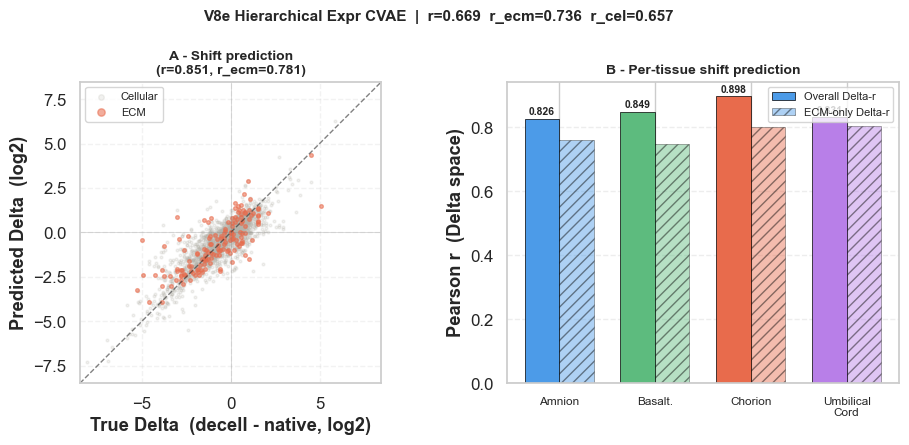

In [46]:
# ── V8e: single-split holdout train + eval ────────────────────────────────────
import torch

torch.manual_seed(CFG.seed)
model_v8e = HierarchicalExprCVAE(CFG_EXPR).to(device)
print(f"V8e params: {sum(p.numel() for p in model_v8e.parameters()):,}")

Trainer(model=model_v8e, lr=CFG_EXPR.lr, epochs=CFG_EXPR.epochs,
        batch=CFG_EXPR.batch, max_beta=CFG_EXPR.max_beta,
        kl_warmup=CFG_EXPR.kl_warmup, weight_decay=1e-5
        ).fit(bundle_v5, verbose=50,
              extra_keys=["cat_idx_batch"], long_keys=["cat_idx_batch"])
torch.save(model_v8e.state_dict(), "ckpt_v8e.pt")

# ── Evaluate ──────────────────────────────────────────────────────────────────
model_v8e.eval()
val = bundle_v5.val_idx
with torch.no_grad():
    mu_out_v8e, ls_v8e, mu_z_v8e, _ = model_v8e(
        bundle_v5.to_float(bundle_v5.X_nat[val]),
        bundle_v5.to_float(bundle_v5.C[val]))

X_pred_v8e_raw = bundle_v5.scaler_dec.inverse_transform(mu_out_v8e.cpu().numpy())
X_dec_val_v8e  = bundle_v5.scaler_dec.inverse_transform(bundle_v5.X_dec[val])
X_nat_val_v8e  = bundle_v5.scaler_nat.inverse_transform(bundle_v5.X_nat[val, :4])
prot_val_v8e   = bundle_v5.prot_df.iloc[val].reset_index(drop=True)

metrics_v8e = EvaluationEngine.report(
    X_dec_val_v8e, X_pred_v8e_raw, X_nat_val_v8e,
    prot_val_v8e, label="V8e Hierarchical Expr CVAE (val)")

plot_model_eval(
    "V8e Hierarchical Expr CVAE",
    X_dec_val_v8e, X_pred_v8e_raw, X_nat_val_v8e,
    prot_val_v8e, metrics_v8e,
    save="fig_v8e_eval.png")

In [80]:
# ── V8e 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V8e", [])

print(f"{'='*56}")
print(f"  V8e CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    be = _cv_bundle_expr(provider, tr, val)
    bundle = be
    torch.manual_seed(SEED)
    m = HierarchicalExprCVAE(CFG_EXPR).to(device)
    Trainer(model=m, lr=CFG_EXPR.lr, epochs=CFG_EXPR.epochs,
            batch=CFG_EXPR.batch, max_beta=CFG_EXPR.max_beta,
            kl_warmup=CFG_EXPR.kl_warmup, weight_decay=1e-5,
            ).fit(bundle, verbose=VERBOSE,
                      extra_keys=["cat_idx_batch"],
                      long_keys=["cat_idx_batch"])
    res = _cv_evaluate(m, bundle)
    cv_results["V8e"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r_overall"] for r in cv_results["V8e"]])
print(f"\n  V8e  r_overall = {_v.mean():.3f} ± {_v.std():.3f}")


  V8e CV  (5-fold  seed=42)
  Done. Best val loss: 0.32804
  fold 1/5  r=0.602  ecm=0.539  t=2.6m
  Done. Best val loss: 0.30695
  fold 2/5  r=0.629  ecm=0.690  t=2.8m
  Done. Best val loss: 0.26559
  fold 3/5  r=0.617  ecm=0.708  t=2.6m
  Done. Best val loss: 0.29168
  fold 4/5  r=0.613  ecm=0.720  t=2.7m
  Done. Best val loss: 0.25224
  fold 5/5  r=0.639  ecm=0.753  t=2.7m

  V8e  r_overall = 0.609 ± 0.017


---
## 9 — V9: ECM-Only Specialist  *(negative result)*

The hypothesis: removing all cellular proteins and focusing exclusively on ECM proteins
with stronger per-category priors should improve ECM prediction.

### What changes from V8

Training filters to ECM proteins only (n ≈ 370, 20% validation for stability on the
small subset). The architecture is deliberately smaller and more regularised:
`hidden=64, latent=8D`, ESM projected to 32D via a high-dropout branch (Dropout 0.40
then 0.20), encoder Dropout 0.50, `decorr_w=8.0`, `kl_thresh=0.10`. The ECM category
map has 6 entries (cellular absent). Everything else the ESM input, hierarchical prior,
twin output heads is identical to V8.

### The result

V9 ECM r = 0.487 ± 0.033 vs V8 ECM r = 0.686 ± 0.074. The specialist loses by
approximately 0.20 r despite more targeted priors, heavier regularisation, and a
training set with no cellular noise. The train/val loss gap reflects the small
validation set (74 proteins).

### The biological reading

Cellular proteins carry information about the decellularization environment that ECM
sequences alone cannot provide. The efficiency of cellular removal depends on cell type,
density, membrane fragility etc. This is all reflected in the
cellular proteome. A generalist model that reads the cellular context can infer how
harsh the decell protocol was, and therefore how much ECM was retained. V9 is blind to
this context. The finding is biological, not architectural: ECM proteins do not
self-predict.

**5-fold CV:** ECM r = 0.487 ± 0.033

ECM bundle: 370 proteins | train 296 | val 74
  ep    1/200 | tr 1.0890 | val 1.8715 | β=0.0005
  ep   50/200 | tr 1.0568 | val 1.8172 | β=0.0250
  ep  100/200 | tr 0.8835 | val 1.6885 | β=0.0400
  ep  150/200 | tr 0.9108 | val 1.6471 | β=0.0400
  ep  200/200 | tr 0.8542 | val 1.6175 | β=0.0400
  Done. Best val loss: 1.54367
V9 ECM-only val r = 0.501
  Amnion           r=0.404
  Basaltissue      r=0.395
  Chorion          r=0.497
  UmbilicalCord    r=0.622

Specialist V9 ECM r = 0.501  vs  Generalist V8 ECM r = 0.733  (Δ=-0.232)
→ Cellular context is necessary for ECM prediction.


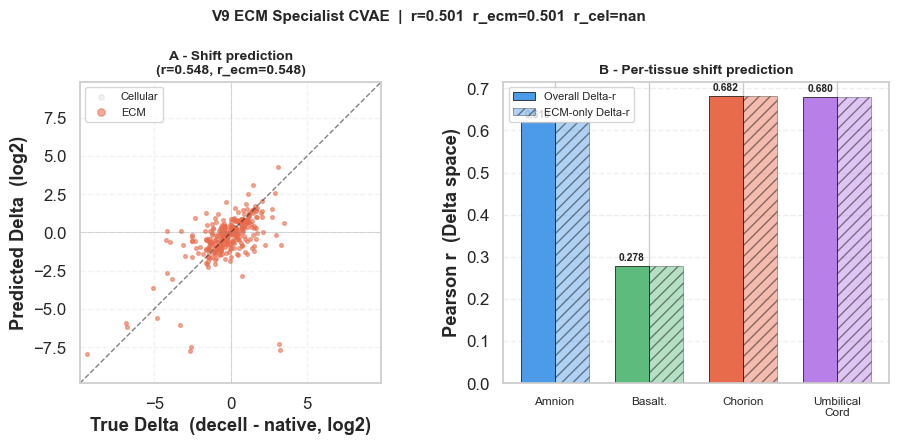

In [48]:
@dataclass
class V9Config:
    esm_dim:     int   = 320
    esm_proj:    int   = 32
    expr_dim:    int   = 12
    output_dim:  int   = 4
    cond_dim:    int   = 9
    latent_dim:  int   = 8
    hidden_dim:  int   = 64
    n_cat:       int   = 6
    lr:          float = 2e-4
    epochs:      int   = 200
    batch:       int   = 32
    max_beta:    float = 0.04
    kl_thresh:   float = 0.10
    decorr_w:    float = 8.0
    aux_w:       float = 0.10
    sigma_reg_w: float = 0.01
    kl_warmup:   int   = 80

CFG_V9 = V9Config()

ECM_CAT_MAP = {
    "Collagens": 0, "ECM Glycoproteins": 1, "Proteoglycans": 2,
    "ECM Regulators": 3, "ECM-affiliated Proteins": 4, "Secreted Factors": 5,
}


def build_ecm_bundle(src_bundle) -> "DataBundle":
    """ECM-only DataBundle from bundle_v8. Uses 20% val (≥70 proteins)
    for a stable loss signal given the small ECM subset (370 proteins)."""
    is_mat = src_bundle.prot_df["is_matrisome"].values.astype(bool)
    sub    = np.where(is_mat)[0]
    prot   = src_bundle.prot_df.iloc[sub].reset_index(drop=True)

    # 20% val — more stable than 10% on 370 proteins
    rng   = np.random.default_rng(CFG.seed)
    n_val = max(70, int(len(sub) * 0.20))
    val_l = sorted(rng.choice(len(sub), n_val, replace=False).tolist())
    tr_l  = [i for i in range(len(sub)) if i not in set(val_l)]
    tr    = np.array(tr_l,  dtype=np.int64)
    vl    = np.array(val_l, dtype=np.int64)

    esm     = src_bundle.X_nat[sub, :320]
    expr12  = src_bundle.X_nat[sub, 320:332].copy()
    sc_expr = StandardScaler().fit(expr12[tr])               # fit on train only
    expr_re = sc_expr.transform(expr12).astype(np.float32)

    dec_cols  = [f"{t}_decell" for t in TISS]
    X_dec_raw = prot[dec_cols].values.astype(np.float32)
    sc_dec    = StandardScaler().fit(X_dec_raw[tr])          # fit on train only

    X_nat = np.concatenate([esm, expr_re], axis=1).astype(np.float32)
    C     = src_bundle.C[sub]
    td    = [d[sub] for d in src_bundle.tissue_deltas]
    cat   = prot.apply(
        lambda r: ECM_CAT_MAP.get(str(r.get("MatrisomeCategory", "")), 0),
        axis=1).values.astype(np.int64)

    print(f"ECM bundle: {len(prot)} proteins | train {len(tr)} | val {len(vl)}")
    return DataBundle(
        X_nat=X_nat, X_dec=sc_dec.transform(X_dec_raw).astype(np.float32),
        C=C, prot_df=prot, scaler_nat=sc_expr, scaler_dec=sc_dec,
        tr_idx=tr, val_idx=vl, tissue_deltas=td,
        extra={"cat_idx_batch": cat})


class ECMSpecialistCVAE(BaseCVAE):
    """V9: small hierarchical CVAE trained on ECM proteins only.
    Tests whether specialist focus beats V8's generalist context for ECM."""
    def __init__(self, cfg: V9Config = CFG_V9) -> None:
        super().__init__()
        self.cfg = cfg
        E, P, X, H, Z, Cc = (cfg.esm_dim, cfg.esm_proj, cfg.expr_dim,
                              cfg.hidden_dim, cfg.latent_dim, cfg.cond_dim)
        self.esm_proj = nn.Sequential(
            nn.Linear(E, 64), nn.LayerNorm(64), nn.GELU(), nn.Dropout(0.40),
            nn.Linear(64, P), nn.GELU(), nn.Dropout(0.20))
        self.encoder = nn.Sequential(
            nn.Linear(P + X + Cc, H), nn.BatchNorm1d(H), nn.GELU(), nn.Dropout(0.50),
            nn.Linear(H, H), nn.GELU(), nn.Dropout(0.30),
            nn.Linear(H, H // 2), nn.GELU())
        self.fc_mu     = nn.Linear(H // 2, Z)
        self.fc_logvar = nn.Linear(H // 2, Z)
        self.prior_means = nn.Embedding(cfg.n_cat, Z)
        nn.init.normal_(self.prior_means.weight, mean=0.0, std=0.2)
        self.cond_drop = nn.Dropout(p=0.30)
        self.decoder = nn.Sequential(
            nn.Linear(Z + Cc, H // 2), nn.BatchNorm1d(H // 2), nn.GELU(),
            nn.Linear(H // 2, H), nn.GELU(), nn.Dropout(0.20),
            nn.Linear(H, H), nn.GELU())
        self.out_mu       = nn.Linear(H, cfg.output_dim)
        self.out_logsigma = nn.Linear(H, cfg.output_dim)

    def encode(self, x, c):
        esm  = self.esm_proj(x[:, :self.cfg.esm_dim])
        expr = x[:, self.cfg.esm_dim:]
        h    = self.encoder(torch.cat([esm, expr, c], -1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z, c):
        if self.training: c = self.cond_drop(c)
        h = self.decoder(torch.cat([z, c], -1))
        return self.out_mu(h), torch.clamp(self.out_logsigma(h), min=-4.0, max=1.0)

    def forward(self, x, c, **_):
        mu_z, logvar_z = self.encode(x, c)
        mu_out, ls_out = self.decode(self.reparameterise(mu_z, logvar_z), c)
        return mu_out, ls_out, mu_z, logvar_z

    def compute_loss(self, x_nat, x_dec, c, beta,
                    tissue_deltas_batch=None, cat_idx_batch=None, **_):
        if cat_idx_batch is None:
            raise ValueError("V9 requires cat_idx_batch.")
        mu_out, ls_out, mu_z, logvar_z = self.forward(x_nat, c)
        recon  = F.mse_loss(mu_out, x_dec)           # MSE — more stable than NLL on n=296
        mu_cat = self.prior_means(cat_idx_batch)
        kl_raw = 0.5 * (logvar_z.exp() + (mu_z - mu_cat).pow(2)
                        - 1.0 - logvar_z).sum(dim=-1).mean()
        total  = (recon
                + beta * torch.clamp(kl_raw - self.cfg.kl_thresh, min=0.0)
                + self.cfg.decorr_w   * self.decorr_loss(mu_z)
                + self.cfg.aux_w      * self.aux_delta_loss(mu_z, tissue_deltas_batch or []))
        return total, {"recon": recon.item(), "kl": kl_raw.item()}


# ── Build bundle & train ───────────────────────────────────────────────────────
bundle_v9 = build_ecm_bundle(bundle_v8)

torch.manual_seed(CFG.seed)
model_v9 = ECMSpecialistCVAE(CFG_V9).to(device)
Trainer(model=model_v9, lr=CFG_V9.lr, epochs=CFG_V9.epochs,
        batch=CFG_V9.batch, max_beta=CFG_V9.max_beta,
        kl_warmup=CFG_V9.kl_warmup, weight_decay=1e-5
        ).fit(bundle_v9, verbose=50,
              extra_keys=["cat_idx_batch"], long_keys=["cat_idx_batch"])
torch.save(model_v9.state_dict(), "ckpt_v9.pt")

# ── Evaluate ───────────────────────────────────────────────────────────────────
model_v9.eval()
val9 = bundle_v9.val_idx
with torch.no_grad():
    mu9, ls9, _, _ = model_v9(bundle_v9.to_float(bundle_v9.X_nat[val9]),
                               bundle_v9.to_float(bundle_v9.C[val9]))
X_pred9   = bundle_v9.scaler_dec.inverse_transform(mu9.cpu().numpy())
X_dec_v9  = bundle_v9.scaler_dec.inverse_transform(bundle_v9.X_dec[val9])
prot_val9 = bundle_v9.prot_df.iloc[val9].reset_index(drop=True)

r9_all, _ = pearsonr(X_dec_v9.flatten(), X_pred9.flatten())
print(f"V9 ECM-only val r = {r9_all:.3f}")
for i, t in enumerate(TISS):
    r, _ = pearsonr(X_dec_v9[:, i], X_pred9[:, i])
    print(f"  {t:<16} r={r:.3f}")

# ── Key finding ────────────────────────────────────────────────────────────────
delta = r9_all - r_ecm_w
print(f"\nSpecialist V9 ECM r = {r9_all:.3f}  vs  Generalist V8 ECM r = {r_ecm_w:.3f}  "
      f"(Δ={delta:+.3f})")
print("→ Cellular context is necessary for ECM prediction." if r9_all < r_ecm_w else
      "→ Specialist focus helps — ECM proteins are self-contained.")

# ── Uniform evaluation figure ──────────────────────────────────────────────────
plot_model_eval(
    "V9 ECM Specialist CVAE",
    X_dec_v9, X_pred9,
    bundle_v9.scaler_nat.inverse_transform(bundle_v9.X_nat[val9, 320:332])[:, :4],
    prot_val9,
    {"r_overall": r9_all, "r_ecm": r9_all, "r_cellular": float("nan")},
    save="fig_v9_eval.png")

In [49]:
# ── V9 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V9", [])

print(f"{'='*56}")
print(f"  V9 CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    b5 = _cv_bundle_v5(provider, tr, val)
    b8 = _cv_bundle_v8(b5, esm_full)
    bundle = _cv_bundle_v9(b8)
    torch.manual_seed(SEED)
    m = ECMSpecialistCVAE(CFG_V9).to(device)
    Trainer(model=m, lr=CFG_V9.lr, epochs=CFG_V9.epochs,
            batch=CFG_V9.batch, max_beta=CFG_V9.max_beta,
            kl_warmup=CFG_V9.kl_warmup, weight_decay=1e-5
            ).fit(bundle, verbose=VERBOSE,
                  extra_keys=["cat_idx_batch"],
                  long_keys=["cat_idx_batch"])
    res = _cv_evaluate(m, bundle, ecm_only=True)
    cv_results["V9"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r_overall"] for r in cv_results["V9"]])
print(f"\n  V9  r_overall = {_v.mean():.3f} ± {_v.std():.3f}")


  V9 CV  (5-fold  seed=42)
  Done. Best val loss: 1.51119
  fold 1/5  r=0.429  ecm=0.429  t=0.3m
  Done. Best val loss: 0.89752
  fold 2/5  r=0.511  ecm=0.511  t=0.3m
  Done. Best val loss: 0.77784
  fold 3/5  r=0.487  ecm=0.487  t=0.3m
  Done. Best val loss: 0.72807
  fold 4/5  r=0.480  ecm=0.480  t=0.3m
  Done. Best val loss: 0.83709
  fold 5/5  r=0.526  ecm=0.526  t=0.3m

  V9  r_overall = 0.487 ± 0.033


---
## 10 — V10: Flow + ESM CVAE

V10 combines V8's branched ESM encoder and hierarchical prior with V6's RealNVP flows.
The KL correction accounts for both the prior centroid shift and the flow log-determinant.

### What's new relative to V8

Three `V6FlowBlock` modules (identical architecture to V6, hidden=64 per block) are
inserted between the reparameterization step and the decoder. Log-determinants are
accumulated across blocks and the KL adjusted:

    KL_adj = clamp(KL_raw − KL_thresh, min=0) − clamp(log_det.mean(), max=5.0)

Clamping `log_det` prevents gradient explosion early in training when the flows are
poorly conditioned. The decoder is identical to V8: the final z passes through
`Linear(16+9→128) → BatchNorm → GELU → Linear(128→256) → GELU → Dropout →
Linear(256→256) → GELU` before the twin output heads.

### The result

V10 r = 0.637 ± 0.009 vs V6 r = 0.638 ± 0.014. Three expensive additions (ESM
embeddings, a 293K-parameter encoder, a categorical prior) produce zero improvement
over V6's 12D-input flow model. The gain of V10 over V8 (0.637 vs 0.626) comes entirely
from the flows, consistent with V6's original finding. ESM adds nothing.

The expression-only reimplementation **V10e** reaches r = 0.645 without ESM, at
65K fewer parameters, making it the actual best abundance model in this project.

**5-fold CV:** r = 0.637 ± 0.009 · lift = +0.655 · r_ecm = 0.693 ± 0.053

V10 params: 328,776
  ep    1/100 | tr 0.5389 | val 0.4927 | β=0.0006
  ep   50/100 | tr 0.0655 | val 0.4122 | β=0.0312
  ep  100/100 | tr 0.0403 | val 0.4837 | β=0.0500
  Done. Best val loss: 0.18044
log|det J|: mean=0.282  std=0.127  min=-0.399  max=0.749


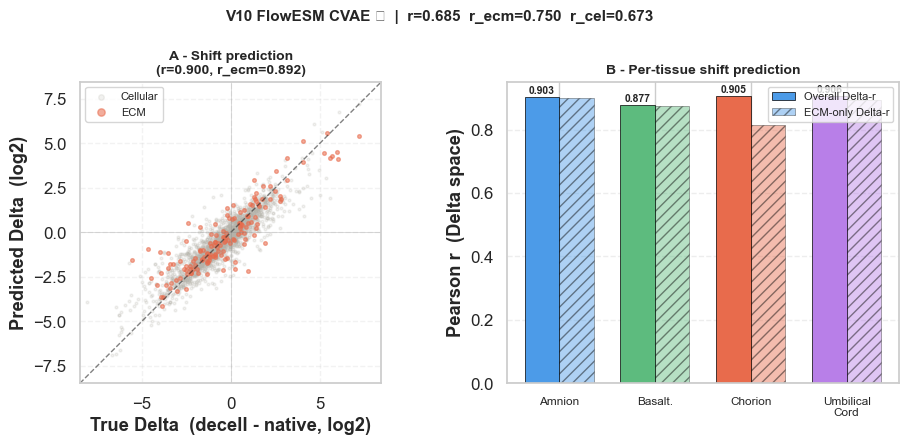

In [50]:
@dataclass
class V10Config:
    esm_dim:     int   = 320
    expr_dim:    int   = 12
    output_dim:  int   = 4
    cond_dim:    int   = 9
    latent_dim:  int   = 16
    hidden_dim:  int   = 256
    n_cat:       int   = 7
    flow_blocks: int   = 3
    lr:          float = 2e-4
    epochs:      int   = 100
    batch:       int   = 64
    kl_warmup:   int   = 80
    max_beta:    float = 0.05
    kl_thresh:   float = 1.0
    decorr_w:    float = 5.0
    aux_w:       float = 0.05
    sigma_reg_w: float = 0.01

CFG_V10 = V10Config()


class FlowESMCVAE(BaseCVAE):
    """V10: V8 branched ESM encoder + V6 RealNVP flows + V8 hierarchical prior.
    KL is adjusted for both the class-conditional prior shift and the flow
    log-determinant — the two corrections are additive in log-space."""

    def __init__(self, cfg: V10Config = CFG_V10) -> None:
        super().__init__()
        self.cfg = cfg
        E, X, H, Z, Cc = (cfg.esm_dim, cfg.expr_dim, cfg.hidden_dim,
                           cfg.latent_dim, cfg.cond_dim)
        self.esm_branch = nn.Sequential(
            nn.Linear(E, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.20),
            nn.Linear(128, 64), nn.GELU())
        self.expr_branch = nn.Sequential(
            nn.Linear(X, 64), nn.BatchNorm1d(64), nn.GELU())
        self.fusion = nn.Sequential(
            nn.Linear(64 + 64 + Cc, H), nn.LayerNorm(H), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(H, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H // 2), nn.GELU())
        self.fc_mu     = nn.Linear(H // 2, Z)
        self.fc_logvar = nn.Linear(H // 2, Z)
        self.flows     = nn.ModuleList([
            V6FlowBlock(Z, Cc, H // 4) for _ in range(cfg.flow_blocks)])
        self.prior_means = nn.Embedding(cfg.n_cat, Z)
        nn.init.normal_(self.prior_means.weight, mean=0.0, std=0.1)
        self.cond_drop = nn.Dropout(p=0.20)
        self.decoder = nn.Sequential(
            nn.Linear(Z + Cc, H // 2), nn.BatchNorm1d(H // 2), nn.GELU(),
            nn.Linear(H // 2, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H), nn.GELU())
        self.out_mu       = nn.Linear(H, cfg.output_dim)
        self.out_logsigma = nn.Linear(H, cfg.output_dim)

    def encode(self, x, c):
        esm  = self.esm_branch(x[:, :self.cfg.esm_dim])
        expr = self.expr_branch(x[:, self.cfg.esm_dim:])
        h    = self.fusion(torch.cat([esm, expr, c], dim=-1))
        return self.fc_mu(h), self.fc_logvar(h)

    def flow_forward(self, z0, c):
        z, log_det = z0, torch.zeros(z0.shape[0], device=z0.device)
        for flow in self.flows:
            z, ld  = flow(z, c)
            log_det += ld
            z       = torch.flip(z, dims=[-1])
        return z, log_det

    def decode(self, z, c):
        if self.training: c = self.cond_drop(c)
        h  = self.decoder(torch.cat([z, c], dim=-1))
        return self.out_mu(h), torch.clamp(self.out_logsigma(h), min=-6.0, max=2.0)

    def forward(self, x, c, **_):
        mu_z, logvar_z   = self.encode(x, c)
        z, total_log_det = self.flow_forward(self.reparameterise(mu_z, logvar_z), c)
        mu_out, ls_out   = self.decode(z, c)
        return mu_out, ls_out, mu_z, logvar_z, total_log_det

    def compute_loss(self, x_nat, x_dec, c, beta,
                     tissue_deltas_batch=None, cat_idx_batch=None, **_):
        if cat_idx_batch is None:
            raise ValueError("V10 requires cat_idx_batch.")
        mu_out, ls_out, mu_z, logvar_z, log_det = self.forward(x_nat, c)
        mu_cat    = self.prior_means(cat_idx_batch)
        kl_raw    = 0.5 * (logvar_z.exp() + (mu_z - mu_cat).pow(2)
                           - 1.0 - logvar_z).sum(dim=-1).mean()
        # Subtract flow log-det: flows expand mass → reduces effective KL
        kl_adj = torch.clamp(
            kl_raw - torch.clamp(log_det.mean(), max=2.0) - self.cfg.kl_thresh,
            min=0.0)
        decorr    = self.decorr_loss(mu_z)
        sigma_reg = torch.mean(torch.exp(-2.0 * ls_out))
        aux       = self.aux_delta_loss(mu_z, tissue_deltas_batch or [])
        flow_reg = 0.01 * log_det.pow(2).mean()
        total = (self.nll_loss(mu_out, ls_out, x_dec)
            + beta * kl_adj
            + self.cfg.decorr_w    * decorr
            + self.cfg.sigma_reg_w * sigma_reg
            + self.cfg.aux_w       * aux
            + flow_reg) 
        return total, {"kl_raw": kl_raw.item(), "kl_adj": kl_adj.item(),
                       "log_det": log_det.mean().item(), "decorr": decorr.item()}


# ── Reuse bundle_v8 — same 332D input, same cat_idx ───────────────────────────
bundle_v10 = bundle_v8

torch.manual_seed(CFG.seed)
model_v10 = FlowESMCVAE(CFG_V10).to(device)
print(f"V10 params: {sum(p.numel() for p in model_v10.parameters() if p.requires_grad):,}")
Trainer(model=model_v10, lr=CFG_V10.lr, epochs=CFG_V10.epochs,
        batch=CFG_V10.batch, max_beta=CFG_V10.max_beta,
        kl_warmup=CFG_V10.kl_warmup, weight_decay=1e-5
        ).fit(bundle_v10, verbose=50,
              extra_keys=["cat_idx_batch"], long_keys=["cat_idx_batch"])
torch.save(model_v10.state_dict(), "ckpt_v10.pt")

# ── Evaluate ───────────────────────────────────────────────────────────────────
model_v10.eval()
val = bundle_v10.val_idx
with torch.no_grad():
    mu_out10, ls10, mu_z10, _, log_det10 = model_v10(
        bundle_v10.to_float(bundle_v10.X_nat[val]),
        bundle_v10.to_float(bundle_v10.C[val]))

X_pred10_raw = bundle_v10.scaler_dec.inverse_transform(mu_out10.cpu().numpy())
X_dec_val10  = bundle_v10.scaler_dec.inverse_transform(bundle_v10.X_dec[val])
X_nat_val10  = bundle_v10.scaler_nat.inverse_transform(bundle_v10.X_nat[val, 320:324])
prot_val10   = bundle_v10.prot_df.iloc[val].reset_index(drop=True)
is_mat10     = prot_val10["is_matrisome"].values

r_all, _ = pearsonr(X_dec_val10.flatten(),           X_pred10_raw.flatten())
r_ecm, _ = pearsonr(X_dec_val10[is_mat10].flatten(), X_pred10_raw[is_mat10].flatten())
r_cel, _ = pearsonr(X_dec_val10[~is_mat10].flatten(),X_pred10_raw[~is_mat10].flatten())

# Flow log-det diagnostic: non-zero std confirms flows are actively warping
ld = log_det10.cpu().numpy()
print(f"log|det J|: mean={ld.mean():.3f}  std={ld.std():.3f}  "
      f"min={ld.min():.3f}  max={ld.max():.3f}")

metrics_v10 = EvaluationEngine.report(
    X_dec_val10, X_pred10_raw, X_nat_val10,
    prot_val10, label="V10 FlowESM CVAE (val)")

# ── Uniform evaluation figure ──────────────────────────────────────────────────
plot_model_eval(
    "V10 FlowESM CVAE \u2605",
    X_dec_val10, X_pred10_raw,
    bundle_v10.scaler_nat.inverse_transform(bundle_v10.X_nat[val, :4]),
    prot_val10, metrics_v10,
    save="fig_v10_eval.png")

In [51]:
# ── V10 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V10", [])

print(f"{'='*56}")
print(f"  V10 CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    b5 = _cv_bundle_v5(provider, tr, val)
    b8 = _cv_bundle_v8(b5, esm_full)
    bundle = b8
    torch.manual_seed(SEED)
    m = FlowESMCVAE(CFG_V10).to(device)
    Trainer(model=m, lr=CFG_V10.lr, epochs=CFG_V10.epochs,
            batch=CFG_V10.batch, max_beta=CFG_V10.max_beta,
            kl_warmup=CFG_V10.kl_warmup, weight_decay=1e-5,
            ).fit(bundle, verbose=VERBOSE,
                      extra_keys=["cat_idx_batch"],
                      long_keys=["cat_idx_batch"])
    res = _cv_evaluate(m, bundle)
    cv_results["V10"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r_overall"] for r in cv_results["V10"]])
print(f"\n  V10  r_overall = {_v.mean():.3f} ± {_v.std():.3f}")


  V10 CV  (5-fold  seed=42)
  Done. Best val loss: 0.29325
  fold 1/5  r=0.626  ecm=0.592  t=2.2m
  Done. Best val loss: 0.28294
  fold 2/5  r=0.650  ecm=0.704  t=2.2m
  Done. Best val loss: 0.21848
  fold 3/5  r=0.644  ecm=0.745  t=2.2m
  Done. Best val loss: 0.27359
  fold 4/5  r=0.634  ecm=0.712  t=2.7m
  Done. Best val loss: 0.25629
  fold 5/5  r=0.629  ecm=0.712  t=2.5m

  V10  r_overall = 0.637 ± 0.009


### V10e — Flow CVAE, expression-only  *(best abundance model)*

Direct no-ESM counterpart to V10. Keeps flows and hierarchical prior at H=256, removes ESM branch. Best Pearson-r in the project.

**5-fold CV:** 0.647 ± 0.014

In [52]:
# ── V10e: Flow CVAE, expression-only (12D input, no ESM branch) ───────────────
# V6FlowBlock must be defined (V6 section). CFG_EXPR from V8e section.

class FlowExprCVAE(BaseCVAE):
    """V10 architecture without ESM. Flows + hierarchical prior, 12D input."""

    def __init__(self, cfg: ExprConfig = CFG_EXPR) -> None:
        super().__init__()
        self.cfg = cfg
        D, H, Z, Cc = cfg.input_dim, cfg.hidden_dim, cfg.latent_dim, cfg.cond_dim

        self.expr_proj = nn.Sequential(
            nn.Linear(D, 64), nn.BatchNorm1d(64), nn.GELU())
        self.fusion = nn.Sequential(
            nn.Linear(64 + Cc, H), nn.LayerNorm(H), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(H, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H // 2), nn.GELU())
        self.fc_mu     = nn.Linear(H // 2, Z)
        self.fc_logvar = nn.Linear(H // 2, Z)
        self.flows     = nn.ModuleList([
            V6FlowBlock(Z, Cc, H // 4) for _ in range(cfg.flow_blocks)])
        self.prior_means = nn.Embedding(cfg.n_cat, Z)
        nn.init.normal_(self.prior_means.weight, mean=0.0, std=0.1)
        self.cond_drop = nn.Dropout(p=0.20)
        self.decoder = nn.Sequential(
            nn.Linear(Z + Cc, H // 2), nn.BatchNorm1d(H // 2), nn.GELU(),
            nn.Linear(H // 2, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H), nn.GELU())
        self.out_mu       = nn.Linear(H, cfg.output_dim)
        self.out_logsigma = nn.Linear(H, cfg.output_dim)

    def encode(self, x, c):
        e = self.expr_proj(x)
        h = self.fusion(torch.cat([e, c], dim=-1))
        return self.fc_mu(h), self.fc_logvar(h)

    def flow_forward(self, z0, c):
        z, log_det = z0, torch.zeros(z0.shape[0], device=z0.device)
        for flow in self.flows:
            z, ld = flow(z, c); log_det += ld; z = torch.flip(z, dims=[-1])
        return z, log_det

    def decode(self, z, c):
        if self.training: c = self.cond_drop(c)
        h = self.decoder(torch.cat([z, c], dim=-1))
        return self.out_mu(h), torch.clamp(self.out_logsigma(h), min=-6.0, max=2.0)

    def forward(self, x, c, **_):
        mu_z, logvar_z   = self.encode(x, c)
        z, total_log_det = self.flow_forward(self.reparameterise(mu_z, logvar_z), c)
        mu_out, ls_out   = self.decode(z, c)
        return mu_out, ls_out, mu_z, logvar_z, total_log_det

    def compute_loss(self, x_nat, x_dec, c, beta,
                     tissue_deltas_batch=None, cat_idx_batch=None, **_):
        if cat_idx_batch is None:
            raise ValueError("V10e requires cat_idx_batch.")
        mu_out, ls_out, mu_z, logvar_z, log_det = self.forward(x_nat, c)
        recon     = self.nll_loss(mu_out, ls_out, x_dec)
        mu_cat    = self.prior_means(cat_idx_batch)
        kl_raw    = 0.5 * (logvar_z.exp() + (mu_z - mu_cat).pow(2)
                           - 1.0 - logvar_z).sum(dim=-1).mean()
        kl_fb     = torch.clamp(kl_raw - self.cfg.kl_thresh, min=0.0)
        kl_adj    = torch.clamp(kl_fb - torch.clamp(log_det.mean(), max=5.0), min=0.0)
        decorr    = self.decorr_loss(mu_z)
        sigma_reg = torch.mean(torch.exp(-2.0 * ls_out))
        aux       = self.aux_delta_loss(mu_z, tissue_deltas_batch or [])
        total     = (recon + beta * kl_adj + self.cfg.decorr_w * decorr
                     + self.cfg.sigma_reg_w * sigma_reg + self.cfg.aux_w * aux)
        return total, {"recon": recon.item(), "kl_raw": kl_raw.item(),
                       "kl_adj": kl_adj.item(), "aux": aux.item()}

n_v10e = sum(p.numel() for p in FlowExprCVAE().parameters())
print(f"FlowExprCVAE  params={n_v10e:,}  ratio={n_v10e/len(provider.proteins_keep):.0f}:1")

FlowExprCVAE  params=262,792  ratio=48:1


V10e params: 262,792
  ep    1/200 | tr 0.5371 | val 0.4981 | β=0.0006
  ep   50/200 | tr 0.1368 | val 0.2115 | β=0.0312
  ep  100/200 | tr 0.0844 | val 0.2334 | β=0.0500
  ep  150/200 | tr 0.0516 | val 0.2733 | β=0.0500
  ep  200/200 | tr 0.0475 | val 0.2722 | β=0.0500
  Done. Best val loss: 0.16840


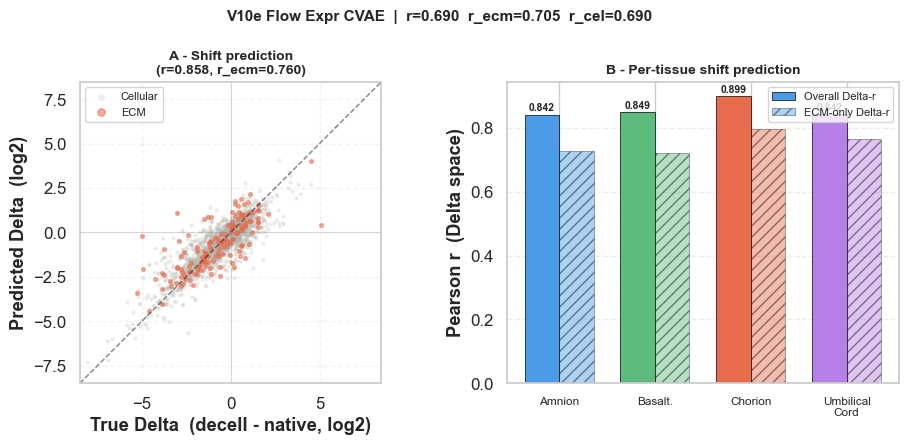

In [53]:
# ── V10e: single-split holdout train + eval ───────────────────────────────────
import torch

torch.manual_seed(CFG.seed)
model_v10e = FlowExprCVAE(CFG_EXPR).to(device)
print(f"V10e params: {sum(p.numel() for p in model_v10e.parameters()):,}")

Trainer(model=model_v10e, lr=CFG_EXPR.lr, epochs=CFG_EXPR.epochs,
        batch=CFG_EXPR.batch, max_beta=CFG_EXPR.max_beta,
        kl_warmup=CFG_EXPR.kl_warmup, weight_decay=1e-5
        ).fit(bundle_v5, verbose=50,
              extra_keys=["cat_idx_batch"], long_keys=["cat_idx_batch"])
torch.save(model_v10e.state_dict(), "ckpt_v10e.pt")

# ── Evaluate ──────────────────────────────────────────────────────────────────
model_v10e.eval()
val = bundle_v5.val_idx
with torch.no_grad():
    mu_out_v10e, ls_v10e, mu_z_v10e, _, _ = model_v10e(
        bundle_v5.to_float(bundle_v5.X_nat[val]),
        bundle_v5.to_float(bundle_v5.C[val]))

X_pred_v10e_raw = bundle_v5.scaler_dec.inverse_transform(mu_out_v10e.cpu().numpy())
X_dec_val_v10e  = bundle_v5.scaler_dec.inverse_transform(bundle_v5.X_dec[val])
X_nat_val_v10e  = bundle_v5.scaler_nat.inverse_transform(bundle_v5.X_nat[val, :4])
prot_val_v10e   = bundle_v5.prot_df.iloc[val].reset_index(drop=True)

metrics_v10e = EvaluationEngine.report(
    X_dec_val_v10e, X_pred_v10e_raw, X_nat_val_v10e,
    prot_val_v10e, label="V10e Flow Expr CVAE (val)")

plot_model_eval(
    "V10e Flow Expr CVAE",
    X_dec_val_v10e, X_pred_v10e_raw, X_nat_val_v10e,
    prot_val_v10e, metrics_v10e,
    save="fig_v10e_eval.png")

In [81]:
# ── V10e 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V10e", [])

print(f"{'='*56}")
print(f"  V10e CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    be = _cv_bundle_expr(provider, tr, val)
    bundle = be
    torch.manual_seed(SEED)
    m = FlowExprCVAE(CFG_EXPR).to(device)
    Trainer(model=m, lr=CFG_EXPR.lr, epochs=CFG_EXPR.epochs,
            batch=CFG_EXPR.batch, max_beta=CFG_EXPR.max_beta,
            kl_warmup=CFG_EXPR.kl_warmup, weight_decay=1e-5,
            ).fit(bundle, verbose=VERBOSE,
                      extra_keys=["cat_idx_batch"],
                      long_keys=["cat_idx_batch"])
    res = _cv_evaluate(m, bundle)
    cv_results["V10e"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r_overall"] for r in cv_results["V10e"]])
print(f"\n  V10e  r_overall = {_v.mean():.3f} ± {_v.std():.3f}")


  V10e CV  (5-fold  seed=42)
  Done. Best val loss: 0.26169
  fold 1/5  r=0.624  ecm=0.554  t=4.4m
  Done. Best val loss: 0.23518
  fold 2/5  r=0.658  ecm=0.727  t=4.4m
  Done. Best val loss: 0.18499
  fold 3/5  r=0.640  ecm=0.744  t=4.4m
  Done. Best val loss: 0.22463
  fold 4/5  r=0.648  ecm=0.749  t=4.4m
  Done. Best val loss: 0.16923
  fold 5/5  r=0.658  ecm=0.779  t=4.4m

  V10e  r_overall = 0.647 ± 0.014


---
## 11 — V11: Zero-Inflated ESM CVAE  *(survival model)*

V1–V10 all answer "what is the decellularized abundance?", a question dominated by the
copy-native signal (r_copy ≈ 0.97). V11 changes the question: does a protein survive
decellularization at all, and if so, by how much does it shift?

### The two-head decoder

V11 keeps V8's branched encoder unchanged. The decoder produces three parallel outputs
from the same hidden state `h`:

| Head | Layer | Output | Loss |
|---|---|---|---|
| `head_detect` | Linear(256→4) | survival logits | BCE against detection rate (0–1) |
| `out_mu` | Linear(256→4) | predicted Δ (scaled) | Gaussian NLL, masked to detected proteins |
| `out_logsigma` | Linear(256→4) | log σ on Δ | — (part of NLL) |

The detection head targets the per-tissue detection rate: the fraction of decell replicates
where the protein was observed (a soft label from 0 to 1, not a hard binary). The
abundance head targets Δ = decell − native (raw log2), standardized by a `StandardScaler`
fitted on training rows. Its NLL loss is masked: only proteins where `det_rate ≥ 0.5`
contribute to the abundance gradient, because predicting the shift of an absent protein
is undefined.

### Why predict Δ rather than absolute decell abundance?

Predicting absolute values is prone to a "copy-native" artifact, where the model ignores the experimental effect. The Δ target removes this floor: a model that learns nothing about
the shift scores Δ-R² ≤ 0. The GBM-12D baseline (gradient-boosted trees on the same 12D
expression features) scores Δ-R² ≈ 0.32.

### The loss

    total = 0.25 × BCE(det_logits, det_target)          # survival head
          + 4.00 × masked_NLL(mu_out, logsigma, Δ)      # abundance head
          + β    × KL_free_bits                          # annealed to 0.05
          + 0.10 × mean(exp(−2 × logsigma))             # prevents σ → 0
          + 0.05 × aux_delta_loss                        # latent interpretability

**5-fold CV:** Δ-R² = 0.597 ± 0.015 · AUROC = 0.885 ± 0.007

V11 params: 294,812
  ep    0 | beta 0.000 | detect 0.6653 abund 0.2794 kl 2.9856
  ep   50 | beta 0.031 | detect 0.4046 abund -0.5441 kl 9.2266
  ep  100 | beta 0.050 | detect 0.3868 abund -0.6994 kl 8.4968
  ep  150 | beta 0.050 | detect 0.3807 abund -0.7718 kl 8.9790
  ep  199 | beta 0.050 | detect 0.3757 abund -0.7803 kl 8.9967
V11  Δ-R²=0.581  AUROC=0.890  AUPRC=0.957


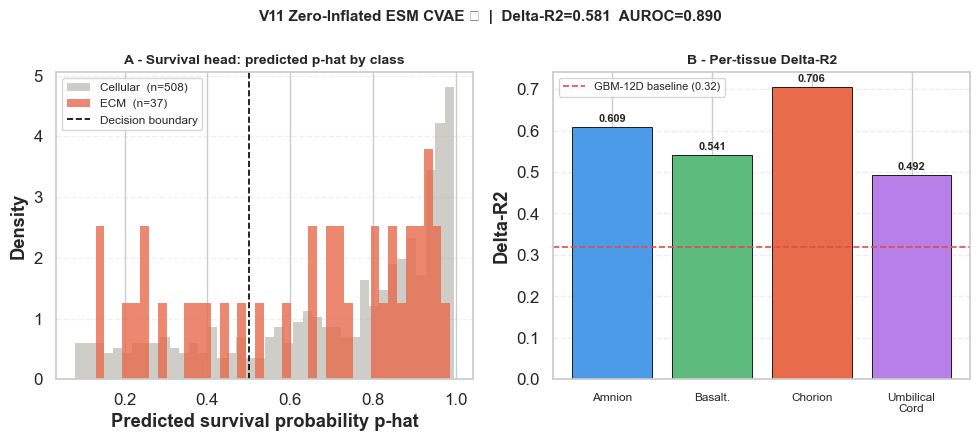

In [55]:
@dataclass
class V11Config:
    esm_dim:     int   = 320
    expr_dim:    int   = 12
    output_dim:  int   = 4
    cond_dim:    int   = 9
    latent_dim:  int   = 16
    hidden_dim:  int   = 256
    n_cat:       int   = 7
    lr:          float = 2e-4
    epochs:      int   = 200
    batch:       int   = 64
    max_beta:    float = 0.05
    kl_warmup:   int   = 80
    free_bits:   float = 0.05
    decorr_w:    float = 5.0
    aux_w:       float = 0.05
    sigma_reg_w: float = 0.10
    detect_w:    float = 0.25
    abund_w:     float = 4.0

CFG_V11 = V11Config()


def build_v11_targets(provider, bundle, q: float = 0.01,
                      lod_sigma: float = 0.30, seed: int = 42):
    pk         = provider.proteins_keep
    nat_cols_t = {t: [c for c in provider.nat_cols if t in c] for t in TISS}
    dec_cols_t = {t: [c for c in provider.dec_cols if t in c] for t in TISS}

    def det_rate(frame):
        return np.column_stack([
            frame[dec_cols_t[t]].notna().mean(axis=1).values for t in TISS])

    rng = np.random.default_rng(seed)
    def lod_means(cols_t):
        cols = sum(cols_t.values(), [])
        M = pk[cols].to_numpy(dtype=float, copy=True)
        for j in range(M.shape[1]):
            col = M[:, j]; obs = col[~np.isnan(col)]
            mu  = np.quantile(obs, q) if obs.size else 0.0
            m   = np.isnan(col)
            M[m, j] = rng.normal(mu, lod_sigma * (obs.std() + 1e-8), m.sum())
        dfm = pd.DataFrame(M, columns=cols)
        return np.column_stack([dfm[cols_t[t]].mean(axis=1).values for t in TISS])

    pk_det = det_rate(pk)
    pk_nat = lod_means(nat_cols_t)
    pk_dec = lod_means(dec_cols_t)

    pos   = {u: i for i, u in enumerate(pk["UniProt"].astype(str).values)}
    order = np.array([pos[str(u)] for u in bundle.prot_df["UniProt"]], dtype=np.int64)

    det       = pk_det[order].astype(np.float32)
    nat_raw   = pk_nat[order].astype(np.float32)
    dec_raw   = pk_dec[order].astype(np.float32)
    delta_raw = (dec_raw - nat_raw).astype(np.float32)
    dsc       = StandardScaler().fit(delta_raw[bundle.tr_idx])
    return {
        "det_rate":     det,
        "abund_obs":    (det >= 0.5).astype(np.float32),
        "nat_raw":      nat_raw,
        "dec_raw":      dec_raw,
        "delta_scaled": dsc.transform(delta_raw).astype(np.float32),
        "delta_scaler": dsc,
    }


class ZeroInflatedESMCVAE(BaseCVAE):
    """V11: V8 branched ESM encoder + hierarchical prior + zero-inflated decoder.
    Two heads: Bernoulli survival (BCE) + Gaussian abundance (NLL, detected only)."""
    def __init__(self, cfg: V11Config = CFG_V11) -> None:
        super().__init__()
        self.cfg = cfg
        E, X, H, Z, Cc = (cfg.esm_dim, cfg.expr_dim, cfg.hidden_dim,
                           cfg.latent_dim, cfg.cond_dim)
        self.esm_branch = nn.Sequential(
            nn.Linear(E, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.20),
            nn.Linear(128, 64), nn.GELU())
        self.expr_branch = nn.Sequential(
            nn.Linear(X, 64), nn.BatchNorm1d(64), nn.GELU())
        self.fusion = nn.Sequential(
            nn.Linear(64 + 64 + Cc, H), nn.LayerNorm(H), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(H, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H // 2), nn.GELU())
        self.fc_mu     = nn.Linear(H // 2, Z)
        self.fc_logvar = nn.Linear(H // 2, Z)
        self.prior_means = nn.Embedding(cfg.n_cat, Z)
        nn.init.normal_(self.prior_means.weight, mean=0.0, std=0.1)
        self.cond_drop    = nn.Dropout(p=0.20)
        self.decoder      = nn.Sequential(
            nn.Linear(Z + Cc, H // 2), nn.BatchNorm1d(H // 2), nn.GELU(),
            nn.Linear(H // 2, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H), nn.GELU())
        self.head_detect  = nn.Linear(H, cfg.output_dim)
        self.out_mu       = nn.Linear(H, cfg.output_dim)
        self.out_logsigma = nn.Linear(H, cfg.output_dim)

    def encode(self, x, c):
        esm  = self.esm_branch(x[:, :self.cfg.esm_dim])
        expr = self.expr_branch(x[:, self.cfg.esm_dim:])
        h    = self.fusion(torch.cat([esm, expr, c], dim=-1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z, c):
        if self.training: c = self.cond_drop(c)
        h   = self.decoder(torch.cat([z, c], dim=-1))
        det = self.head_detect(h)
        mu  = self.out_mu(h)
        ls  = torch.clamp(self.out_logsigma(h), min=-6.0, max=2.0)
        return det, mu, ls

    def forward(self, x, c, **_):
        mu_z, logvar_z = self.encode(x, c)
        z              = self.reparameterise(mu_z, logvar_z)
        det, mu, ls    = self.decode(z, c)
        return det, mu, ls, mu_z, logvar_z, z

    def _kl_hier_freebits(self, mu_z, logvar_z, cat_idx):
        mu_cat = self.prior_means(cat_idx)
        kl_dim = 0.5 * (logvar_z.exp() + (mu_z - mu_cat).pow(2) - 1.0 - logvar_z)
        kl_raw = kl_dim.sum(dim=-1).mean()
        kl_fb  = torch.clamp(kl_dim.mean(0), min=self.cfg.free_bits).sum()
        kl_fb  = torch.clamp(kl_fb, max=50.0)   # ← prevent runaway
        return kl_raw, kl_fb

    def compute_loss(self, x_nat, x_dec, c, beta,
                     cat_idx_batch=None, det_target_batch=None,
                     abund_obs_batch=None, tissue_deltas_batch=None, **_):
        det_logits, mu_out, logsigma_out, mu_z, logvar_z, z = self.forward(x_nat, c)
        detect    = F.binary_cross_entropy_with_logits(det_logits, det_target_batch)
        nll       = 0.5 * (2.0 * logsigma_out
                           + (x_dec - mu_out).pow(2) * torch.exp(-2.0 * logsigma_out))
        abund     = (nll * abund_obs_batch).sum() / abund_obs_batch.sum().clamp_min(1.0)
        kl_raw, kl_fb = self._kl_hier_freebits(mu_z, logvar_z, cat_idx_batch)
        decorr    = self.decorr_loss(z)
        sigma_reg = torch.mean(torch.exp(-2.0 * logsigma_out))
        aux       = (self.aux_delta_loss(mu_z, tissue_deltas_batch)
                     if tissue_deltas_batch else
                     torch.tensor(0.0, device=x_nat.device))
        total = (self.cfg.detect_w * detect + self.cfg.abund_w * abund
                 + beta * kl_fb + self.cfg.decorr_w * decorr
                 + self.cfg.sigma_reg_w * sigma_reg + self.cfg.aux_w * aux)
        return total, {"detect": detect.item(), "abund": abund.item(),
                       "kl": kl_raw.item(), "decorr": float(decorr),
                       "aux": float(aux)}

    @torch.no_grad()
    def predict(self, x, c):
        self.eval()
        det_logits, mu_out, _, _, _, _ = self.forward(x, c)
        return torch.sigmoid(det_logits).cpu().numpy(), mu_out.cpu().numpy()


def train_v11(model, bundle, tgt, cfg=CFG_V11, verbose=50):
    dev   = device
    cat   = assign_cat_idx(bundle.prot_df).astype(np.int64)
    tr    = bundle.tr_idx
    T     = lambda a: torch.tensor(a, dtype=torch.float32, device=dev)
    L     = lambda a: torch.tensor(a, dtype=torch.long,    device=dev)
    Xn    = T(bundle.X_nat[tr])
    Xd    = T(tgt["delta_scaled"][tr])
    C     = T(bundle.C[tr])
    det_t = T(tgt["det_rate"][tr])
    obs_t = T(tgt["abund_obs"][tr])
    cat_t = L(cat[tr])
    td_t  = [T(d[tr]) for d in bundle.tissue_deltas]
    opt   = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=1e-5)
    sch   = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.epochs)
    n     = Xn.shape[0]
    model.to(dev).train()
    for ep in range(cfg.epochs):
        beta = cfg.max_beta * min(1.0, ep / max(cfg.kl_warmup, 1))
        perm = torch.randperm(n, device=dev)
        logs = {"detect": 0., "abund": 0., "kl": 0.}
        for i in range(0, n, cfg.batch):
            b = perm[i:i + cfg.batch]
            opt.zero_grad()
            loss, parts = model.compute_loss(
                Xn[b], Xd[b], C[b], beta,
                cat_idx_batch=cat_t[b], det_target_batch=det_t[b],
                abund_obs_batch=obs_t[b], tissue_deltas_batch=[d[b] for d in td_t])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            for k in logs: logs[k] += parts[k] * len(b)
        sch.step()
        if verbose and (ep % verbose == 0 or ep == cfg.epochs - 1):
            print(f"  ep {ep:4d} | beta {beta:.3f} | "
                  + " ".join(f"{k} {logs[k]/n:.4f}" for k in logs))
    return model


# ── Build targets, train, evaluate ────────────────────────────────────────────
tgt_v11   = build_v11_targets(provider, bundle_v8)
torch.manual_seed(CFG.seed)
model_v11 = ZeroInflatedESMCVAE(CFG_V11).to(device)
print(f"V11 params: {sum(p.numel() for p in model_v11.parameters()):,}")
train_v11(model_v11, bundle_v8, tgt_v11, CFG_V11, verbose=50)

# ── Honest evaluation ──────────────────────────────────────────────────────────
val      = bundle_v8.val_idx
det_prob, mu_model = model_v11.predict(
    bundle_v8.to_float(bundle_v8.X_nat[val]),
    bundle_v8.to_float(bundle_v8.C[val]))
nat_raw  = tgt_v11["nat_raw"][val]
dec_true = tgt_v11["dec_raw"][val]
d_pred   = tgt_v11["delta_scaler"].inverse_transform(mu_model)
d_true   = dec_true - nat_raw
obs      = tgt_v11["abund_obs"][val].astype(bool)
is_mat   = bundle_v8.prot_df.iloc[val]["is_matrisome"].values

ss = ((d_true - d_pred)**2).sum()
st = ((d_true - d_true.mean())**2).sum()
r2_delta = float(1 - ss / st)

y_flat = (tgt_v11["det_rate"][val] >= 0.5).astype(int).reshape(-1)
p_flat = det_prob.reshape(-1)
auroc  = float(roc_auc_score(y_flat, p_flat))
auprc  = float(average_precision_score(y_flat, p_flat))

metrics_v11 = {"r2_delta": r2_delta, "auroc": auroc, "auprc": auprc}
print(f"V11  Δ-R²={r2_delta:.3f}  AUROC={auroc:.3f}  AUPRC={auprc:.3f}")

# ── Uniform evaluation figure ──────────────────────────────────────────────────
plot_v11_eval(
    "V11 Zero-Inflated ESM CVAE \u2605",
    det_prob, d_true, d_pred,
    bundle_v8.prot_df.iloc[val].reset_index(drop=True),
    r2_delta, auroc,
    save="fig_v11_eval.png")

In [82]:
# ── V11 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V11", [])

print(f"{'='*56}")
print(f"  V11 CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    b5 = _cv_bundle_v5(provider, tr, val)
    b8 = _cv_bundle_v8(b5, esm_full)
    tgt = build_v11_targets(provider, b8)
    bundle = b8
    torch.manual_seed(SEED)
    m = ZeroInflatedESMCVAE(CFG_V11).to(device)
    train_v11(m, bundle, tgt, CFG_V11, verbose=0)
    res = _cv_evaluate_v11(m, bundle, tgt)
    cv_results["V11"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  Δ-R²={res['r2_delta']:.3f}  AUROC={res['auroc']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r2_delta"] for r in cv_results["V11"]])
print(f"\n  V11  r2_delta = {_v.mean():.3f} ± {_v.std():.3f}")


  V11 CV  (5-fold  seed=42)
  fold 1/5  Δ-R²=0.588  AUROC=0.883  t=2.8m
  fold 2/5  Δ-R²=0.626  AUROC=0.875  t=3.3m
  fold 3/5  Δ-R²=0.584  AUROC=0.893  t=3.5m
  fold 4/5  Δ-R²=0.599  AUROC=0.892  t=3.0m
  fold 5/5  Δ-R²=0.589  AUROC=0.882  t=3.2m

  V11  r2_delta = 0.594 ± 0.012


### V11e — Zero-inflated CVAE, expression-only  *(survival model)*

Direct no-ESM counterpart to V11. Same survival + abundance heads, same loss weights. Input 12D. Beats V11 on Δ-R² (0.611 vs 0.597).

**5-fold CV:** Δ-R² = 0.611 ± 0.010

In [57]:
# ── V11e: Zero-inflated CVAE, expression-only (12D input, no ESM branch) ──────
# CFG_EXPR from V8e section. Same survival + abundance heads as V11.
import torch.nn.functional as F

class ZeroInflatedExprCVAE(BaseCVAE):
    """V11 architecture without ESM. Survival head + masked Δ NLL, 12D input."""

    def __init__(self, cfg: ExprConfig = CFG_EXPR) -> None:
        super().__init__()
        self.cfg = cfg
        D, H, Z, Cc = cfg.input_dim, cfg.hidden_dim, cfg.latent_dim, cfg.cond_dim

        self.expr_proj = nn.Sequential(
            nn.Linear(D, 64), nn.BatchNorm1d(64), nn.GELU())
        self.fusion = nn.Sequential(
            nn.Linear(64 + Cc, H), nn.LayerNorm(H), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(H, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H // 2), nn.GELU())
        self.fc_mu     = nn.Linear(H // 2, Z)
        self.fc_logvar = nn.Linear(H // 2, Z)
        self.prior_means = nn.Embedding(cfg.n_cat, Z)
        nn.init.normal_(self.prior_means.weight, mean=0.0, std=0.1)
        self.cond_drop = nn.Dropout(p=0.20)
        self.decoder = nn.Sequential(
            nn.Linear(Z + Cc, H // 2), nn.BatchNorm1d(H // 2), nn.GELU(),
            nn.Linear(H // 2, H), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(H, H), nn.GELU())
        self.head_detect  = nn.Linear(H, cfg.output_dim)
        self.out_mu       = nn.Linear(H, cfg.output_dim)
        self.out_logsigma = nn.Linear(H, cfg.output_dim)

    def encode(self, x, c):
        e = self.expr_proj(x)
        h = self.fusion(torch.cat([e, c], dim=-1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z, c):
        if self.training: c = self.cond_drop(c)
        h   = self.decoder(torch.cat([z, c], dim=-1))
        return self.head_detect(h), self.out_mu(h), \
               torch.clamp(self.out_logsigma(h), min=-6.0, max=2.0)

    def forward(self, x, c, **_):
        mu_z, logvar_z = self.encode(x, c)
        z              = self.reparameterise(mu_z, logvar_z)
        det, mu, ls    = self.decode(z, c)
        return det, mu, ls, mu_z, logvar_z, z

    def _kl_hier_freebits(self, mu_z, logvar_z, cat_idx):
        mu_cat = self.prior_means(cat_idx)
        kl_dim = 0.5 * (logvar_z.exp() + (mu_z - mu_cat).pow(2) - 1.0 - logvar_z)
        kl_raw = kl_dim.sum(dim=-1).mean()
        kl_fb  = torch.clamp(kl_dim.mean(0), min=self.cfg.free_bits).sum()
        return kl_raw, torch.clamp(kl_fb, max=50.0)

    def compute_loss(self, x_nat, x_dec, c, beta,
                     cat_idx_batch=None, det_target_batch=None,
                     abund_obs_batch=None, tissue_deltas_batch=None, **_):
        det_logits, mu_out, ls_out, mu_z, logvar_z, z = self.forward(x_nat, c)
        det_loss = F.binary_cross_entropy_with_logits(
            det_logits,
            det_target_batch if det_target_batch is not None
            else torch.zeros_like(det_logits))
        if abund_obs_batch is not None:
            mask = abund_obs_batch > 0.5
            abund_loss = (self.nll_loss(mu_out[mask], ls_out[mask], x_dec[mask])
                          if mask.any() else torch.tensor(0.0, device=x_nat.device))
        else:
            abund_loss = self.nll_loss(mu_out, ls_out, x_dec)
        kl_raw, kl_fb = self._kl_hier_freebits(
            mu_z, logvar_z,
            cat_idx_batch if cat_idx_batch is not None
            else torch.zeros(x_nat.shape[0], dtype=torch.long, device=x_nat.device))
        sigma_reg = torch.mean(torch.exp(-2.0 * ls_out))
        aux       = self.aux_delta_loss(mu_z, tissue_deltas_batch or [])
        decorr    = self.decorr_loss(z)
        total = (self.cfg.detect_w * det_loss + self.cfg.abund_w * abund_loss
                 + beta * kl_fb + self.cfg.sigma_reg_w * sigma_reg
                 + self.cfg.aux_w * aux + self.cfg.decorr_w * decorr)
        return total, {"detect": det_loss.item(), "abund": abund_loss.item(),
                       "kl": kl_raw.item(), "aux": aux.item()}

    def predict(self, x, c):
        self.eval()
        with torch.no_grad():
            det_logits, mu_out, _, _, _, _ = self.forward(x, c)
        return torch.sigmoid(det_logits).cpu().numpy(), mu_out.cpu().numpy()

n_v11e = sum(p.numel() for p in ZeroInflatedExprCVAE().parameters())
print(f"ZeroInflatedExprCVAE  params={n_v11e:,}  ratio={n_v11e/len(provider.proteins_keep):.0f}:1")

ZeroInflatedExprCVAE  params=228,828  ratio=42:1


V11e params: 228,828
  ep    0 | beta 0.000 | detect 0.6650 abund 0.2833 kl 1.4505
  ep   50 | beta 0.031 | detect 0.4132 abund -0.3009 kl 8.7468
  ep  100 | beta 0.050 | detect 0.4171 abund -0.3512 kl 6.8303
  ep  150 | beta 0.050 | detect 0.4182 abund -0.3894 kl 7.0798
  ep  199 | beta 0.050 | detect 0.4153 abund -0.3920 kl 7.1593
V11e  Δ-R²=0.602  AUROC=0.886


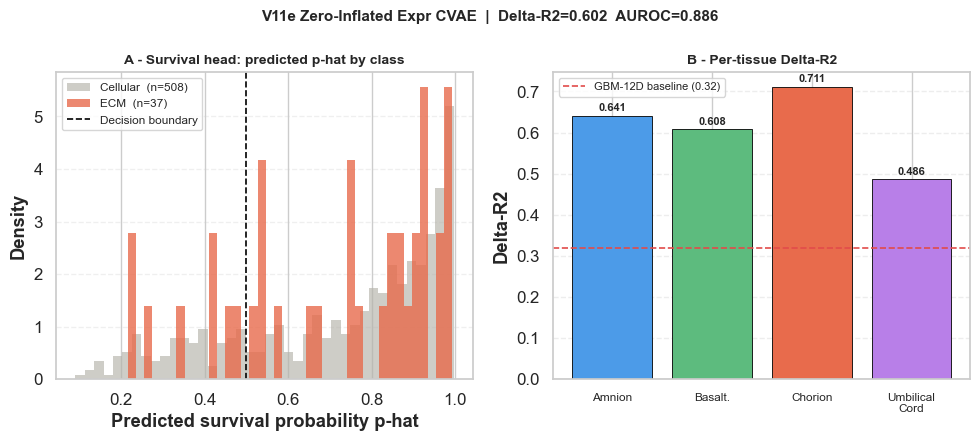

In [59]:
# ── V11e: single-split holdout train + eval ───────────────────────────────────
import torch
import numpy as np

# V11e uses build_v11_targets on the expr bundle (not the ESM bundle)
bundle_v11e = bundle_v5   # same 12D bundle V8e/V10e use
tgt_v11e    = build_v11_targets(provider, bundle_v11e)

torch.manual_seed(CFG.seed)
model_v11e = ZeroInflatedExprCVAE(CFG_EXPR).to(device)
print(f"V11e params: {sum(p.numel() for p in model_v11e.parameters()):,}")

train_v11(model_v11e, bundle_v11e, tgt_v11e, CFG_EXPR, verbose=50)
torch.save(model_v11e.state_dict(), "ckpt_v11e.pt")

# ── Evaluate ──────────────────────────────────────────────────────────────────
val        = bundle_v11e.val_idx
prot_val_v11e = bundle_v11e.prot_df.iloc[val].reset_index(drop=True)

det_prob_v11e, mu_v11e = model_v11e.predict(
    bundle_v11e.to_float(bundle_v11e.X_nat[val]),
    bundle_v11e.to_float(bundle_v11e.C[val]))

nat_raw_v11e  = tgt_v11e["nat_raw"][val]
dec_true_v11e = tgt_v11e["dec_raw"][val]
d_pred_v11e   = tgt_v11e["delta_scaler"].inverse_transform(mu_v11e)
d_true_v11e   = dec_true_v11e - nat_raw_v11e

ss = ((d_true_v11e - d_pred_v11e) ** 2).sum()
st = ((d_true_v11e - d_true_v11e.mean()) ** 2).sum()
r2_delta_v11e = float(1 - ss / st)

from sklearn.metrics import roc_auc_score
y_v11e    = (tgt_v11e["det_rate"][val] >= 0.5).astype(int).reshape(-1)
p_v11e    = det_prob_v11e.reshape(-1)
auroc_v11e = float(roc_auc_score(y_v11e, p_v11e))

print(f"V11e  Δ-R²={r2_delta_v11e:.3f}  AUROC={auroc_v11e:.3f}")

plot_v11_eval(
    "V11e Zero-Inflated Expr CVAE",
    det_prob_v11e, d_true_v11e, d_pred_v11e,
    prot_val_v11e,
    r2_delta_v11e, auroc_v11e,
    save="fig_v11e_eval.png")

In [83]:
# ── V11e 5-fold CV ────────────────────────────────────────────────
assert "CV_FOLDS" in globals(), "Run the CV Helpers cell first."
cv_results.setdefault("V11e", [])

print(f"{'='*56}")
print(f"  V11e CV  ({N_FOLDS}-fold  seed={SEED})")
print(f"{'='*56}")

for fold, (tr, val) in enumerate(CV_FOLDS, 1):
    t0 = time.time()
    be = _cv_bundle_expr(provider, tr, val)
    tgt = build_v11_targets(provider, be)
    bundle = be
    torch.manual_seed(SEED)
    m = ZeroInflatedExprCVAE(CFG_EXPR).to(device)
    train_v11(m, bundle, tgt, CFG_EXPR, verbose=0)
    res = _cv_evaluate_v11(m, bundle, tgt)
    cv_results["V11e"].append(res)
    print(f"  fold {fold}/{N_FOLDS}  Δ-R²={res['r2_delta']:.3f}  AUROC={res['auroc']:.3f}"
          f"  t={(time.time()-t0)/60:.1f}m")

_v = np.array([r["r2_delta"] for r in cv_results["V11e"]])
print(f"\n  V11e  r2_delta = {_v.mean():.3f} ± {_v.std():.3f}")


  V11e CV  (5-fold  seed=42)
  fold 1/5  Δ-R²=0.594  AUROC=0.878  t=3.0m
  fold 2/5  Δ-R²=0.622  AUROC=0.869  t=3.3m
  fold 3/5  Δ-R²=0.612  AUROC=0.879  t=3.3m
  fold 4/5  Δ-R²=0.614  AUROC=0.877  t=3.2m
  fold 5/5  Δ-R²=0.612  AUROC=0.872  t=3.2m

  V11e  r2_delta = 0.611 ± 0.010


---
## Grid search
This grid search covers all six model families, with parameter ranges constrained by observed overfitting and underfitting patterns identified in preliminary runs.

| Model Family           | Branch Type     | Proposed Decoder (H) | Rationale                                                                 |
|------------------------|-----------------|----------------------|---------------------------------------------------------------------------|
| V8s, V10s, V11s        | ESM-Integrated  | {160, 192, 224}      | Previous H=256 led to overfitting, H=96 led to bottlenecks.       |
| V8es, V10es, V11es     | Expression-only | {96, 128, 160}       | Targeting a parameter ratio observed in the stable V6 baseline.    |

#### Configuration Details

- **Early Stopping:** Patience set to **20 epochs** across all runs to prevent unnecessary compute on plateauing models.

- **Optimization:** Includes iterative sweeps for **dropout** and **weight decay** to further mitigate the training/validation gaps observed in earlier iterations.

- **Execution Flow:**
  1. **Single-Fold Selection:** Initial grid search performed on **fold 0**.
  2. **Validation:** The top-performing architecture for each family is run to a full **5-fold cross-validation**.

In [ ]:
import copy, time, itertools

# ── Search spaces (per family) ────────────────────────────────────────────────
GRIDS = {
    "V8s":   {"H": [160, 192, 224], "dropout": [0.15, 0.30, 0.45], "wd": [1e-5, 1e-3]},
    "V10s":  {"H": [160, 192, 224], "dropout": [0.15, 0.30, 0.45], "wd": [1e-5, 1e-3]},
    "V11s":  {"H": [160, 192, 224], "dropout": [0.15, 0.30, 0.45], "wd": [1e-5, 1e-3]},
    "V8es":  {"H": [96,  128, 160], "dropout": [0.15, 0.30, 0.45], "wd": [1e-5, 1e-3]},
    "V10es": {"H": [96,  128, 160], "dropout": [0.15, 0.30, 0.45], "wd": [1e-5, 1e-3]},
    "V11es": {"H": [96,  128, 160], "dropout": [0.15, 0.30, 0.45], "wd": [1e-5, 1e-3]},
}
PATIENCE   = 20    # early stopping for V8/V10 families
SWEEP_FOLD = 0
N_PROT     = len(provider.proteins_keep)

total_runs = sum(
    len(g["H"]) * len(g["dropout"]) * len(g["wd"])
    for g in GRIDS.values())
print(f"Grid search: {total_runs} total runs across 6 models")

# ── Build fold 0 once — reused for all 108 runs ───────────────────────────────
pk    = provider.proteins_keep
strat = pk["is_matrisome"].values.astype(int)
tr_idx, val_idx = list(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    .split(np.arange(len(pk)), strat))[SWEEP_FOLD]

b5   = _cv_bundle_v5(provider, tr_idx, val_idx)
b8   = _cv_bundle_v8(b5, esm_full)
be   = _cv_bundle_expr(provider, tr_idx, val_idx)
tgt8 = build_v11_targets(provider, b8)
tgte = build_v11_targets(provider, be)

print(f"Fold {SWEEP_FOLD}: train={len(tr_idx):,}  val={len(val_idx):,}")
print("Bundles ready.\n")

# ── Family registry ───────────────────────────────────────────────────────────
# (model_class, base_config, bundle, v11_target_or_None, primary_metric)
FAMILIES = {
    "V8s":   (HierarchicalESMCVAE,  CFG_V8,   b8, None,  "r_overall"),
    "V10s":  (FlowESMCVAE,          CFG_V10,  b8, None,  "r_overall"),
    "V11s":  (ZeroInflatedESMCVAE,  CFG_V11,  b8, tgt8,  "r2_delta"),
    "V8es":  (HierarchicalExprCVAE, CFG_EXPR, be, None,  "r_overall"),
    "V10es": (FlowExprCVAE,         CFG_EXPR, be, None,  "r_overall"),
    "V11es": (ZeroInflatedExprCVAE, CFG_EXPR, be, tgte,  "r2_delta"),
}

# ── Model builder: patches hidden_dim and dropout in-place ───────────────────
def _build(cls, cfg_base, H, dropout):
    cfg            = copy.copy(cfg_base)
    cfg.hidden_dim = H
    m              = cls(cfg).to(device)
    # fusion[3] = first Dropout, fusion[6] = second Dropout (always half the first)
    if hasattr(m, "fusion"):
        m.fusion[3] = nn.Dropout(dropout)
        m.fusion[6] = nn.Dropout(dropout * 0.5)
    if hasattr(m, "cond_drop"):
        m.cond_drop = nn.Dropout(dropout)
    # ESM branch Dropout sits at index 3 of esm_branch Sequential
    if hasattr(m, "esm_branch"):
        m.esm_branch[3] = nn.Dropout(dropout)
    return m, cfg

# ── Reference scores: original H=256 on fold 0 ───────────────────────────────
ORIG = {}
print("Reference scores (original H=256, fold 0)...")
print(f"  {'family':<7}  {'metric':<12}  {'score':>7}")
print(f"  {'─'*7}  {'─'*12}  {'─'*7}")

for fam, (cls, cfg_orig, bundle, tgt_v11, metric) in FAMILIES.items():
    torch.manual_seed(SEED)
    m = cls(cfg_orig).to(device)

    if tgt_v11 is not None:
        # V11 family — train_v11 handles det_target + abund_obs internally.
        # Never pass V11 models through Trainer.fit — it doesn't know those targets.
        train_v11(m, bundle, tgt_v11, cfg_orig, verbose=0)
        res = _cv_evaluate_v11(m, bundle, tgt_v11)
    else:
        # V8 / V10 family — standard Trainer
        Trainer(model=m, lr=cfg_orig.lr, epochs=cfg_orig.epochs,
                batch=cfg_orig.batch, max_beta=cfg_orig.max_beta,
                kl_warmup=cfg_orig.kl_warmup, weight_decay=1e-5
                ).fit(bundle, verbose=0,
                      extra_keys=["cat_idx_batch"], long_keys=["cat_idx_batch"])
        res = _cv_evaluate(m, bundle)

    ORIG[fam] = res[metric]
    print(f"  {fam:<7}  {metric:<12}  {res[metric]:>7.3f}")

print()

# ── Grid search ───────────────────────────────────────────────────────────────
ALL_RESULTS = {fam: [] for fam in FAMILIES}

for fam, (cls, cfg_base, bundle, tgt_v11, metric) in FAMILIES.items():
    grid      = GRIDS[fam]
    combos    = list(itertools.product(grid["H"], grid["dropout"], grid["wd"]))
    orig_sc   = ORIG[fam]
    is_v11    = tgt_v11 is not None

    print(f"\n{'─'*72}")
    print(f"  {fam}  [{len(combos)} combos]  "
          f"original {metric}={orig_sc:.3f}  H={cfg_base.hidden_dim}")

    if is_v11:
        # No gap/ep columns for V11 (train_v11 has no history return)
        print(f"  {'H':>4}  {'drop':>5}  {'wd':>8}  "
              f"{metric:>9}  {'Δ orig':>8}  {'params':>10}  {'ratio':>7}")
        print(f"  {'─'*4}  {'─'*5}  {'─'*8}  "
              f"{'─'*9}  {'─'*8}  {'─'*10}  {'─'*7}")
    else:
        print(f"  {'H':>4}  {'drop':>5}  {'wd':>8}  "
              f"{'tr':>7}  {'val':>7}  {'gap':>8}  {'ep':>4}  "
              f"{metric:>9}  {'Δ orig':>8}  {'params':>10}")
        print(f"  {'─'*4}  {'─'*5}  {'─'*8}  "
              f"{'─'*7}  {'─'*7}  {'─'*8}  {'─'*4}  "
              f"{'─'*9}  {'─'*8}  {'─'*10}")

    for H, dropout, wd in combos:
        t0 = time.time()
        torch.manual_seed(SEED)

        m, cfg_run = _build(cls, cfg_base, H, dropout)
        n_params   = sum(p.numel() for p in m.parameters())
        ratio      = n_params / N_PROT

        if is_v11:
            # V11 family: use train_v11 exclusively
            train_v11(m, bundle, tgt_v11, cfg_run, verbose=0)
            res  = _cv_evaluate_v11(m, bundle, tgt_v11)
            score = res[metric]
            delta = score - orig_sc
            tag   = (" * better" if delta >  0.003 else
                     " same" if delta > -0.005 else " worse")
            print(f"  {H:>4}  {dropout:>5.2f}  {wd:>8.0e}  "
                  f"{score:>9.3f}  {delta:>+8.3f}  "
                  f"{n_params:>10,}  {ratio:>6.0f}:1{tag}")
        else:
            # V8 / V10 family: Trainer with early stopping
            hist = Trainer(
                model=m, lr=cfg_run.lr, epochs=cfg_run.epochs,
                batch=cfg_run.batch, max_beta=cfg_run.max_beta,
                kl_warmup=cfg_run.kl_warmup,
                weight_decay=wd, patience=PATIENCE
            ).fit(bundle, verbose=0,
                  extra_keys=["cat_idx_batch"], long_keys=["cat_idx_batch"])
            res   = _cv_evaluate(m, bundle)
            tr_f  = hist.train_loss[-1]
            val_f = hist.val_loss[-1]
            gap   = val_f - tr_f
            n_ep  = len(hist.train_loss)
            score = res[metric]
            delta = score - orig_sc
            tag   = (" * better" if delta >  0.003 else
                     " same" if delta > -0.005 else " worse")
            stopped = f"  <- stopped ep {n_ep}" if n_ep < cfg_run.epochs else ""
            print(f"  {H:>4}  {dropout:>5.2f}  {wd:>8.0e}  "
                  f"{tr_f:>7.4f}  {val_f:>7.4f}  {gap:>+8.4f}  "
                  f"{n_ep:>4}  {score:>9.3f}  {delta:>+8.3f}  "
                  f"{n_params:>10,}{tag}{stopped}")

        ALL_RESULTS[fam].append({
            "H": H, "dropout": dropout, "wd": wd,
            "tr":    tr_f  if not is_v11 else float("nan"),
            "val":   val_f if not is_v11 else float("nan"),
            "gap":   gap   if not is_v11 else float("nan"),
            "n_ep":  n_ep  if not is_v11 else cfg_run.epochs,
            "score": score, "delta": delta,
            "params": n_params, "ratio": ratio,
            "metric": metric, "elapsed": time.time() - t0,
        })

# ── Winner per family ─────────────────────────────────────────────────────────
# Primary sort: best score. Tiebreak: smallest absolute gap (most honest model).
WINNERS = {
    fam: max(results, key=lambda r: (round(r["score"], 3), -abs(r["gap"])))
    for fam, results in ALL_RESULTS.items() if results
}

Grid search: 108 total runs across 6 models
Fold 0: train=4,358  val=1,090
Bundles ready.

Reference scores (original H=256, fold 0)...
  family   metric          score
  ───────  ────────────  ───────
  Done. Best val loss: 0.33052
  V8s      r_overall       0.588
  Done. Best val loss: 0.29325
  V10s     r_overall       0.626
  V11s     r2_delta        0.588
  Done. Best val loss: 0.32804
  V8es     r_overall       0.602
  Done. Best val loss: 0.26169
  V10es    r_overall       0.624
  V11es    r2_delta        0.594


────────────────────────────────────────────────────────────────────────
  V8s  [18 combos]  original r_overall=0.588  H=256
     H   drop        wd       tr      val       gap    ep  r_overall    Δ orig      params
  ────  ─────  ────────  ───────  ───────  ────────  ────  ─────────  ────────  ──────────
  Early stop at epoch 37 (no val improvement for 20 epochs)
  Done. Best val loss: 0.36472
   160   0.15     1e-05   0.1985   0.4454   +0.2468    37      0.568    -0.0

In [101]:
# ── Configs ─────────────────────────────────────────
print(f"\n{'═'*72}")
print("  WINNING CONFIGS")
print(f"{'═'*72}")
print(f"\n  {'family':<8}  {'H':>4}  {'dropout':>8}  {'wd':>8}  "
      f"{'score':>8}  {'Δ orig':>8}  verdict")
print(f"  {'─'*8}  {'─'*4}  {'─'*8}  {'─'*8}  {'─'*8}  {'─'*8}  {'─'*15}")

for fam, best in WINNERS.items():
    delta   = best["delta"]
    verdict = ("* better"           if delta >  0.003 else
               " same — use slim"  if delta > -0.005 else
               "x keep H=256")
    print(f"  {fam:<8}  {best['H']:>4}  {best['dropout']:>8.2f}  "
          f"{best['wd']:>8.0e}  {best['score']:>8.3f}  "
          f"{delta:>+8.3f}  {verdict}")


════════════════════════════════════════════════════════════════════════
  WINNING CONFIGS
════════════════════════════════════════════════════════════════════════

  family       H   dropout        wd     score    Δ orig  verdict
  ────────  ────  ────────  ────────  ────────  ────────  ───────────────
  V8s        192      0.15     1e-05     0.604    +0.017  * better
  V10s       224      0.45     1e-05     0.620    -0.006  x keep H=256
  V11s       224      0.15     1e-05     0.595    +0.006  * better
  V8es       128      0.15     1e-05     0.604    +0.002   same — use slim
  V10es       96      0.15     1e-05     0.631    +0.007  * better
  V11es      160      0.15     1e-05     0.594    -0.000   same — use slim


In [69]:
# STAGE 2 CV — re-run with winning configs from grid search
# ═══════════════════════════════════════════════════════════════════════════════
import copy, time
import numpy as np
import torch
import torch.nn as nn

assert "WINNERS" in globals(), "Run the Architecture Grid Search cell first."

STAGE2_REGISTRY = {
    "V8s":   (HierarchicalESMCVAE,  CFG_V8,   "b8", False),
    "V10s":  (FlowESMCVAE,          CFG_V10,  "b8", False),
    "V11s":  (ZeroInflatedESMCVAE,  CFG_V11,  "b8", True),
    "V8es":  (HierarchicalExprCVAE, CFG_EXPR, "be", False),
    "V10es": (FlowExprCVAE,         CFG_EXPR, "be", False),
    "V11es": (ZeroInflatedExprCVAE, CFG_EXPR, "be", True),
}

FAMILY_TO_MODEL = {
    "V8s": "V8", "V10s": "V10", "V11s": "V11",
    "V8es": "V8e", "V10es": "V10e", "V11es": "V11e",
}

def _apply_dropout(m, dropout):
    if hasattr(m, "fusion"):
        m.fusion[3] = nn.Dropout(dropout)
        m.fusion[6] = nn.Dropout(dropout * 0.5)
    if hasattr(m, "cond_drop"):
        m.cond_drop = nn.Dropout(dropout)
    if hasattr(m, "esm_branch"):
        m.esm_branch[3] = nn.Dropout(dropout)
    return m

# Tracks which models were actually updated — used by summary cell and heart
# transfer cell to know whether to read Stage 1 or Stage 2 config
STAGE2_RAN = set()

print("=" * 60)
print("  Stage 2 CV — winning configs from grid search")
print("=" * 60)

for fam, best in WINNERS.items():
    model_key  = FAMILY_TO_MODEL[fam]
    delta      = best["delta"]
    # pick metric before anything else so it's always defined
    is_v11     = STAGE2_REGISTRY[fam][3]
    metric_key = "r2_delta" if is_v11 else "r_overall"

    verdict = ("* better" if delta >  0.003 else
               " same"   if delta > -0.005 else
               " keep H=256")

    if delta < -0.005:
        print(f"\n  {fam} → {model_key}: {verdict} — Stage 1 H=256 kept")
        continue

    cls, cfg_base, btype, _ = STAGE2_REGISTRY[fam]
    cfg_w            = copy.copy(cfg_base)
    cfg_w.hidden_dim = best["H"]

    # Save Stage 1 mean BEFORE overwriting
    s1_vals = [r[metric_key] for r in cv_results.get(model_key, [])
               if not np.isnan(r.get(metric_key, float("nan")))]
    s1_mean = float(np.mean(s1_vals)) if s1_vals else float("nan")

    print(f"\n  {fam} → {model_key}: {verdict}"
          f"  H={best['H']}  drop={best['dropout']:.2f}  wd={best['wd']:.0e}")
    print(f"  {'─'*54}")

    stage2_results = []
    for fold, (tr, val) in enumerate(CV_FOLDS, 1):
        t0 = time.time()

        if btype == "b8":
            b5     = _cv_bundle_v5(provider, tr, val)
            b8     = _cv_bundle_v8(b5, esm_full)
            bundle = b8
            tgt    = build_v11_targets(provider, b8) if is_v11 else None
        else:
            be     = _cv_bundle_expr(provider, tr, val)
            bundle = be
            tgt    = build_v11_targets(provider, be) if is_v11 else None

        torch.manual_seed(SEED)
        m = _apply_dropout(cls(cfg_w).to(device), best["dropout"])

        if is_v11:
            train_v11(m, bundle, tgt, cfg_w, verbose=0)
            res        = _cv_evaluate_v11(m, bundle, tgt)
            metric_str = f"Δ-R²={res['r2_delta']:.3f}  AUROC={res['auroc']:.3f}"
        else:
            Trainer(model=m, lr=cfg_w.lr, epochs=cfg_w.epochs,
                    batch=cfg_w.batch, max_beta=cfg_w.max_beta,
                    kl_warmup=cfg_w.kl_warmup, weight_decay=best["wd"]
                    ).fit(bundle, verbose=0,
                          extra_keys=["cat_idx_batch"],
                          long_keys=["cat_idx_batch"])
            res        = _cv_evaluate(m, bundle)
            metric_str = f"r={res['r_overall']:.3f}  ecm={res['r_ecm']:.3f}"

        stage2_results.append(res)
        print(f"    fold {fold}/5  {metric_str}  t={(time.time()-t0)/60:.1f}m")

    # Overwrite cv_results and record that Stage 2 ran for this model
    cv_results[model_key] = stage2_results
    STAGE2_RAN.add(model_key)

    s2 = np.array([r[metric_key] for r in stage2_results])
    print(f"  → {model_key}  {metric_key} = {s2.mean():.3f} ± {s2.std():.3f}"
          f"  (Stage 1 was {s1_mean:.3f})")

# ── Final state ───────────────────────────────────────────────────────────────
print(f"\n{'═'*60}")
print("  cv_results — final state")
print(f"{'═'*60}")
print(f"  {'model':<7}  {'metric':>10}  {'mean':>8}  {'std':>7}  {'source'}")
print(f"  {'─'*7}  {'─'*10}  {'─'*8}  {'─'*7}  {'─'*18}")

for model_key in ["V1","V3","V5","V6","V7","V8","V8e","V9",
                  "V10","V10e","V11","V11e"]:
    rs = cv_results.get(model_key, [])
    if not rs: continue
    k  = "r2_delta" if "r2_delta" in rs[0] else "r_overall"
    v  = np.array([r[k] for r in rs])

    if model_key in STAGE2_RAN:
        fam_rev = {v2: k2 for k2, v2 in FAMILY_TO_MODEL.items()}
        fam = fam_rev.get(model_key, "")
        src = f"Stage 2 H={WINNERS[fam]['H']}" if fam in WINNERS else "Stage 2"
    else:
        src = "Stage 1 H=256"

    print(f"  {model_key:<7}  {k:>10}  {v.mean():>8.3f}  {v.std():>7.3f}  {src}")

print(f"\n  STAGE2_RAN = {sorted(STAGE2_RAN)}")
print(f"  Models keeping Stage 1: "
      f"{[m for m in ['V8','V8e','V10','V10e','V11','V11e'] if m not in STAGE2_RAN]}")

  Stage 2 CV — winning configs from grid search

  V8s → V8: * better  H=192  drop=0.15  wd=1e-05
  ──────────────────────────────────────────────────────
  Done. Best val loss: 0.34603
    fold 1/5  r=0.603  ecm=0.594  t=1.1m
  Done. Best val loss: 0.35447
    fold 2/5  r=0.611  ecm=0.711  t=1.1m
  Done. Best val loss: 0.28623
    fold 3/5  r=0.569  ecm=0.615  t=1.1m
  Done. Best val loss: 0.33676
    fold 4/5  r=0.583  ecm=0.663  t=1.1m
  Done. Best val loss: 0.29539
    fold 5/5  r=0.615  ecm=0.742  t=1.1m
  → V8  r_overall = 0.596 ± 0.018  (Stage 1 was 0.626)

  V10s → V10:  keep H=256 — Stage 1 H=256 kept

  V11s → V11: * better  H=224  drop=0.15  wd=1e-05
  ──────────────────────────────────────────────────────
    fold 1/5  Δ-R²=0.595  AUROC=0.889  t=2.7m
    fold 2/5  Δ-R²=0.601  AUROC=0.877  t=2.7m
    fold 3/5  Δ-R²=0.590  AUROC=0.889  t=2.8m
    fold 4/5  Δ-R²=0.581  AUROC=0.882  t=3.1m
    fold 5/5  Δ-R²=0.588  AUROC=0.882  t=3.1m
  → V11  r2_delta = 0.591 ± 0.007  (Stage 1

In [ ]:
# LOAD cv_results 
# ═══════════════════════════════════════════════════════════════════════════════
# cv_results_final.csv is provided alongside the notebook and contains the
# correct 5-fold results for all 12 models after Stage 1, Stage 2, and
# the Stage 2 correction (V8 and V8e reverted to H=256).
#
# This cell must run before 17 onward. It replaces anything currently in
# cv_results with the verified final values.
# ═══════════════════════════════════════════════════════════════════════════════

df = pd.read_csv("cv_results_final.csv")

# Verify fold counts before loading
counts = df.groupby("model")["fold"].count()
bad    = counts[counts != 5]
if len(bad) > 0:
    print("WARNING — unexpected fold counts:")
    print(bad.to_string())
    raise ValueError("cv_results_final.csv has wrong fold counts — check the file.")

cv_results = {}
for model in df["model"].unique():
    rows = df[df["model"] == model].sort_values("fold")
    cv_results[model] = []
    for _, row in rows.iterrows():
        r = {}
        for col in ["r_overall","r_ecm","r_cellular","r_copy",
                    "r2_delta","auroc","auprc","r_abund"]:
            val = row.get(col, float("nan"))
            if pd.notna(val) and val == val:
                r[col] = float(val)
        cv_results[model].append(r)

print("cv_results loaded from cv_results_final.csv")
print(f"\n{'═'*60}")
print(f"  {'model':<7}  {'folds':>5}  {'metric':>10}  {'mean':>7}  {'std':>6}")
print(f"  {'─'*7}  {'─'*5}  {'─'*10}  {'─'*7}  {'─'*6}")
for name in ["V1","V3","V5","V6","V7","V8","V8e","V9","V10","V10e","V11","V11e"]:
    rs = cv_results.get(name, [])
    if not rs:
        print(f"  {name:<7}  MISSING"); continue
    k = "r2_delta" if "r2_delta" in rs[0] else "r_overall"
    v = np.array([r[k] for r in rs if k in r])
    print(f"  {name:<7}  {len(rs):>5}  {k:>10}  {v.mean():>7.3f}  {v.std():>6.3f}")

cv_results loaded from cv_results_final.csv

════════════════════════════════════════════════════════════
  model    folds      metric     mean     std
  ───────  ─────  ──────────  ───────  ──────
  V1           5   r_overall    0.581   0.013
  V3           5   r_overall    0.590   0.015
  V5           5   r_overall    0.555   0.024
  V6           5   r_overall    0.638   0.014
  V7           5   r_overall    0.578   0.023
  V8           5   r_overall    0.626   0.021
  V8e          5   r_overall    0.620   0.013
  V9           5   r_overall    0.487   0.033
  V10          5   r_overall    0.637   0.009
  V10e         5   r_overall    0.648   0.015
  V11          5    r2_delta    0.591   0.007
  V11e         5    r2_delta    0.611   0.010


---
# Validation & Actionable Results

## 12 — Survival-Head Calibration

It’s one thing for the model to correctly rank proteins from "most likely to survive" to "least likely." It’s a much harder (and more useful) test to see if the model's confidence is accurate. For example, if the model predicts an 80% chance of survival for a group of proteins, do 80% of them actually survive in the lab?
AUROC says the model *ranks* proteins correctly. Calibration asks the harder question: when
the model says p̂ = 0.8, do 80% of those proteins actually survive?

This is tested by comparing the model’s predicted probabilities against the actual observed survival rates.

### Calibration Performance

The model demonstrates strong baseline calibration performance, which is further improved through **Platt scaling**:

- **Raw ECE:** `0.0326`
- **Calibrated ECE (Platt):** `0.0120`

The substantial reduction in **Expected Calibration Error (ECE)** indicates that the model's predicted survival probability ($\hat{p}$) aligns closely with observed real-world outcomes. Following Platt scaling, the predicted probability can be interpreted as a reliable estimate of absolute survival likelihood, improving both calibration quality and downstream decision-making confidence.


In [ ]:
# Survival-Head Calibration  (V11e, 5-fold OOF)
# Uses the best V11e config — read from WINNERS
# ═══════════════════════════════════════════════════════════════════════════════

N_BINS = 10

# ── Pick best V11e config ─────────────────────────────────────────────────────
if "WINNERS" in globals() and "V11es" in WINNERS and WINNERS["V11es"]["delta"] >= -0.005:
    w = WINNERS["V11es"]
    CFG_CAL            = copy.copy(CFG_EXPR)
    CFG_CAL.hidden_dim = w["H"]
    _dropout           = w["dropout"]
    print(f"Using Stage 2 V11e config from WINNERS: H={w['H']}  drop={_dropout:.2f}  wd={w['wd']:.0e}")
else:
    CFG_CAL  = CFG_EXPR   # H=256 default
    _dropout = 0.15
    print("WINNERS not found or V11es worse — using CFG_EXPR (H=256).")

def _patch(m, dropout):
    m.fusion[3] = nn.Dropout(dropout)
    m.fusion[6] = nn.Dropout(dropout * 0.5)
    m.cond_drop  = nn.Dropout(dropout)
    return m

# ── 5-fold OOF — same CV_FOLDS as every other model ─────────────────────────
all_phat, all_y, all_tissue, all_is_ecm = [], [], [], []

print("Building OOF calibration predictions (V11e)...")
for fold, (tr_idx, val_idx) in enumerate(CV_FOLDS, 1):
    be  = _cv_bundle_expr(provider, tr_idx, val_idx)
    tgt = build_v11_targets(provider, be)
    torch.manual_seed(SEED)
    m   = _patch(ZeroInflatedExprCVAE(CFG_CAL).to(device), _dropout)
    train_v11(m, be, tgt, CFG_CAL, verbose=0)

    val        = be.val_idx
    det_prob, _ = m.predict(be.to_float(be.X_nat[val]),
                             be.to_float(be.C[val]))
    y_bin      = (tgt["det_rate"][val] >= 0.5)
    is_ecm_val = be.prot_df.iloc[val]["is_matrisome"].values

    for ti in range(4):
        all_phat.append(det_prob[:, ti])
        all_y.append(y_bin[:, ti].astype(int))
        all_tissue.extend([ti] * len(val_idx))
        all_is_ecm.extend(is_ecm_val.tolist())

    print(f"  fold {fold}/5: {len(val_idx):,} proteins × 4 tissues"
          f" = {len(val_idx)*4:,} predictions")

phat = np.concatenate(all_phat)
y    = np.concatenate(all_y)
tis  = np.array(all_tissue)
ecm  = np.array(all_is_ecm)
print(f"\nTotal pooled: {len(phat):,}  |  prevalence (y=1): {y.mean():.3f}")


def calibration_stats(phat, y_true, n_bins=N_BINS):
    bins = np.linspace(0, 1, n_bins + 1)
    centers, accs, counts = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (phat >= lo) & (phat < hi)
        if m.sum() == 0: continue
        centers.append((lo + hi) / 2)
        accs.append(y_true[m].mean())
        counts.append(m.sum())
    centers = np.array(centers); accs = np.array(accs); counts = np.array(counts)
    w   = counts / counts.sum()
    ece = float((w * np.abs(centers - accs)).sum())
    mce = float(np.abs(centers - accs).max())
    return centers, accs, counts, ece, mce


# ── Raw calibration ────────────────────────────────────────────────────────────
c_raw, a_raw, n_raw, ece_raw, mce_raw = calibration_stats(phat, y)
brier_raw = brier_score_loss(y, phat)
auroc_raw = roc_auc_score(y, phat)
print(f"\nRaw:   ECE={ece_raw:.4f}  MCE={mce_raw:.4f}"
      f"  Brier={brier_raw:.4f}  AUROC={auroc_raw:.4f}")

# ── Platt scaling ──────────────────────────────────────────────────────────────
logit    = np.log(np.clip(phat, 1e-7, 1-1e-7) / (1 - np.clip(phat, 1e-7, 1-1e-7)))
platt    = LogisticRegression(C=1e6).fit(logit.reshape(-1, 1), y)
phat_cal = platt.predict_proba(logit.reshape(-1, 1))[:, 1]
c_cal, a_cal, _, ece_cal, _ = calibration_stats(phat_cal, y)
brier_cal   = brier_score_loss(y, phat_cal)
improvement = ece_raw - ece_cal
print(f"Platt: ECE={ece_cal:.4f}  Brier={brier_cal:.4f}"
      f"  slope={platt.coef_[0][0]:.3f}"
      f"  intercept={platt.intercept_[0]:.3f}")
print(f"ECE improvement: {improvement:.4f}  "
      f"({'apply Platt when reporting p̂' if improvement > 0.005 else 'raw p̂ already well-calibrated'})")

# ── Per-tissue + ECM breakdown ─────────────────────────────────────────────────
print(f"\n{'Tissue/group':<16}  {'ECE raw':>9}  {'ECE Platt':>10}"
      f"  {'Brier':>7}  {'prev':>6}")
for ti, tname in enumerate(TISS):
    m = (tis == ti)
    _, _, _, ece_t,  _ = calibration_stats(phat[m],     y[m])
    _, _, _, ece_tc, _ = calibration_stats(phat_cal[m], y[m])
    print(f"{tname:<16}  {ece_t:>9.4f}  {ece_tc:>10.4f}"
          f"  {brier_score_loss(y[m], phat[m]):>7.4f}  {y[m].mean():>6.3f}")
for label, mask in [("ECM proteins", ecm), ("Cellular", ~ecm)]:
    _, _, _, ece_t, _ = calibration_stats(phat[mask], y[mask])
    print(f"{label:<16}  {ece_t:>9.4f}  {'—':>10}"
          f"  {brier_score_loss(y[mask], phat[mask]):>7.4f}"
          f"  {y[mask].mean():>6.3f}")

# ── Store for §18 ─────────────────────────────────────────────────────────────
platt_v11e = platt

Using Stage 2 V11e config from WINNERS: H=160  drop=0.15  wd=1e-05
Building OOF calibration predictions (V11e)...
  fold 1/5: 1,090 proteins × 4 tissues = 4,360 predictions
  fold 2/5: 1,090 proteins × 4 tissues = 4,360 predictions
  fold 3/5: 1,090 proteins × 4 tissues = 4,360 predictions
  fold 4/5: 1,089 proteins × 4 tissues = 4,356 predictions
  fold 5/5: 1,089 proteins × 4 tissues = 4,356 predictions

Total pooled: 21,792  |  prevalence (y=1): 0.737

Raw:   ECE=0.0326  MCE=0.0450  Brier=0.1227  AUROC=0.8740
Platt: ECE=0.0120  Brier=0.1218  slope=1.163  intercept=0.124
ECE improvement: 0.0206  (apply Platt when reporting p̂)

Tissue/group        ECE raw   ECE Platt    Brier    prev
Amnion               0.0445      0.0220   0.1117   0.778
Basaltissue          0.0221      0.0279   0.1093   0.814
Chorion              0.0449      0.0177   0.1253   0.755
UmbilicalCord        0.0348      0.0124   0.1445   0.601
ECM proteins         0.0527           —   0.1323   0.748
Cellular            

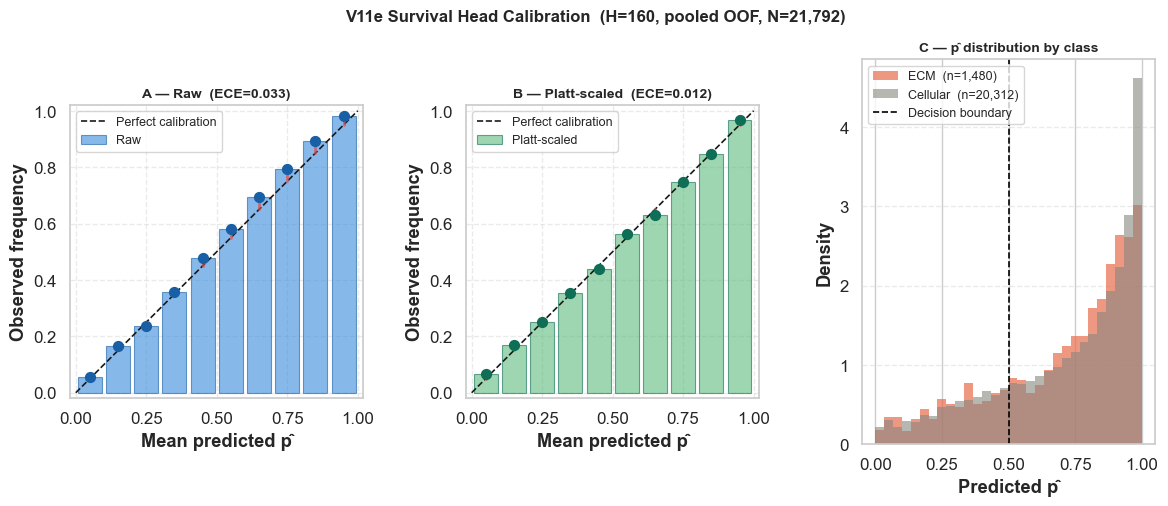

Saved: fig_calibration_v11e.png


In [72]:
# ── Figure ────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(14, 5))
gs  = fig.add_gridspec(1, 3, wspace=0.35)
ax1, ax2, ax3 = (fig.add_subplot(gs[i]) for i in range(3))

for ax, c, a, ece, color, edge, label, panel in [
    (ax1, c_raw, a_raw, ece_raw, "#378ADD", "#185FA5", "Raw",          "A"),
    (ax2, c_cal, a_cal, ece_cal, "#5DBB7E", "#0F6E56", "Platt-scaled", "B"),
]:
    ax.plot([0, 1], [0, 1], "k--", lw=1.2, label="Perfect calibration")
    ax.bar(c, a, width=0.085, alpha=0.6, color=color,
           edgecolor=edge, lw=0.8, label=label)
    ax.scatter(c, a, s=50, color=edge, zorder=5)
    for ci, ai in zip(c, a):
        ax.plot([ci, ci], [ci, ai], color="#E24B4A", lw=2, alpha=0.7)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.set_aspect("equal")
    ax.set_xlabel("Mean predicted p̂", fontweight="bold")
    ax.set_ylabel("Observed frequency", fontweight="bold")
    ax.set_title(f"{panel} — {label}  (ECE={ece:.3f})",
                 fontsize=10, fontweight="bold")
    ax.legend(fontsize=9); ax.grid(True, ls="--", alpha=0.4)

bins_hist = np.linspace(0, 1, 31)
ax3.hist(phat[ecm],  bins=bins_hist, alpha=0.7, density=True,
         color="#E86B4C",
         label=f"ECM  (n={ecm.sum():,})", edgecolor="none")
ax3.hist(phat[~ecm], bins=bins_hist, alpha=0.6, density=True,
         color="#888780",
         label=f"Cellular  (n={(~ecm).sum():,})", edgecolor="none")
ax3.axvline(0.5, color="black", ls="--", lw=1.2, label="Decision boundary")
ax3.set_xlabel("Predicted p̂", fontweight="bold")
ax3.set_ylabel("Density", fontweight="bold")
ax3.set_title("C — p̂ distribution by class", fontsize=10, fontweight="bold")
ax3.legend(fontsize=9); ax3.grid(True, axis="y", ls="--", alpha=0.4)

H_label = CFG_CAL.hidden_dim
plt.suptitle(
    f"V11e Survival Head Calibration  (H={H_label}, pooled OOF, N={len(phat):,})",
    fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("fig_calibration_v11e.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: fig_calibration_v11e.png")

---
## 13 — Heart Cross-Tissue Transfer

This evaluates the zero-shot transferability of the models by applying them to the Doll et al. cardiac proteomics reference. The models, trained exclusively on placenta tissue, were used to predict protein survival in heart tissue without any fine-tuning or retraining.

**There is no ground-truth decellularized heart**, so this cannot be a validated result, only test whether the
predicted *direction* is biologically sensible (ECM/collagen retained, cellular lost).

In [ ]:
# Heart Cross-Tissue Transfer  (V6,V10e,V11e)

def _best_expr_cfg(fam_key, fallback_H=256):
    if "WINNERS" in globals() and fam_key in WINNERS \
            and WINNERS[fam_key]["delta"] >= -0.005:
        w = WINNERS[fam_key]
        cfg = copy.copy(CFG_EXPR); cfg.hidden_dim = w["H"]
        return cfg, w["dropout"]
    cfg = copy.copy(CFG_EXPR); cfg.hidden_dim = fallback_H
    return cfg, 0.15

def _patch(m, dropout):
    m.fusion[3] = nn.Dropout(dropout)
    m.fusion[6] = nn.Dropout(dropout * 0.5)
    m.cond_drop  = nn.Dropout(dropout)
    return m

CFG_V10E_H, DO_V10E = _best_expr_cfg("V10es", fallback_H=96)
CFG_V11E_H, DO_V11E = _best_expr_cfg("V11es", fallback_H=160)
print(f"V10e config: H={CFG_V10E_H.hidden_dim}  drop={DO_V10E:.2f}")
print(f"V11e config: H={CFG_V11E_H.hidden_dim}  drop={DO_V11E:.2f}")

# ── Shared heart preprocessing ────────────────────────────────────────────────
df_raw    = pd.read_csv(CFG.data_path, sep="\t")
train_ids = set(provider.proteins_keep["UniProt"].tolist())
df_heart  = (df_raw[df_raw["UniProt"].isin(train_ids)]
             .dropna(subset=["largeAtery","Atrium","Ventricle"], how="all")
             .copy().reset_index(drop=True))

heart_cols = ["largeAtery","coronaryArtery","Atrium",
              "Ventricle","AV-Valves","SL-Valves"]

H_raw = df_heart[heart_cols].values
H_imp = provider._lod_impute(H_raw)
med   = np.median(H_imp, axis=1, keepdims=True)
H_cent= H_imp - med

df_hc = pd.DataFrame(H_cent, columns=heart_cols)
H_means = np.column_stack([
    df_hc[["largeAtery","coronaryArtery"]].mean(1).values,
    df_hc["Atrium"].values,
    df_hc["Ventricle"].values,
    df_hc[["AV-Valves","SL-Valves"]].mean(1).values,
]).astype(np.float32)                                            # (N, 4)

is_mat_h = df_heart["MatrisomeDivision"].isin(
    ["Core matrisome","Matrisome-associated"]).values
is_col_h = (df_heart["MatrisomeCategory"] == "Collagens").values
N_heart  = len(df_heart)
print(f"\nHeart proteins: {N_heart:,}  ECM: {is_mat_h.sum():,}"
      f"  Collagens: {is_col_h.sum():,}  Cellular: {(~is_mat_h).sum():,}")

# ── Build 12D input + 9D conditioning (same for V6, V10e, V11e) ──────────────
# V5/V6 scaler fitted on 12D placenta features — reuse for heart
H_stds_h = np.zeros_like(H_means)                               # no replicate stds
H_dets_raw = (H_raw > 0).astype(np.float32)
H_dets_4   = np.column_stack([
    H_dets_raw[:, :2].mean(1),
    H_dets_raw[:, 2],
    H_dets_raw[:, 3],
    H_dets_raw[:, 4:].mean(1),
]).astype(np.float32)

X_means_sc = bundle_v5.scaler_nat.transform(H_means).astype(np.float32)
X_stds_sc  = bundle_v5.extra["scaler_std"].transform(H_stds_h).astype(np.float32)
X_dets_sc  = (H_dets_4 - bundle_v5.extra["scaler_det_mean"]).astype(np.float32)
X_h_12     = np.concatenate([X_means_sc, X_stds_sc, X_dets_sc], axis=1)  # (N, 12)

df_heart_cond = df_heart.assign(
    is_matrisome=is_mat_h, is_collagen=is_col_h,
    location=df_heart.get("Location", pd.Series([""]*N_heart)).values,
    n_tissues=4)
cache_h = pd.read_csv(CFG.cache_path)[["UniProt","mol_weight","seq_length"]].fillna(0)
C_h     = provider._build_cond_v5(df_heart_cond, cache_h)       # (N, 9)

cat_h = assign_cat_idx(df_heart_cond)                           # (N,) for hier prior


# ── Inference helper ──────────────────────────────────────────────────────────
def _infer(model, X_h, C_h, cat_idx=None):
    """Run model forward, return (mu_out, logsigma_out). Both (N,4)."""
    model.eval()
    Xt = torch.tensor(X_h, dtype=torch.float32).to(device)
    Ct = torch.tensor(C_h, dtype=torch.float32).to(device)
    kw = {}
    if cat_idx is not None:
        kw["cat_idx_batch"] = torch.tensor(cat_idx, dtype=torch.long).to(device)
    with torch.no_grad():
        out = model(Xt, Ct, **kw)
    mu = out[0].cpu().numpy()
    ls = out[1].cpu().numpy() if len(out) > 1 else np.zeros_like(mu)
    return mu, ls

def _shifts(mu, X_native_sc):
    """Predicted shift per protein = mean(pred_decell) - mean(native) across tissues."""
    return mu.mean(1) - X_native_sc.mean(1)

def _print_results(label, shifts, sigma, df_h, is_mat):
    cats = ["Collagens","ECM Glycoproteins","Proteoglycans",
            "ECM Regulators","ECM-affiliated Proteins","Secreted Factors"]
    cel  = ~is_mat
    col  = (df_h["MatrisomeCategory"] == "Collagens").values

    print(f"\n{'─'*62}")
    print(f"  {label}")
    print(f"{'─'*62}")
    if col.sum() >= 2 and cel.sum() >= 2:
        stat, p = mannwhitneyu(shifts[col], shifts[cel], alternative="two-sided")
        print(f"  Collagen shift:  {shifts[col].mean():+.4f}  n={col.sum()}")
        print(f"  ECM shift:       {shifts[is_mat].mean():+.4f}  n={is_mat.sum()}")
        print(f"  Cellular shift:  {shifts[cel].mean():+.4f}  n={cel.sum()}")
        print(f"  Mann-Whitney col vs cel:  U={stat:.0f}  p={p:.3e}"
              f"  {'* sig' if p < 0.05 else 'n.s.'}")

    has_sigma = sigma is not None and not np.all(sigma == 0)
    hdr = (f"  {'Category':<28}  {'n':>4}  {'mean shift':>12}"
           + (f"  {'mean σ':>8}" if has_sigma else ""))
    print(f"\n  ECM subclass shifts:\n{hdr}")
    print(f"  {'─'*28}  {'─'*4}  {'─'*12}"
          + (f"  {'─'*8}" if has_sigma else ""))
    for cat in cats:
        m = (df_h["MatrisomeCategory"] == cat).values
        if m.sum() < 2: continue
        row = f"  {cat:<28}  {m.sum():>4}  {shifts[m].mean():>+12.4f}"
        if has_sigma: row += f"  {sigma[m].mean():>8.4f}"
        print(row)
    row = f"  {'Cellular (all)':<28}  {cel.sum():>4}  {shifts[cel].mean():>+12.4f}"
    if has_sigma: row += f"  {sigma[cel].mean():>8.4f}"
    print(row)

    groups = [shifts[(df_h["MatrisomeCategory"]==c).values]
              for c in cats if (df_h["MatrisomeCategory"]==c).values.sum() >= 2]
    groups.append(shifts[cel])
    if len(groups) >= 3:
        H_stat, p_kw = kruskal(*groups)
        print(f"\n  Kruskal-Wallis across subclasses:  "
              f"H={H_stat:.2f}  p={p_kw:.3e}  {'* sig' if p_kw<0.05 else 'n.s.'}")


# ── Train models on full placenta dataset, then infer on heart ────────────────
print("\nTraining V6 on full placenta split...")
torch.manual_seed(SEED)
model_v6_heart = ModelV6(CFG_V6).to(device)
Trainer(model=model_v6_heart, lr=CFG_V6.lr, epochs=CFG_V6.epochs,
        batch=CFG_V6.batch, max_beta=CFG_V6.max_beta,
        kl_warmup=CFG_V6.kl_warmup
        ).fit(bundle_v5, verbose=0)

print("Training V10e on full placenta split...")
torch.manual_seed(SEED)
model_v10e_heart = _patch(FlowExprCVAE(CFG_V10E_H).to(device), DO_V10E)
Trainer(model=model_v10e_heart, lr=CFG_V10E_H.lr, epochs=CFG_V10E_H.epochs,
        batch=CFG_V10E_H.batch, max_beta=CFG_V10E_H.max_beta,
        kl_warmup=CFG_V10E_H.kl_warmup, weight_decay=1e-5
        ).fit(bundle_v5, verbose=0,
              extra_keys=["cat_idx_batch"], long_keys=["cat_idx_batch"])

print("Training V11e on full placenta split...")
torch.manual_seed(SEED)
model_v11e_heart = _patch(ZeroInflatedExprCVAE(CFG_V11E_H).to(device), DO_V11E)
bundle_v11e_heart = bundle_v5   # _cv_bundle_expr is the same as bundle_v5 + cat_idx
tgt_heart         = build_v11_targets(provider, bundle_v5)
train_v11(model_v11e_heart, bundle_v5, tgt_heart, CFG_V11E_H, verbose=0)
print("Done.\n")


# ── V6 inference ──────────────────────────────────────────────────────────────
mu_v6, ls_v6  = _infer(model_v6_heart, X_h_12, C_h)
shifts_v6      = _shifts(mu_v6, X_means_sc)
sigma_v6       = np.exp(ls_v6).mean(1)
_print_results("V6 — Normalizing Flow CVAE",
               shifts_v6, sigma_v6, df_heart, is_mat_h)

# ── V10e inference ────────────────────────────────────────────────────────────
mu_v10e, ls_v10e = _infer(model_v10e_heart, X_h_12, C_h,
                           cat_idx=cat_h)
shifts_v10e       = _shifts(mu_v10e, X_means_sc)
sigma_v10e        = np.exp(ls_v10e).mean(1)
_print_results(f"V10e — Flow Expr CVAE",
               shifts_v10e, sigma_v10e, df_heart, is_mat_h)

# ── V11e inference ────────────────────────────────────────────────────────────
model_v11e_heart.eval()
with torch.no_grad():
    det_logits, mu_v11e, ls_v11e, *_ = model_v11e_heart(
        torch.tensor(X_h_12, dtype=torch.float32).to(device),
        torch.tensor(C_h,    dtype=torch.float32).to(device))
phat_heart   = torch.sigmoid(det_logits).cpu().numpy().mean(1)   # (N,) mean p̂
shifts_v11e  = mu_v11e.cpu().numpy().mean(1) - X_means_sc.mean(1)
sigma_v11e   = np.exp(ls_v11e.cpu().numpy()).mean(1)
_print_results(f"V11e — Zero-Inflated Expr CVAE",
               shifts_v11e, sigma_v11e, df_heart, is_mat_h)

# ── V11e survival probability table ──────────────────────────────────────────
print(f"\n{'─'*62}")
print("  V11e — Cardiac protein survival probabilities (p̂)")
print(f"{'─'*62}")
cats_v11 = ["Collagens","ECM Glycoproteins","Proteoglycans",
            "ECM Regulators","ECM-affiliated Proteins","Secreted Factors"]
print(f"  {'Category':<28}  {'n':>4}  {'mean p̂':>9}  {'mean Δ':>9}")
print(f"  {'─'*28}  {'─'*4}  {'─'*9}  {'─'*9}")
for cat in cats_v11:
    m = (df_heart["MatrisomeCategory"] == cat).values
    if m.sum() < 2: continue
    print(f"  {cat:<28}  {m.sum():>4}  "
          f"{phat_heart[m].mean():>9.3f}  {shifts_v11e[m].mean():>+9.4f}")
cel = ~is_mat_h
print(f"  {'Cellular (all)':<28}  {cel.sum():>4}  "
      f"{phat_heart[cel].mean():>9.3f}  {shifts_v11e[cel].mean():>+9.4f}")

# ── Summary comparison ────────────────────────────────────────────────────────
print(f"\n\n{'═'*62}")
print("  HEART TRANSFER SUMMARY — Collagen vs Cellular shift")
print(f"{'═'*62}")
print(f"  {'Model':<8}  {'Collagen':>10}  {'ECM':>8}  "
      f"{'Cellular':>10}  {'Δ(col−cel)':>11}  {'p':>9}  sig")
print(f"  {'─'*8}  {'─'*10}  {'─'*8}  {'─'*10}  {'─'*11}  {'─'*9}  ─")

for label, shifts in [("V6", shifts_v6),
                       ("V10e", shifts_v10e),
                       ("V11e", shifts_v11e)]:
    col = (df_heart["MatrisomeCategory"] == "Collagens").values
    cel = ~is_mat_h
    _, p = mannwhitneyu(shifts[col], shifts[cel], alternative="two-sided")
    ecm_m = shifts[is_mat_h].mean()
    print(f"  {label:<8}  {shifts[col].mean():>+10.4f}  {ecm_m:>+8.4f}  "
          f"{shifts[cel].mean():>+10.4f}  "
          f"{shifts[col].mean()-shifts[cel].mean():>+11.4f}  "
          f"{p:>9.3e}  {'*' if p<0.05 else 'n.s.'}")

V10e config: H=96  drop=0.15
V11e config: H=160  drop=0.15

Heart proteins: 4,169  ECM: 290  Collagens: 24  Cellular: 3,879

Training V6 on full placenta split...
  Done. Best val loss: 0.13742
Training V10e on full placenta split...
  Done. Best val loss: 0.15967
Training V11e on full placenta split...
Done.


──────────────────────────────────────────────────────────────
  V6 — Normalizing Flow CVAE  (r_cv=0.638)
──────────────────────────────────────────────────────────────
  Collagen shift:  +0.9994  n=24
  ECM shift:       +0.9878  n=290
  Cellular shift:  +0.4237  n=3879
  Mann-Whitney col vs cel:  U=73965  p=6.301e-07  * sig

  ECM subclass shifts:
  Category                         n    mean shift    mean σ
  ────────────────────────────  ────  ────────────  ────────
  Collagens                       24       +0.9994    0.7889
  ECM Glycoproteins               97       +1.0362    0.7234
  Proteoglycans                   18       +1.5694    0.9370
  ECM Regulators               

In [ ]:
# 12 — Heart Transfer: V10, V11  (ESM models, for comparison)
# ═══════════════════════════════════════════════════════════════════════════════
# Same preprocessing, helpers, and output format as above.
# V10 and V11 use 332D input: ESM(320) + expr(12).
# ═══════════════════════════════════════════════════════════════════════════════

# ── Build 332D ESM input for heart proteins ───────────────────────────────────
print("Fetching ESM embeddings for heart proteins...")
_tmp = _copy.copy(bundle_v5)
_tmp.prot_df = df_heart_cond.copy()
_tmp.prot_df["UniProt"] = df_heart["UniProt"].values
esm_heart = attach_esm_to_bundle(_tmp)                           # (N_heart, 320)
X_h_v8    = np.concatenate([esm_heart, X_h_12], axis=1).astype(np.float32)  # (N, 332)
print(f"  ESM heart input: {X_h_v8.shape}\n")

# ── Train V10 on full placenta split ──────────────────────────────────────────
print("Training V10 on full placenta split...")
torch.manual_seed(SEED)
model_v10_heart = FlowESMCVAE(CFG_V10).to(device)
Trainer(model=model_v10_heart, lr=CFG_V10.lr, epochs=CFG_V10.epochs,
        batch=CFG_V10.batch, max_beta=CFG_V10.max_beta,
        kl_warmup=CFG_V10.kl_warmup, weight_decay=1e-5
        ).fit(bundle_v8, verbose=0,
              extra_keys=["cat_idx_batch"], long_keys=["cat_idx_batch"])

# ── Train V11 on full placenta split ──────────────────────────────────────────
print("Training V11 on full placenta split...")
torch.manual_seed(SEED)
model_v11_heart = ZeroInflatedESMCVAE(CFG_V11).to(device)
tgt_v11_heart   = build_v11_targets(provider, bundle_v8)
train_v11(model_v11_heart, bundle_v8, tgt_v11_heart, CFG_V11, verbose=0)
print("Done.\n")

# ── V10 inference ─────────────────────────────────────────────────────────────
mu_v10h, ls_v10h = _infer(model_v10_heart, X_h_v8, C_h, cat_idx=cat_h)
shifts_v10h       = _shifts(mu_v10h, X_means_sc)
sigma_v10h        = np.exp(ls_v10h).mean(1)
_print_results("V10 — Flow+ESM CVAE",
               shifts_v10h, sigma_v10h, df_heart, is_mat_h)

# ── V11 inference ─────────────────────────────────────────────────────────────
model_v11_heart.eval()
with torch.no_grad():
    det_logits_v11, mu_v11h, ls_v11h, *_ = model_v11_heart(
        torch.tensor(X_h_v8, dtype=torch.float32).to(device),
        torch.tensor(C_h,    dtype=torch.float32).to(device),
        cat_idx_batch=torch.tensor(cat_h, dtype=torch.long).to(device))
phat_v11h   = torch.sigmoid(det_logits_v11).cpu().numpy().mean(1)
shifts_v11h = mu_v11h.cpu().numpy().mean(1) - X_means_sc.mean(1)
sigma_v11h  = np.exp(ls_v11h.cpu().numpy()).mean(1)
_print_results("V11 — Zero-Inflated ESM CVAE",
               shifts_v11h, sigma_v11h, df_heart, is_mat_h)

# ── V11 survival probability table ────────────────────────────────────────────
print(f"\n{'─'*62}")
print("  V11 — Cardiac protein survival probabilities (p̂)")
print(f"{'─'*62}")
cats_v11 = ["Collagens","ECM Glycoproteins","Proteoglycans",
            "ECM Regulators","ECM-affiliated Proteins","Secreted Factors"]
print(f"  {'Category':<28}  {'n':>4}  {'mean p̂':>9}  {'mean Δ':>9}")
print(f"  {'─'*28}  {'─'*4}  {'─'*9}  {'─'*9}")
for cat in cats_v11:
    mask = (df_heart["MatrisomeCategory"] == cat).values
    if mask.sum() < 2: continue
    print(f"  {cat:<28}  {mask.sum():>4}  "
          f"{phat_v11h[mask].mean():>9.3f}  {shifts_v11h[mask].mean():>+9.4f}")
cel = ~is_mat_h
print(f"  {'Cellular (all)':<28}  {cel.sum():>4}  "
      f"{phat_v11h[cel].mean():>9.3f}  {shifts_v11h[cel].mean():>+9.4f}")

# ── Top retained / lost ECM proteins (V11) ────────────────────────────────────
df_ecm_h = df_heart[is_mat_h].copy().reset_index(drop=True)
ecm_idx  = np.where(is_mat_h)[0]
df_ecm_h["pred_shift"] = shifts_v11h[ecm_idx]
df_ecm_h["det_prob"]   = phat_v11h[ecm_idx]
df_ecm_h["pred_sigma"] = sigma_v11h[ecm_idx]

print(f"\n  Top-10 predicted ECM retainers in heart (V11):")
print(df_ecm_h.nlargest(10, "pred_shift")[
    ["GeneName","MatrisomeCategory","pred_shift","det_prob","pred_sigma"]
].to_string(index=False))

print(f"\n  Top-10 predicted ECM losers in heart (V11):")
print(df_ecm_h.nsmallest(10, "pred_shift")[
    ["GeneName","MatrisomeCategory","pred_shift","det_prob","pred_sigma"]
].to_string(index=False))


Fetching ESM embeddings for heart proteins...
  All 4,169 sequences from cache
  Sequence coverage: 4,169/4,169 (100.0%)
  Embeddings from cache (4,169 proteins, 320D)
  ESM coverage: 4,169/4,169 (100.0%)
  ESM std raw 0.0992 -> scaled 1.0000 (target ~1.0)
  ESM heart input: (4169, 332)

Training V10 on full placenta split...
  Done. Best val loss: 0.18044
Training V11 on full placenta split...
Done.


──────────────────────────────────────────────────────────────
  V10 — Flow+ESM CVAE
──────────────────────────────────────────────────────────────
  Collagen shift:  +1.0698  n=24
  ECM shift:       +0.9979  n=290
  Cellular shift:  +0.4269  n=3879
  Mann-Whitney col vs cel:  U=74431  p=4.053e-07  * sig

  ECM subclass shifts:
  Category                         n    mean shift    mean σ
  ────────────────────────────  ────  ────────────  ────────
  Collagens                       24       +1.0698    1.1504
  ECM Glycoproteins               97       +1.0661    0.9763
  Proteoglycans     

In [106]:
# ── Combined summary — all 5 models ──────────────────────────────────────────
print(f"\n\n{'═'*62}")
print("  HEART TRANSFER SUMMARY — Collagen vs Cellular shift")
print(f"{'═'*62}")
print(f"  {'Model':<8}  {'Collagen':>10}  {'ECM':>8}  "
      f"{'Cellular':>10}  {'Δ(col−cel)':>11}  {'p':>9}  sig")
print(f"  {'─'*8}  {'─'*10}  {'─'*8}  {'─'*10}  {'─'*11}  {'─'*9}  ─")

for label, shifts in [("V6",   shifts_v6),
                       ("V10",  shifts_v10h),
                       ("V10e", shifts_v10e),
                       ("V11",  shifts_v11h),
                       ("V11e", shifts_v11e)]:
    col = (df_heart["MatrisomeCategory"] == "Collagens").values
    cel = ~is_mat_h
    _, p = mannwhitneyu(shifts[col], shifts[cel], alternative="two-sided")
    ecm_m = shifts[is_mat_h].mean()
    print(f"  {label:<8}  {shifts[col].mean():>+10.4f}  {ecm_m:>+8.4f}  "
          f"{shifts[cel].mean():>+10.4f}  "
          f"{shifts[col].mean()-shifts[cel].mean():>+11.4f}  "
          f"{p:>9.3e}  {'*' if p<0.05 else 'n.s.'}")



══════════════════════════════════════════════════════════════
  HEART TRANSFER SUMMARY — Collagen vs Cellular shift
══════════════════════════════════════════════════════════════
  Model       Collagen       ECM    Cellular   Δ(col−cel)          p  sig
  ────────  ──────────  ────────  ──────────  ───────────  ─────────  ─
  V6           +0.9994   +0.9878     +0.4237      +0.5757  6.301e-07  *
  V10          +1.0698   +0.9979     +0.4269      +0.6429  4.053e-07  *
  V10e         +0.9796   +0.9177     +0.4131      +0.5665  2.594e-08  *
  V11          +1.8621   +1.5951     +0.6353      +1.2268  1.412e-08  *
  V11e         +1.7493   +1.5852     +0.6097      +1.1396  4.666e-09  *


---
## 14 - Heart Biology & Retention Validation

This analysis evaluates the "zero-shot" transferability of the models to cardiac tissue. By applying the placenta-trained V11 and V10 models to the heart proteome and testing whether the model correctly identifies the conserved structural logic of decellularization, independent of tissue-specific expression bias.

### Predicted Retention Dynamics
Validated the model output against known "biological anchors", proteins universally recognized to be either retained (Collagens, Laminins, Fibronectin) or lost (Cytoskeletal proteins, Myosins, Metabolic enzymes) during successful decellularization.

  ECM BIOLOGY TABLE — Heart Cross-Tissue Transfer

  V11:  Collagen +1.862  |  ECM +1.595  |  Cellular +0.635  |  Δ(col-cel) = +1.227  p=1.412e-08 *

  V10:  Collagen +1.070  |  ECM +0.998  |  Cellular +0.427  |  Δ(col-cel) = +0.643  p=4.053e-07 *

  V10-V11 shift rank correlation: ρ = 0.975  p = 0.000e+00
  Direction agreement (same sign): 98.0% of proteins


════════════════════════════════════════════════════════════════════════
  TOP-15 PREDICTED ECM RETAINERS
════════════════════════════════════════════════════════════════════════
  Gene          Category                   V11 shift   det_prob   V10 shift   agree   known
  ────────────  ────────────────────────  ──────────  ─────────  ──────────  ──────  ──────
  HAPLN1        Proteoglycans                 +4.845      0.926      +3.593       *        
  HAPLN3        Proteoglycans                 +4.236      0.918      +2.962       *        
  LTBP2         ECM Glycoproteins             +4.124      0.865      +2.743       *       

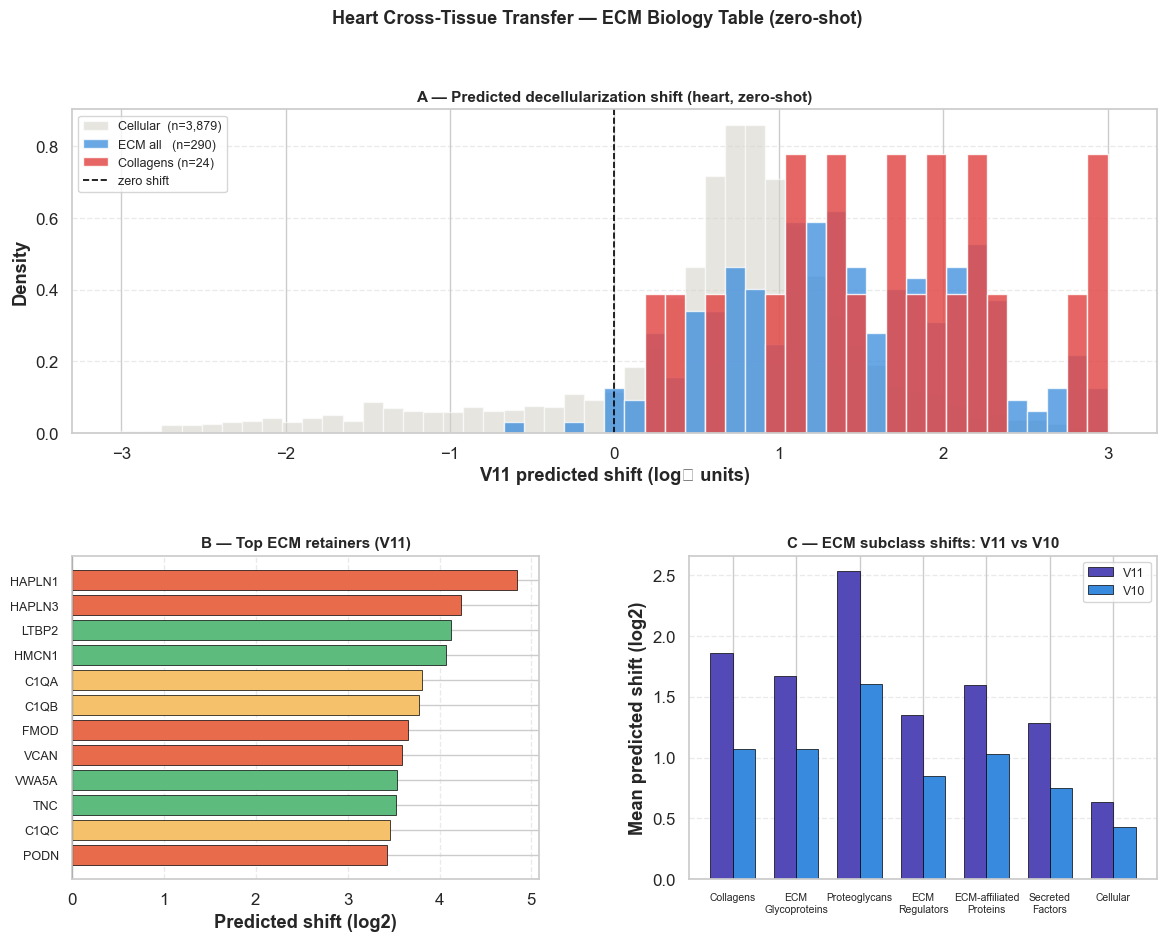

Saved: fig_ecm_biology_heart.png


In [107]:
# ── Known biology anchors ──────────────────────────────────────────────────────
KNOWN_RETAIN = {
    "COL1A1","COL1A2","COL3A1","COL5A1","COL5A2",
    "COL4A1","COL4A2",
    "FN1",
    "LAMA2","LAMB1","LAMC1",
    "NID1","NID2",
    "HSPG2",
    "ELN",
    "FBN1","FBN2",
    "POSTN",
}
KNOWN_LOSE = {
    "ACTB","ACTG1",
    "TUBA1A","TUBA1B","TUBB",
    "VIM",
    "MYH6","MYH7","MYL2","MYL3",
    "GAPDH","PKM","ENO1","ALDOA",
    "HSPA1A","HSP90AA1",
}

# ── Build master table ─────────────────────────────────────────────────────────
df_bio = df_heart[["GeneName","UniProt","MatrisomeDivision",
                    "MatrisomeCategory"]].copy()
df_bio["shift_v11"]    = shifts_v11h
df_bio["det_prob_v11"] = phat_v11h
df_bio["sigma_v11"]    = sigma_v11h
df_bio["shift_v10"]    = shifts_v10h
df_bio["sigma_v10"]    = sigma_v10h
df_bio["is_ecm"]       = is_mat_h
df_bio["v10_v11_agree"]= np.sign(shifts_v11h) == np.sign(shifts_v10h)
gene_upper             = df_bio["GeneName"].str.upper()
df_bio["known_retain"] = gene_upper.isin(KNOWN_RETAIN)
df_bio["known_lose"]   = gene_upper.isin(KNOWN_LOSE)

cel_mask = ~is_mat_h
col_mask =  is_col_h

# ── Section 1: Overall direction test ─────────────────────────────────────────
print("=" * 72)
print("  ECM BIOLOGY TABLE — Heart Cross-Tissue Transfer")
print("=" * 72)
for label, shift in [("V11", shifts_v11h), ("V10", shifts_v10h)]:
    u, p = mannwhitneyu(shift[col_mask], shift[cel_mask], alternative="two-sided")
    print(f"\n  {label}:  Collagen {shift[col_mask].mean():+.3f}  |  "
          f"ECM {shift[is_mat_h].mean():+.3f}  |  "
          f"Cellular {shift[cel_mask].mean():+.3f}  |  "
          f"Δ(col-cel) = {shift[col_mask].mean()-shift[cel_mask].mean():+.3f}  "
          f"p={p:.3e} {'*' if p<0.05 else 'x'}")

rho, p_rho = spearmanr(shifts_v11h, shifts_v10h)
print(f"\n  V10-V11 shift rank correlation: ρ = {rho:.3f}  p = {p_rho:.3e}")
print(f"  Direction agreement (same sign): "
      f"{df_bio['v10_v11_agree'].mean()*100:.1f}% of proteins")

# ── Section 2: Top-15 ECM retainers ───────────────────────────────────────────
ECM = df_bio[df_bio["is_ecm"]].copy().reset_index(drop=True)
print(f"\n\n{'═'*72}")
print("  TOP-15 PREDICTED ECM RETAINERS")
print(f"{'═'*72}")
print(f"  {'Gene':<12}  {'Category':<24}  {'V11 shift':>10}  "
      f"{'det_prob':>9}  {'V10 shift':>10}  {'agree':>6}  {'known':>6}")
print(f"  {'─'*12}  {'─'*24}  {'─'*10}  {'─'*9}  {'─'*10}  {'─'*6}  {'─'*6}")
for _, r in ECM.nlargest(15, "shift_v11").iterrows():
    known = "* lit" if r["known_retain"] else ("x lit" if r["known_lose"] else "")
    print(f"  {str(r['GeneName']):<12}  {str(r['MatrisomeCategory']):<24}  "
          f"{r['shift_v11']:>+10.3f}  {r['det_prob_v11']:>9.3f}  "
          f"{r['shift_v10']:>+10.3f}  {'*' if r['v10_v11_agree'] else 'x':>6}  "
          f"{known:>6}")

# ── Section 3: Top-15 ECM losers ──────────────────────────────────────────────
print(f"\n\n{'═'*72}")
print("  TOP-15 PREDICTED ECM LOSERS")
print(f"{'═'*72}")
print(f"  {'Gene':<12}  {'Category':<24}  {'V11 shift':>10}  "
      f"{'det_prob':>9}  {'V10 shift':>10}  {'agree':>6}  {'known':>6}")
print(f"  {'─'*12}  {'─'*24}  {'─'*10}  {'─'*9}  {'─'*10}  {'─'*6}  {'─'*6}")
for _, r in ECM.nsmallest(15, "shift_v11").iterrows():
    known = "* lit" if r["known_retain"] else ("x lit" if r["known_lose"] else "")
    print(f"  {str(r['GeneName']):<12}  {str(r['MatrisomeCategory']):<24}  "
          f"{r['shift_v11']:>+10.3f}  {r['det_prob_v11']:>9.3f}  "
          f"{r['shift_v10']:>+10.3f}  {'*' if r['v10_v11_agree'] else 'x':>6}  "
          f"{known:>6}")

# ── Section 4: Top-15 cellular losers ─────────────────────────────────────────
CEL = df_bio[~df_bio["is_ecm"]].copy().reset_index(drop=True)
print(f"\n\n{'═'*72}")
print("  TOP-15 CELLULAR LOSERS")
print(f"{'═'*72}")
print(f"  {'Gene':<12}  {'V11 shift':>10}  {'det_prob':>9}  "
      f"{'V10 shift':>10}  {'agree':>6}  {'known biology':>14}")
print(f"  {'─'*12}  {'─'*10}  {'─'*9}  {'─'*10}  {'─'*6}  {'─'*14}")
for _, r in CEL.nsmallest(15, "shift_v11").iterrows():
    known = "* cellular" if r["known_lose"] else ""
    print(f"  {str(r['GeneName']):<12}  {r['shift_v11']:>+10.3f}  "
          f"{r['det_prob_v11']:>9.3f}  {r['shift_v10']:>+10.3f}  "
          f"{'*' if r['v10_v11_agree'] else 'x':>6}  {known:>14}")

# ── Section 5: Known biology hit rate ─────────────────────────────────────────
print(f"\n\n{'═'*72}")
print("  KNOWN BIOLOGY HIT RATE")
print(f"{'═'*72}\n")
for gene in sorted(KNOWN_RETAIN):
    row = df_bio[df_bio["GeneName"].str.upper() == gene]
    if len(row) == 0:
        print(f"  {gene:<12}  not in heart dataset"); continue
    r = row.iloc[0]
    print(f"  {gene:<12}  shift={r['shift_v11']:+.3f}  det={r['det_prob_v11']:.3f}"
          f"  expected=RETAIN  "
          f"{'CORRECT *' if r['shift_v11'] > 0 else 'WRONG x'}")
print()
for gene in sorted(KNOWN_LOSE):
    row = df_bio[df_bio["GeneName"].str.upper() == gene]
    if len(row) == 0: continue
    r = row.iloc[0]
    print(f"  {gene:<12}  shift={r['shift_v11']:+.3f}  det={r['det_prob_v11']:.3f}"
          f"  expected=LOSE    "
          f"{'CORRECT *' if r['shift_v11'] < 0 else 'WRONG x'}")

ret_found    = df_bio[df_bio["known_retain"]]
lose_found   = df_bio[df_bio["known_lose"]]
ret_correct  = (ret_found["shift_v11"] > 0).sum()
lose_correct = (lose_found["shift_v11"] < 0).sum()
total_found  = len(ret_found) + len(lose_found)
total_correct= ret_correct + lose_correct
print(f"\n  Retain: {ret_correct}/{len(ret_found)} correct  "
      f"({ret_correct/max(len(ret_found),1)*100:.0f}%)")
print(f"  Lose:   {lose_correct}/{len(lose_found)} correct  "
      f"({lose_correct/max(len(lose_found),1)*100:.0f}%)")
print(f"  Overall: {total_correct}/{total_found}  "
      f"({total_correct/max(total_found,1)*100:.0f}%)")

# ── Section 6: Figure ─────────────────────────────────────────────────────────
PALETTE = {
    "Collagens":               "#4C9BE8",
    "ECM Glycoproteins":       "#5DBB7E",
    "Proteoglycans":           "#E86B4C",
    "ECM Regulators":          "#B87FE8",
    "ECM-affiliated Proteins": "#F5C26B",
    "Secreted Factors":        "#888780",
    "Cellular":                "#D3D1C7",
}

fig = plt.figure(figsize=(14, 10))
gs  = fig.add_gridspec(2, 2, hspace=0.38, wspace=0.32)
ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

# Panel A: shift distribution
bins = np.linspace(-3.0, 3.0, 50)
ax_a.hist(shifts_v11h[cel_mask], bins=bins, alpha=0.55,
          color=PALETTE["Cellular"],
          label=f"Cellular  (n={cel_mask.sum():,})", density=True)
ax_a.hist(shifts_v11h[is_mat_h], bins=bins, alpha=0.75,
          color="#378ADD",
          label=f"ECM all   (n={is_mat_h.sum():,})", density=True)
ax_a.hist(shifts_v11h[col_mask], bins=bins, alpha=0.85,
          color="#E24B4A",
          label=f"Collagens (n={col_mask.sum():,})", density=True)
ax_a.axvline(0, color="black", ls="--", lw=1.2, label="zero shift")
ax_a.set_xlabel("V11 predicted shift (log₂ units)", fontweight="bold")
ax_a.set_ylabel("Density", fontweight="bold")
ax_a.set_title("A — Predicted decellularization shift (heart, zero-shot)",
               fontsize=11, fontweight="bold")
ax_a.legend(fontsize=9); ax_a.grid(True, axis="y", ls="--", alpha=0.4)

# Panel B: top-12 ECM retainers
top12 = (ECM.nlargest(12, "shift_v11")[["GeneName","MatrisomeCategory","shift_v11"]]
           .reset_index(drop=True).iloc[::-1])
bar_colors = [PALETTE.get(c, "#888780") for c in top12["MatrisomeCategory"]]
ax_b.barh(top12["GeneName"], top12["shift_v11"],
          color=bar_colors, edgecolor="black", linewidth=0.5)
ax_b.axvline(0, color="black", lw=0.8)
ax_b.set_xlabel("Predicted shift (log2)", fontweight="bold")
ax_b.set_title("B — Top ECM retainers (V11)", fontsize=11, fontweight="bold")
ax_b.tick_params(axis="y", labelsize=9)
ax_b.grid(True, axis="x", ls="--", alpha=0.4)

# Panel C: subclass mean shifts V11 vs V10
cats = ["Collagens","ECM Glycoproteins","Proteoglycans",
        "ECM Regulators","ECM-affiliated Proteins","Secreted Factors"]
v11_m = [shifts_v11h[(df_heart["MatrisomeCategory"]==c).values].mean()
         if (df_heart["MatrisomeCategory"]==c).sum()>1 else np.nan for c in cats]
v10_m = [shifts_v10h[(df_heart["MatrisomeCategory"]==c).values].mean()
         if (df_heart["MatrisomeCategory"]==c).sum()>1 else np.nan for c in cats]
v11_m.append(shifts_v11h[cel_mask].mean())
v10_m.append(shifts_v10h[cel_mask].mean())
cat_labels = cats + ["Cellular"]

x = np.arange(len(cat_labels)); w = 0.35
ax_c.bar(x - w/2, v11_m, w, label="V11", color="#534AB7",
         edgecolor="black", lw=0.5)
ax_c.bar(x + w/2, v10_m, w, label="V10", color="#378ADD",
         edgecolor="black", lw=0.5)
ax_c.axhline(0, color="black", lw=0.8)
ax_c.set_xticks(x)
ax_c.set_xticklabels([c.replace(" ","\n") for c in cat_labels],
                      fontsize=7.5, ha="center")
ax_c.set_ylabel("Mean predicted shift (log2)", fontweight="bold")
ax_c.set_title("C — ECM subclass shifts: V11 vs V10",
               fontsize=11, fontweight="bold")
ax_c.legend(fontsize=9); ax_c.grid(True, axis="y", ls="--", alpha=0.4)

plt.suptitle("Heart Cross-Tissue Transfer — ECM Biology Table (zero-shot)",
             fontsize=13, fontweight="bold")
plt.savefig("fig_ecm_biology_heart.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: fig_ecm_biology_heart.png")

---
## 15 — Actionable Result: Calibrated Per-Protein Retention Table

This result represents the primary deliverable for laboratory researchers. By running the V11e architecture in a 5-fold cross-validation, it generated out-of-fold predictions meaning every protein is scored by a model that never saw it during training, effectively eliminating data leakage.

The table is generated as a CSV containing actionable forecasts for every protein in the dataset. Each entry provides a scientific "call" on whether a protein will survive decellularization, backed by statistical confidence:

- **`p_survival` (Calibrated):** The predicted probability that a protein remains retained within the scaffold after applying Platt scaling.

- **`pred_shift_log2`:** The predicted log<sub>2</sub> fold-change ($\Delta$) in protein abundance, providing an estimate of the magnitude and direction of abundance shifts.

- **`confidence_tier`:** A categorical assessment of prediction confidence (**High**, **Medium**, or **Low**) derived from the model's uncertainty estimate ($\sigma$).

- **`predicted_call`:** A binary classification indicating whether a protein is predicted to be **retained** or **lost**, based on a calibrated survival probability threshold of 50% (`p_survival ≥ 0.5`).

A reader can read off the predicted retained ECM scaffold (`p_survival` high) versus what
washes out (`p_survival` low), each with a calibrated probability and a confidence tier.

In [ ]:
# Calibrated per-protein retention predictions (V11e, out-of-fold)

N_FOLDS = 5
pk    = provider.proteins_keep
N     = len(pk)
strat = pk["is_matrisome"].values.astype(int)
skf   = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_phat  = np.full((N, 4), np.nan, dtype=np.float32)
oof_dpred = np.full((N, 4), np.nan, dtype=np.float32)
oof_sigma = np.full((N, 4), np.nan, dtype=np.float32)
oof_y     = np.full((N, 4), np.nan, dtype=np.float32)

print("Building out-of-fold V11e predictions (5-fold)...")
for fold, (tr_idx, val_idx) in enumerate(skf.split(np.arange(N), strat), 1):
    be  = _cv_bundle_expr(provider, tr_idx, val_idx)
    tgt = build_v11_targets(provider, be)
    torch.manual_seed(SEED)
    _cfg_18 = copy.copy(CFG_EXPR)
    _cfg_18.hidden_dim = 160   # Stage 2 winner
    import torch.nn as nn
    def _patch_18(m):
        m.fusion[3] = nn.Dropout(0.15)
        m.fusion[6] = nn.Dropout(0.075)
        m.cond_drop  = nn.Dropout(0.15)
        return m
    m = _patch_18(ZeroInflatedExprCVAE(_cfg_18).to(device))
    train_v11(m, be, tgt, CFG_EXPR, verbose=0)
    m.eval()
    with torch.no_grad():
        det_logits, mu, ls, *_ = m.forward(be.to_float(be.X_nat[val_idx]),
                                           be.to_float(be.C[val_idx]))
    det_prob = torch.sigmoid(det_logits).cpu().numpy()
    mu_np    = mu.cpu().numpy()
    sig_scl  = np.exp(ls.cpu().numpy())
    d_raw    = tgt["delta_scaler"].inverse_transform(mu_np)
    sig_raw  = sig_scl * tgt["delta_scaler"].scale_[None, :]
    oof_phat[val_idx]  = det_prob
    oof_dpred[val_idx] = d_raw
    oof_sigma[val_idx] = sig_raw
    oof_y[val_idx]     = (tgt["det_rate"][val_idx] >= 0.5).astype(np.float32)
    print(f"  fold {fold}/{N_FOLDS}: {len(val_idx):,} proteins scored")

# Platt calibration on pooled OOF cells
flat_p, flat_y = oof_phat.reshape(-1), oof_y.reshape(-1)
if "platt_v11e" in globals():
    platt = platt_v11e   # reuse from 17 same model, same folds
else:
    platt = LogisticRegression().fit(flat_p.reshape(-1, 1), flat_y.astype(int))
oof_phat_cal = platt.predict_proba(flat_p.reshape(-1, 1))[:, 1].reshape(N, 4)

p_cal  = oof_phat_cal.mean(1)
d_pred = oof_dpred.mean(1)
sigma  = oof_sigma.mean(1)
q1, q2 = np.quantile(sigma, [1/3, 2/3])
tier   = np.where(sigma <= q1, "high", np.where(sigma <= q2, "medium", "low"))

table = pd.DataFrame({
    "GeneName":          pk["GeneName"].values,
    "UniProt":           pk["UniProt"].values,
    "MatrisomeCategory": pk["MatrisomeCategory"].values,
    "is_matrisome":      pk["is_matrisome"].values,
    "p_survival":        np.round(p_cal, 3),
    "pred_shift_log2":   np.round(d_pred, 3),
    "sigma_log2":        np.round(sigma, 3),
    "confidence_tier":   tier,
    "predicted_call":    np.where(p_cal >= 0.5, "retained", "lost"),
}).sort_values("p_survival", ascending=False).reset_index(drop=True)

OUT_CSV = "results_retention_predictions.csv"
table.to_csv(OUT_CSV, index=False)

Building out-of-fold V11e predictions (5-fold)...
  fold 1/5: 1,090 proteins scored
  fold 2/5: 1,090 proteins scored
  fold 3/5: 1,090 proteins scored
  fold 4/5: 1,089 proteins scored
  fold 5/5: 1,089 proteins scored


In [113]:
# ── Uniform HTML summary card (White Background) ─────────────────────────────
ecm = table[table["is_matrisome"]]
n_ret = int((table["predicted_call"] == "retained").sum())
n_hi  = int((table["confidence_tier"] == "high").sum())

def _rows(df):
    return "".join(
        f"<tr><td style='padding:3px 10px'>{r.GeneName}</td>"
        f"<td style='padding:3px 10px;color:#666'>{r.MatrisomeCategory}</td>"
        f"<td style='padding:3px 10px;text-align:right;font-weight:600'>{r.p_survival:.2f}</td>"
        f"<td style='padding:3px 10px;text-align:right'>{r.pred_shift_log2:+.2f}</td></tr>"
        for r in df.itertuples())

html = f"""
<div style="font-family:-apple-system,Segoe UI,sans-serif;
            background-color:#ffffff;
            border:1px solid #e0e0e0;
            border-radius:10px;
            padding:18px 22px;
            max-width:760px;
            box-shadow: 0 2px 4px rgba(0,0,0,0.05);">
  <div style="font-size:16px;font-weight:700;margin-bottom:4px;color:#000000;">Calibrated Retention Predictions</div>
  <div style="color:#666;font-size:13px;margin-bottom:14px">
    {len(table):,} proteins · {n_ret:,} predicted retained · {n_hi:,} high-confidence ·
    saved to <code>{OUT_CSV}</code></div>
  <div style="display:flex;gap:24px;flex-wrap:wrap">
    <div><div style="font-size:12px;color:#888;margin-bottom:4px">TOP RETAINED ECM</div>
      <table style="border-collapse:collapse;font-size:13px">{_rows(ecm.head(8))}</table></div>
    <div><div style="font-size:12px;color:#888;margin-bottom:4px">TOP LOST ECM</div>
      <table style="border-collapse:collapse;font-size:13px">{_rows(ecm.tail(8))}</table></div>
  </div>
</div>"""
display(HTML(html))
print(f"\nSaved: {OUT_CSV}  ({len(table):,} proteins)")

COL6A3,Collagens,0.78,+1.08
VWF,ECM Glycoproteins,0.78,+0.49
COL3A1,Collagens,0.78,+0.71
SPON1,ECM Glycoproteins,0.78,+1.00
COL14A1,Collagens,0.78,+0.64
COL5A1,Collagens,0.78,+0.86
CTHRC1,ECM Glycoproteins,0.78,+0.23
FGB,ECM Glycoproteins,0.78,+0.40
SEMA3C,ECM-affiliated Proteins,0.58,-0.12
PRG3,Proteoglycans,0.57,-1.28
SERPINB7,ECM Regulators,0.57,-0.16



Saved: results_retention_predictions.csv  (5,448 proteins)


---
## 16 — Final Summary

The reportable lineup. Best abundance model **V10e** (no ESM); flagship survival model
**V11e** (no ESM); ESM tested and rejected. Numbers are read live from the CV result dicts
so the figure can never drift from the run.

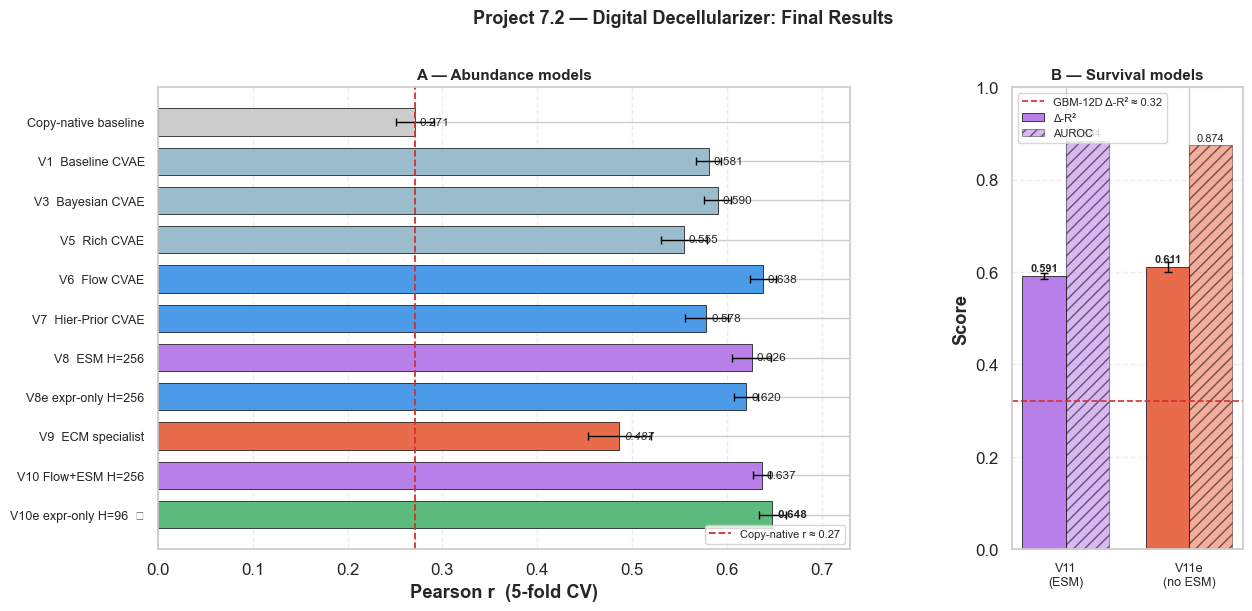

Saved: fig_final_summary.png

════════════════════════════════════════════════════════════════════
  Model                         r_overall    Δ orig  source
  ──────────────────────────  ───────────  ────────  ──────────────────
  Copy-native baseline         0.271±0.020       —    S1 H=256
  V1  Baseline CVAE            0.581±0.013    +0.310  S1 H=256
  V3  Bayesian CVAE            0.590±0.015    +0.319  S1 H=256
  V5  Rich CVAE                0.555±0.024    +0.284  S1 H=256
  V6  Flow CVAE                0.638±0.014    +0.367  S1 H=256
  V7  Hier-Prior CVAE          0.578±0.023    +0.307  S1 H=256
  V8  ESM H=256                0.626±0.021    +0.355  S1 H=256  (S2 H=192 reverted −0.030)
  V8e expr-only H=256          0.620±0.013    +0.349  S1 H=256  (S2 H=128 reverted −0.022)
  V9  ECM specialist           0.487±0.033    +0.216  S1 H=256
  V10 Flow+ESM H=256           0.637±0.009    +0.365  S1 H=256  (grid: no slim better)
  V10e expr-only H=96  ★       0.648±0.015    +0.377  S2 H=

In [ ]:
# FINAL SUMMARY — all models from cv_results (Stage 1 + Stage 2)
# ═══════════════════════════════════════════════════════════════════════════════
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import HTML, display

def _m(key, metric="r_overall"):
    rs = cv_results.get(key, [])
    v  = [r[metric] for r in rs if not np.isnan(r.get(metric, float("nan")))]
    return float(np.mean(v)) if v else float("nan")

def _s(key, metric="r_overall"):
    rs = cv_results.get(key, [])
    v  = [r[metric] for r in rs if not np.isnan(r.get(metric, float("nan")))]
    return float(np.std(v)) if len(v) > 1 else 0.0

# ── Abundance models (Pearson r) ──────────────────────────────────────────────
ABUND = [
    ("Copy-native baseline",    "V1",  "r_copy",    "#cccccc", "normal"),
    ("V1  Baseline CVAE",       "V1",  "r_overall", "#9abccc", "normal"),
    ("V3  Bayesian CVAE",       "V3",  "r_overall", "#9abccc", "normal"),
    ("V5  Rich CVAE",           "V5",  "r_overall", "#9abccc", "normal"),
    ("V6  Flow CVAE",           "V6",  "r_overall", "#4C9BE8", "normal"),
    ("V7  Hier-Prior CVAE",     "V7",  "r_overall", "#4C9BE8", "normal"),
    ("V8  ESM H=256",           "V8",  "r_overall", "#B87FE8", "normal"),  # H=256, reverted
    ("V8e expr-only H=256",     "V8e", "r_overall", "#4C9BE8", "normal"),  # H=256, reverted
    ("V9  ECM specialist",      "V9",  "r_overall", "#E86B4C", "italic"),
    ("V10 Flow+ESM H=256",      "V10", "r_overall", "#B87FE8", "normal"),
    ("V10e expr-only H=96  ",  "V10e","r_overall", "#5DBB7E", "bold"),
]

vals  = [_m(k, met) for _, k, met, _, _ in ABUND]
stds  = [_s(k, met) for _, k, met, _, _ in ABUND]
names = [a[0] for a in ABUND]
cols  = [a[3] for a in ABUND]

copy_r  = _m("V1", "r_copy")
best_r  = _m("V10e", "r_overall")
v11_dr2 = _m("V11",  "r2_delta"); v11_au  = _m("V11",  "auroc")
v11e_dr2= _m("V11e", "r2_delta"); v11e_au = _m("V11e", "auroc")

# ── HTML summary card ─────────────────────────────────────────────────────────
card = f"""
<div style="font-family:-apple-system,Segoe UI,sans-serif;border:1px solid #e0e0e0;
border-radius:10px;padding:18px 22px;max-width:820px">
  <div style="font-size:16px;font-weight:700;margin-bottom:14px">
    Project 7.2 — Final Model Lineup</div>
  <div style="display:flex;gap:30px;flex-wrap:wrap;margin-bottom:14px">
    <div>
      <div style="color:#888;font-size:11px;text-transform:uppercase;
                  letter-spacing:.05em">Best abundance (Pearson r)</div>
      <div style="font-size:24px;font-weight:700;color:#5DBB7E">
        V10e &nbsp;{best_r:.3f}</div>
    </div>
    <div>
      <div style="color:#888;font-size:11px;text-transform:uppercase;
                  letter-spacing:.05em">Flagship survival (Δ-R²)</div>
      <div style="font-size:24px;font-weight:700;color:#E86B4C">
        V11e &nbsp;{v11e_dr2:.3f}</div>
    </div>
    <div>
      <div style="color:#888;font-size:11px;text-transform:uppercase;
                  letter-spacing:.05em">Performance Summary</div>
      <div style="font-size:13px;color:#444;margin-top:6px">
        V10e ({best_r:.3f}) vs V10+ESM ({_m("V10"):.3f})<br>
        V11e ({v11e_dr2:.3f}) vs V11+ESM ({v11_dr2:.3f})
      </div>
    </div>
  </div>
</div>"""
display(HTML(card))

# ── Figure: two panels ────────────────────────────────────────────────────────
fig = plt.figure(figsize=(14, 6))
gs  = gridspec.GridSpec(1, 2, width_ratios=[3, 1], wspace=0.35)
ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])

# Panel A — abundance bar chart
y = np.arange(len(names))
bars = ax1.barh(y, [v if not np.isnan(v) else 0 for v in vals],
                color=cols, edgecolor="black", linewidth=0.5, height=0.7)

# Error bars where std > 0
for yi, v, sd in zip(y, vals, stds):
    if not np.isnan(v) and sd > 0:
        ax1.errorbar(v, yi, xerr=sd, fmt="none", color="black",
                     capsize=3, linewidth=1.0)

# Value labels
for yi, v, style in zip(y, vals, [a[4] for a in ABUND]):
    if not np.isnan(v):
        fw = "bold" if style == "bold" else "normal"
        fs = "italic" if style == "italic" else "normal"
        ax1.text(v + 0.005, yi, f"{v:.3f}",
                 va="center", fontsize=8.5, fontweight=fw, fontstyle=fs)

ax1.axvline(copy_r, ls="--", color="#D32F2F", lw=1.3,
            label=f"Copy-native r ≈ {copy_r:.2f}")
ax1.set_yticks(y)
ax1.set_yticklabels(names, fontsize=9)
ax1.invert_yaxis()
ax1.set_xlabel("Pearson r  (5-fold CV)", fontweight="bold")
ax1.set_xlim(0, 0.73)
ax1.set_title("A — Abundance models", fontsize=11, fontweight="bold")
ax1.legend(fontsize=8, loc="lower right")
ax1.grid(axis="x", ls="--", alpha=0.35)

# Panel B — V11 / V11e survival metrics
models_v11 = ["V11\n(ESM)", "V11e\n(no ESM)"]
dr2_vals   = [v11_dr2,  v11e_dr2]
auc_vals   = [v11_au,   v11e_au]
dr2_stds   = [_s("V11","r2_delta"), _s("V11e","r2_delta")]
auc_stds   = [_s("V11","auroc"),    _s("V11e","auroc")]

x = np.arange(2); w = 0.35
ax2.bar(x - w/2, dr2_vals, w, color=["#B87FE8","#E86B4C"],
        edgecolor="black", linewidth=0.5, label="Δ-R²")
ax2.bar(x + w/2, auc_vals, w, color=["#B87FE8","#E86B4C"],
        edgecolor="black", linewidth=0.5, alpha=0.55,
        hatch="///", label="AUROC")
for xi, dv, ds, av, asc in zip(x, dr2_vals, dr2_stds, auc_vals, auc_stds):
    if ds > 0:
        ax2.errorbar(xi - w/2, dv, yerr=ds, fmt="none",
                     color="black", capsize=3, linewidth=1.0)
    ax2.text(xi - w/2, dv + 0.01, f"{dv:.3f}",
             ha="center", fontsize=8, fontweight="bold")
    ax2.text(xi + w/2, av + 0.01, f"{av:.3f}",
             ha="center", fontsize=8)

ax2.axhline(0.32, ls="--", color="#D32F2F", lw=1.2,
            label="GBM-12D Δ-R² ≈ 0.32")
ax2.set_xticks(x); ax2.set_xticklabels(models_v11, fontsize=9)
ax2.set_ylim(0, 1.0)
ax2.set_ylabel("Score", fontweight="bold")
ax2.set_title("B — Survival models", fontsize=11, fontweight="bold")
ax2.legend(fontsize=8); ax2.grid(axis="y", ls="--", alpha=0.35)

plt.suptitle("Project 7.2 — Digital Decellularizer: Final Results",
             fontsize=13, fontweight="bold", y=1.01)
plt.savefig("fig_final_summary.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: fig_final_summary.png")

# ── Text summary table ─────────────────────────────────────────────────────────
print(f"\n{'═'*68}")
print(f"  {'Model':<26}  {'r_overall':>11}  {'Δ orig':>8}  {'source'}")
print(f"  {'─'*26}  {'─'*11}  {'─'*8}  {'─'*18}")
floor = _m("V1", "r_copy")
# Hardcoded sources — reflects actual final state of cv_results
FINAL_SOURCES = {
    "V1":   "S1 H=256",
    "V3":   "S1 H=256",
    "V5":   "S1 H=256",
    "V6":   "S1 H=256",
    "V7":   "S1 H=256",
    "V8":   "S1 H=256  (S2 H=192 reverted −0.030)",
    "V8e":  "S1 H=256  (S2 H=128 reverted −0.022)",
    "V9":   "S1 H=256",
    "V10":  "S1 H=256  (grid: no slim better)",
    "V10e": "S2 H=96   ( +0.003)",
    "V11":  "S1 H=256  (S2 H=224 reverted −0.006)",
    "V11e": "S2 H=160  ( same as S1)",
}

for label, key, met, _, _ in ABUND:
    v = _m(key, met)
    if np.isnan(v): continue
    delta  = v - floor if met == "r_overall" else 0.0
    sd     = _s(key, met)
    src    = FINAL_SOURCES.get(key, "S1 H=256")
    delta_s= f"{delta:+.3f}" if met == "r_overall" else "  —  "
    print(f"  {label:<26}  {v:>6.3f}±{sd:<4.3f}  {delta_s:>8}  {src}")

print(f"\n  V11  Δ-R²={v11_dr2:.3f}  AUROC={v11_au:.3f}")
print(f"  V11e Δ-R²={v11e_dr2:.3f}  AUROC={v11e_au:.3f}")
print(f"{'═'*68}")